<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_03_Statistical_Experiments_and_Significance_Testing/Chapter_03_Statistical_Experiments_and_Significance_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 3 — Statistical Experiments and Significance Testing

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced with an analysis of every output, and extra experiments written for this notebook |

## Chapter overview

Chapter 2 measured how much a statistic varies from sample to sample. Chapter 3 uses that variation to answer the question that experiments exist for: **is the difference that we see real, or could chance have produced it?** The chapter follows the logic of an experiment. It begins with the design (the **A/B test**, where units are assigned at random to two treatments), then states the question as a **hypothesis test** and answers it with **resampling** (the permutation test), which leads to the **p-value**, the statistical significance, and the two kinds of error. Next come the classical tests, the **$t$-test**, the **analysis of variance (ANOVA)** for several groups and the **chi-square test** for counts, and the problems that arise when many tests are made (**multiple testing**) and what **degrees of freedom** mean. The chapter closes with two practical topics: the **multi-arm bandit**, which allocates traffic adaptively, and **power and sample size**, how much data an experiment needs.

### Sections of this chapter

| # | Section of the book | Python code in the book | What this notebook adds |
|---|---|---|---|
| 1 | A/B testing | no code | randomization against self-selection, the false-positive rate of A/A tests, the cost of peeking at the results |
| 2 | Hypothesis tests | no code | one- and two-sided p-values from one permutation distribution, the permutation test with unequal variances |
| 3 | Resampling | permutation test of the session times | an exact test, the Monte Carlo error of a permutation p-value, permutation against bootstrap, $t$ and rank tests, other statistics |
| 4 | Statistical significance and p-values | permutation test of the conversion rates, $\chi^2$ test | the exact p-value, type I and type II error by simulation, the distribution of p-values, what a p-value does not say, significance against importance |
| 5 | $t$-tests | two $t$-tests of the session times | the Welch statistic by hand, pooled against Welch, $t$ against rank tests, paired against independent |
| 6 | Multiple testing | no code | the chance of a false positive among many tests, Bonferroni, Holm and Benjamini-Hochberg |
| 7 | Degrees of freedom | no code | why $n-1$, the degrees of freedom of the ANOVA table, the dummy-variable trap |
| 8 | ANOVA | permutation test of four pages, the $F$ table | the $F$ statistic by hand, a permutation test on $F$, pairwise comparisons, a two-way ANOVA |
| 9 | Chi-square test | click rates, resampling and the $\chi^2$ test, the Imanishi digits | the statistic by hand, the exact test, two resampling schemes, a goodness-of-fit test of digits |
| 10 | Multi-arm bandit algorithm | no code | epsilon-greedy and Thompson sampling against a fixed split, regret |
| 11 | Power and sample size | sample sizes for two conversion rates | the sample size by five methods and by simulation, power curves, the exaggeration of significant effects |

### How to read this notebook

Every section has the same structure:

1. **Summary** — what the book says, condensed in my own words (the book itself is not quoted).
2. **Theory** — the ideas behind it: definitions, math and the reasons that make a method behave as it does.
3. **Book code** — the official Python code of the chapter, reproduced and executed, followed by an **output analysis**.
4. **Extra** — experiments written for this notebook. They are *not* part of the book. They are lettered (a), (b), ... inside each section and cited with the section number, as in 3(b).

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository, `# EXTRA` for code written for this notebook (the setup cell is labelled `# SETUP` and is not part of the book). The book's code is reproduced as it is; where it needs a change to run in a notebook, the change is marked in the cell with `# CHANGED`. The resampling code of the official script uses Python's `random` module and NumPy's generator without a seed in several cells; the cells that do so start with a line `random.seed(...)  # NOT IN THE BOOK` (or `np.random.seed(...)`), so that every run gives the same output. The extra experiments use their own random generators and never touch the global ones.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). The four files of this chapter are tiny: `web_page_data.csv` (the session times on two web pages), `four_sessions.csv` (four pages), `click_rates.csv` (clicks on three headlines) and `imanishi_data.csv` (the frequencies of digits).

The setup cell also prints the versions of the libraries, because the code of the book was written for older ones, and sets a quiet plotting style (it is global, so it also applies to the figures of the book code).

In [1]:
# SETUP
import platform
import urllib.request
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import statsmodels

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"statsmodels  : {statsmodels.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("web_page_data.csv", "four_sessions.csv", "click_rates.csv", "imanishi_data.csv")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) --------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
NumPy        : 2.5.4
pandas       : 3.1.0
SciPy        : 1.16.3
statsmodels  : 0.15.0
Matplotlib   : 3.11.2


---
## 1. A/B testing

*Book section: "A/B Testing". The section has no code; the experiment of the chapter, the session times on two web pages, appears in section 3.*

### Summary

* In an **A/B test** the subjects are split **at random** into two groups and each group gets one of two versions of something (a page design, a price, a drug, a fertilizer); the results of the groups decide which version is better. When one version is the status quo, or nothing at all, it is the **control** and the other one the **treatment**. The subjects can be visitors of a web site, patients or plots of land; typical questions are which price, headline or page layout gives more clicks, purchases or time on the page.
* **Random assignment** is what makes the comparison fair: it makes the groups alike in everything but the treatment, so that a difference in the result can be attributed to the treatment and not to a difference between the people.
* A good experiment has a **single, predefined metric** (the *test statistic*, such as the conversion rate), chosen before looking at the data. If many metrics are examined, one of them will differ by chance (section 6).
* Where possible the subjects, and the people who evaluate them, should not know who got which treatment (**blinding**), so that expectations do not influence the result.
* An A/B test needs a **contemporaneous control group**. A comparison with the past is not an experiment, because many things change with time.
* A test can also be run with more than two treatments (A/B/C/... tests); the principles are the same.

### Theory

**Potential outcomes.** Let each unit $i$ have two potential outcomes, $Y_i(0)$ if it receives the control and $Y_i(1)$ if it receives the treatment; only one of them is ever observed. The effect on the unit is $\tau_i = Y_i(1) - Y_i(0)$ and the **average treatment effect** is $\tau = \frac1N\sum_i\tau_i$ (Neyman, 1923; Rubin, 1974). If the assignment $Z_i \in \{0, 1\}$ is random and independent of the potential outcomes, the difference of the group means $\bar{Y}_T - \bar{Y}_C$ is an **unbiased** estimate of $\tau$. Without randomization the same difference equals $\tau$ plus a **selection bias**: the units that chose or were given the treatment would have had different outcomes anyway. Randomization removes this bias for all the variables that influence the outcome at once, including those that nobody has measured.

**What the design has to guard against.** The stable unit treatment value assumption (the outcome of a unit depends only on its own treatment, not on that of the others), contamination between the groups, a metric that was chosen after seeing the results, and **peeking**: looking at the result repeatedly and stopping as soon as it is significant, which raises the rate of false positives far above the nominal one (Armitage, McPherson and Rowe, 1969; extra 1(c)). An **A/A test**, in which both groups receive the same treatment, is a check of the whole machinery: about 5% of such tests should be "significant" at the 5% level (extra 1(b)).

**Randomization inference.** Fisher (1935) showed that the random assignment itself provides the reference distribution for a test: under the null hypothesis that the treatment has no effect on anybody (the *sharp null*), the outcomes would have been the same under any other assignment, and the distribution of the statistic over all possible assignments is the distribution under the null. The permutation test of section 3 is this idea in code.

### Extra experiments

This section has no code in the book. The experiments below show why the design matters and what can go wrong with a test of a perfectly sound design.

**(a) Randomization against self-selection.** 20,000 users have a hidden *engagement* level that raises their outcome (for example the time spent on the site). The new feature has a true, constant effect of +1. In an *observational* comparison the more engaged users are more likely to use the feature; in a *randomized* experiment a coin decides. The cell repeats each design 500 times and reports the difference of the group means.

In [2]:
# EXTRA (a): the same feature, an observational comparison and a randomized experiment
rng = np.random.default_rng(101)
n_users, true_effect, repetitions = 20_000, 1.0, 500
observational, randomized = [], []
for _ in range(repetitions):
    engagement = rng.normal(size=n_users)
    baseline = 10 + 2 * engagement + rng.normal(size=n_users)             # the outcome without the feature
    outcome_if_treated = baseline + true_effect
    uses = rng.random(n_users) < 1 / (1 + np.exp(-1.5 * engagement))      # engaged users adopt the feature more often
    observational.append(outcome_if_treated[uses].mean() - baseline[~uses].mean())
    coin = rng.random(n_users) < 0.5                                       # random assignment
    randomized.append(outcome_if_treated[coin].mean() - baseline[~coin].mean())
observational, randomized = np.array(observational), np.array(randomized)
print(f"true effect of the feature: {true_effect}")
print(pd.DataFrame({"mean of the estimates": [observational.mean(), randomized.mean()], "sd of the estimates": [observational.std(ddof=1), randomized.std(ddof=1)],
                    "bias": [observational.mean() - true_effect, randomized.mean() - true_effect]}, index=["observational", "randomized"]).round(3).to_string())

true effect of the feature: 1.0
               mean of the estimates  sd of the estimates   bias
observational                  3.119                0.028  2.119
randomized                     0.998                0.033 -0.002


**Analysis of extra (a).**

* In the **observational** comparison the difference of the group means averages 3.119 over the 500 repetitions, while the true effect is 1: a bias of +2.119, so the estimate is more than three times the effect. Its spread is small (standard deviation 0.028), so it is a precise but systematically wrong number. The bias equals the difference between the baselines (the outcome without the feature) of the users who adopt it and of those who do not: the adopters are the more engaged, so their baseline is higher by 2.1 on average. The comparison measures the effect of the feature *plus* the effect of being engaged, and a larger sample would not remove it.
* In the **randomized** experiment the estimates average 0.998 (bias -0.002) with a standard deviation of 0.033. The coin makes the two groups alike in the hidden engagement (and in everything else that nobody measured), so the difference of the means is an unbiased estimate of the effect.
* The two designs have about the same precision (0.028 and 0.033); what differs is the bias. This is the reason why the book's A/B test insists on random assignment.

**(b) An A/A test.** The 36 session times of the web-page data are pooled and treated as the population of sessions. 20,000 times, two groups of the sizes of the book's experiment (21 and 15 sessions) are drawn from it with replacement, so that there is no difference between them, and the Welch $t$-test is applied. The cell reports how often the test finds a "significant" difference at the 1%, 5% and 10% levels and draws the histogram of the p-values.

sessions: 36 (21 on page A, 15 on page B); 20,000 A/A tests
 level  share of significant tests
  0.01                      0.0102
  0.05                      0.0514
  0.10                      0.1004
share of the p-values in each tenth of (0, 1): [0.1, 0.103, 0.097, 0.101, 0.101, 0.101, 0.1, 0.097, 0.101, 0.099]


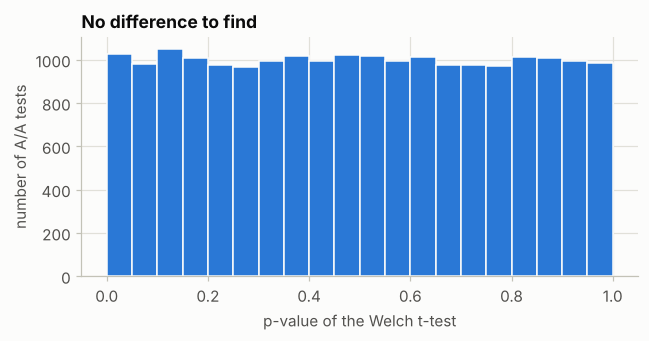

In [3]:
# EXTRA (b): A/A tests, the p-values of a test when there is nothing to find
from scipy import stats

session_times_aa = pd.read_csv(DATA / "web_page_data.csv")
pooled = 100 * session_times_aa["Time"].to_numpy()
n_a, n_b = (session_times_aa["Page"] == "Page A").sum(), (session_times_aa["Page"] == "Page B").sum()
rng = np.random.default_rng(102)
repetitions = 20_000
group_a = rng.choice(pooled, size=(repetitions, n_a))
group_b = rng.choice(pooled, size=(repetitions, n_b))
p_values = stats.ttest_ind(group_a, group_b, axis=1, equal_var=False).pvalue
print(f"sessions: {len(pooled)} ({n_a} on page A, {n_b} on page B); {repetitions:,} A/A tests")
print(pd.DataFrame({"level": [0.01, 0.05, 0.10], "share of significant tests": [np.mean(p_values < a) for a in (0.01, 0.05, 0.10)]}).round(4).to_string(index=False))
print(f"share of the p-values in each tenth of (0, 1): {np.round(np.histogram(p_values, bins=10, range=(0, 1))[0] / repetitions, 3).tolist()}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(p_values, bins=20, range=(0, 1), color=PALETTE[0], edgecolor=SURFACE)
ax.set_xlabel("p-value of the Welch t-test"); ax.set_ylabel("number of A/A tests")
ax.set_title("No difference to find")
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* With no difference between the groups the Welch test finds a "significant" difference in 1.02%, 5.14% and 10.04% of the 20,000 A/A tests at the 1%, 5% and 10% levels. The standard error of a rate near 5% is about 0.0015, so all three are within one standard error of the nominal levels.
* The p-values are spread evenly: each tenth of the interval (0, 1) holds between 9.7% and 10.3% of them and the histogram is flat. When there is nothing to find, a "significant" result is simply one of the lowest p-values, and it appears at the rate $\alpha$ that was chosen.
* The test behaves well here although the groups are small (21 and 15) and the times are skewed (they run from 21 to 357 seconds); section 5 shows that this is not so for every skewed distribution (the Welch test falls to 3.2% for lognormal data with 15 per group). An A/A test is a cheap check of the machinery of an experiment: if more than about 5% of A/A tests are significant, something in the setup is wrong.

**(c) The cost of peeking.** Two groups receive the same treatment and the results are monitored: a two-sided $z$ test at the 5% level is made after every block of 100 observations per group, up to 2,000 per group (20 looks), and the experiment is declared a success the first time that $|z| > 1.96$. 20,000 experiments are simulated. The cell reports the share of experiments that were *ever* declared a success if the number of equally spaced looks is 1, 2, 4, 5, 10 or 20, against the 5% of a test that is looked at only once.

In [4]:
# EXTRA (c): peeking at an A/A experiment and stopping when it first looks significant
rng = np.random.default_rng(103)
experiments, block, looks_max = 20_000, 100, 20
block_sums = rng.normal(scale=np.sqrt(2 * block), size=(experiments, looks_max))   # sum of the 100 differences (variance 2 each) of a block
running = block_sums.cumsum(axis=1)                                    # sum of the differences seen so far
sizes = block * np.arange(1, looks_max + 1)                            # observations per group so far
z = running / np.sqrt(2 * sizes)
rows = []
for looks in (1, 2, 4, 5, 10, 20):
    checked = z[:, (looks_max // looks) * np.arange(1, looks + 1) - 1]
    rows.append({"number of looks": looks, "ever significant": np.mean(np.any(np.abs(checked) > 1.96, axis=1)),
                 "significant at the end only": np.mean(np.abs(checked[:, -1]) > 1.96)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
bonferroni = stats.norm.ppf(1 - 0.05 / 2 / 10)
print(f"10 looks with the Bonferroni boundary |z| > {bonferroni:.3f}: ever significant {np.mean(np.any(np.abs(z[:, 1::2]) > bonferroni, axis=1)):.4f}")

 number of looks  ever significant  significant at the end only
               1            0.0492                       0.0492
               2            0.0812                       0.0492
               4            0.1246                       0.0492
               5            0.1395                       0.0492
              10            0.1882                       0.0492
              20            0.2464                       0.0492
10 looks with the Bonferroni boundary |z| > 2.807: ever significant 0.0249


**Analysis of extra (c).**

* A single look at the end of the experiment has the nominal rate: 4.92% of the experiments are significant (the standard error is 0.15 percentage points). With two looks the share of experiments that were *ever* declared a success is 8.1%, with 4 looks 12.5%, with 5 looks 14.0%, with 10 looks 18.8% and with 20 looks 24.6%: nearly five times the nominal 5%, although there is never any difference between the groups.
* The column "significant at the end only" is 4.92% in every row (it is the same final look): the inflation does not come from the final test but from the extra chances that earlier looks give.
* The rate is far below the 40% that 10 *independent* tests would give ($1 - 0.95^{10}$), because the looks use the same accumulating data and are strongly correlated. A Bonferroni boundary of $|z| > 2.807$ (the 5% divided by 10, section 6) brings the rate for 10 looks down to 2.49%, below the nominal 5%: the correction is conservative here for the same reason. Sequential designs use boundaries that spend the 5% more evenly. The simple rule: fix the sample size in advance and look at the result once, or use a method that is built for repeated looks.

---
## 2. Hypothesis tests

*Book section: "Hypothesis Tests" (with "The Null Hypothesis", "Alternative Hypothesis" and "One-Way Versus Two-Way Hypothesis Tests"). The section has no code.*

### Summary

* A **hypothesis test**, also called a significance test, asks whether an observed difference between groups could easily be due to chance. Human intuition is a poor judge of this: people tend to see patterns in random data, and the test is the discipline that guards against being fooled by randomness.
* The **null hypothesis** is the hypothesis that there is nothing but chance behind what is seen: the treatments are the same, the groups come from the same population. The **alternative hypothesis** is the one that the experimenter hopes to establish, for instance that treatment B is better than A. The test is built so that the null hypothesis is a clearly defined *chance model*, from which the probability of data as extreme as those observed can be computed.
* A **one-way** (one-tailed) test counts only extreme results in the direction that was predicted (B is better); a **two-way** (two-tailed) test counts extreme results in both directions. The choice has to be made *before* the data are seen, from the question that is being asked. Software defaults often assume the two-sided test; the one-sided test needs a reason to care about one direction only.
* The classical logic: assume that the null hypothesis is true, find out how unusual the observed result is, and reject the null hypothesis if it is very unusual.

### Theory

**The pieces of a test.** A hypothesis test has a **null hypothesis** $H_0$ that determines a probability model, a **test statistic** $T$ (a number computed from the data that measures the difference of interest), the **null distribution** of $T$ under $H_0$, and a rule that turns the observed value $t_{\text{obs}}$ into a **p-value**: for a one-sided test that looks for large values, $p = P(T \ge t_{\text{obs}} \mid H_0)$; for a two-sided test, $p = P(|T| \ge |t_{\text{obs}}|\mid H_0)$ when the null distribution is symmetric (in general, twice the smaller tail, or the probability of all values that are no more likely than the observed one).

**Two traditions.** Fisher used the p-value as a measure of evidence against the null hypothesis. Neyman and Pearson (1933) framed a test as a *decision rule* with a fixed significance level $\alpha$, the probability of a false rejection, and studied its **power**, the probability of rejecting when the alternative is true (sections 4 and 11). The practice of today mixes the two.

**Null models.** For comparing two groups there are two common null hypotheses. The **sharp null** says that the treatment has *no effect on any unit*; then the group labels are exchangeable and the permutation test is exact. The **weak null** says only that the *average* effect is zero, which allows the treatment to change the spread of the outcomes. A test that is exact under the sharp null can have the wrong level under the weak one if the groups have different sizes and different variances (extra 2(b)).

**The direction of a one-sided test** must be fixed before the data are seen. If it is chosen after seeing which group looks better, the nominal 5% test rejects with probability 10% when the null is true (extra 2(a)).

### Extra experiments

This section has no code in the book. The extras use the permutation distribution of section 3 in advance, to show how the one- and two-sided p-values are related and when a permutation test is not what it seems.

**(a) One-sided and two-sided p-values.** The web-page data of section 3 give an observed difference of the mean session times, page B minus page A, of 35.67 seconds. The cell shuffles the page labels 200,000 times and computes the p-value for the alternatives "B is longer", "A is longer" and "the pages differ" (two-sided, in two definitions). It then shows what happens if the direction of the test is chosen after looking at the data: 100,000 simulated experiments without any effect, a one-sided test at the 5% level in the direction in which the sample difference points.

In [5]:
# EXTRA (a): one-sided and two-sided p-values from one permutation distribution, and choosing the direction afterwards
web = pd.read_csv(DATA / "web_page_data.csv")
times = 100 * web["Time"].to_numpy()
is_b = (web["Page"] == "Page B").to_numpy()
observed = times[is_b].mean() - times[~is_b].mean()
rng = np.random.default_rng(111)
n, n_b = len(times), int(is_b.sum())
order = rng.random((200_000, n)).argsort(axis=1)
shuffled_b = times[order[:, :n_b]]
shuffled_a = times[order[:, n_b:]]
perm = shuffled_b.mean(axis=1) - shuffled_a.mean(axis=1)
p_b_longer = np.mean(perm >= observed)
p_a_longer = np.mean(perm <= observed)
print(f"observed difference B - A: {observed:.2f} seconds; {len(perm):,} permutations")
print(pd.DataFrame({"alternative": ["B is longer", "A is longer", "the pages differ: share with |difference| >= observed", "the pages differ: twice the smaller tail"],
                    "p-value": [p_b_longer, p_a_longer, np.mean(np.abs(perm) >= abs(observed)), 2 * min(p_b_longer, p_a_longer)]}).round(4).to_string(index=False))

# choosing the direction of the test after seeing the data, when there is no effect
rng = np.random.default_rng(112)
x, y = rng.normal(size=(100_000, 20)), rng.normal(size=(100_000, 20))
t = stats.ttest_ind(x, y, axis=1)
one_sided_in_data_direction = t.pvalue / 2                      # the one-sided p-value in the direction in which the sample difference points
print(f"\nno effect, direction chosen after looking: share of 5% one-sided tests that reject = {np.mean(one_sided_in_data_direction < 0.05):.4f} (a fixed direction gives 0.05)")

observed difference B - A: 35.67 seconds; 200,000 permutations
                                          alternative  p-value
                                          B is longer   0.1344
                                          A is longer   0.8665
the pages differ: share with |difference| >= observed   0.2680
             the pages differ: twice the smaller tail   0.2687

no effect, direction chosen after looking: share of 5% one-sided tests that reject = 0.1013 (a fixed direction gives 0.05)


**Analysis of extra (a).**

* The same 200,000 permuted differences give every p-value of the table. "B is longer" has $p = 0.1344$ and "A is longer" has 0.8665; the two add up to slightly more than 1 because the observed value counts in both tails.
* The two-sided p-value, the share of permutations with $|\text{difference}| \ge 35.67$, is 0.2680, and twice the smaller tail is 0.2687; both are close to $2 \times 0.1344$, because the permutation distribution of the difference is nearly symmetric around 0. The one-sided test is twice as easy to pass as the two-sided one if the direction is right, and impossible to pass if it is wrong, which is why the direction has to follow from the question and not from the data.
* If the direction is chosen after looking at the data, a "5%" one-sided test rejects in 10.13% of the experiments with no effect: it is in fact a two-sided test at the 10% level. The p-value of 0.134 of the book's experiment is for the question "is B longer?", which was asked before the data were seen.

**(b) A permutation test with unequal variances.** Two groups have the same mean, so the *average* effect is zero, but a different spread (standard deviations 3 and 1) and different sizes. In scenario 1 the small group (10 observations) has the large variance and the big group (40) the small one; in scenario 2 it is the opposite; in scenario 3 the sizes are equal (25 and 25). For each scenario 2,000 data sets are drawn and tested at the 5% level with a two-sided permutation test of the difference of means (500 permutations each) and with Welch's $t$-test.

In [6]:
# EXTRA (b): permutation test and Welch test when the means are equal but the variances and the sizes are not
rng = np.random.default_rng(113)
repetitions, n_perm = 2000, 500


def permutation_p_values(a, b, rng, n_perm):
    """Two-sided permutation p-values of the difference of means for every row of a and b (same number of columns in all rows)."""
    pooled = np.concatenate([a, b], axis=1)
    n_a = a.shape[1]
    observed = np.abs(a.mean(axis=1) - b.mean(axis=1))
    exceed = np.zeros(len(a))
    for _ in range(n_perm):
        order = rng.random(pooled.shape).argsort(axis=1)
        shuffled = np.take_along_axis(pooled, order, axis=1)
        exceed += np.abs(shuffled[:, :n_a].mean(axis=1) - shuffled[:, n_a:].mean(axis=1)) >= observed
    return (exceed + 1) / (n_perm + 1)


rows = []
for label, (n1, sd1, n2, sd2) in {"small group, large variance (10 with sd 3, 40 with sd 1)": (10, 3, 40, 1),
                                  "small group, small variance (10 with sd 1, 40 with sd 3)": (10, 1, 40, 3),
                                  "equal sizes (25 and 25, sd 3 and 1)": (25, 3, 25, 1)}.items():
    a, b = sd1 * rng.normal(size=(repetitions, n1)), sd2 * rng.normal(size=(repetitions, n2))
    p_perm = permutation_p_values(a, b, rng, n_perm)
    p_welch = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    p_pooled = stats.ttest_ind(a, b, axis=1, equal_var=True).pvalue
    rows.append({"scenario": label, "permutation test": np.mean(p_perm < 0.05), "pooled t-test": np.mean(p_pooled < 0.05), "Welch t-test": np.mean(p_welch < 0.05)})
print(f"false rejection rate at the nominal 5% level; the standard error of a rate near 0.05 is {np.sqrt(0.05 * 0.95 / repetitions):.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

false rejection rate at the nominal 5% level; the standard error of a rate near 0.05 is 0.0049
                                                scenario  permutation test  pooled t-test  Welch t-test
small group, large variance (10 with sd 3, 40 with sd 1)            0.2625          0.262        0.0510
small group, small variance (10 with sd 1, 40 with sd 3)            0.0015          0.001        0.0530
                     equal sizes (25 and 25, sd 3 and 1)            0.0550          0.051        0.0465


**Analysis of extra (b).**

* When the small group (10 observations) has the large standard deviation (3) and the large group (40) the small one (1), the permutation test rejects 26.25% of the experiments at the nominal 5%, and the pooled $t$-test 26.2%. The Welch test stays at 5.1%. The permutation distribution treats the pooled data as one population, so it understates the variability of the difference of the means, which is dominated by the small, noisy group.
* In the opposite arrangement the permutation test (0.15%) and the pooled test (0.1%) almost never reject: the permutation distribution then overstates the variability. With equal sizes all three tests are close to 5% (5.5%, 5.1% and 4.65%; the standard error of each rate is 0.0049).
* The permutation test is exact for the *sharp* null (the groups have the same distribution), not for the weak null (equal means, other things possibly different). This agrees with the result of Chung and Romano (2013) that the permutation test of the difference of means is asymptotically valid under equal means only if the variances are equal or the groups have comparable sizes, and that a studentized statistic repairs it. In practice: for a randomized experiment in which the treatment could change the spread, test the means with Welch's test (or with a permutation test of the Welch statistic).

---
## 3. Resampling

*Book section: "Resampling" (permutation test, example: web stickiness, exhaustive and bootstrap permutation tests, permutation tests: the bottom line for data science). The code of the script tests whether visitors stay longer on page B than on page A.*

### Summary

* **Resampling** means drawing repeatedly from the observed data to see how much a statistic varies by chance. Chapter 2 used the **bootstrap** (drawing with replacement); this section uses the **permutation test**, the standard resampling tool for comparing groups.
* In a permutation test the data of the groups are **combined** and **shuffled**, the shuffled data are split again into groups of the original sizes, the statistic of interest (here the difference of the means) is computed, and the whole is repeated many times. The collection of these values is the *permutation distribution*: it shows what differences chance alone produces when the group labels mean nothing. If the observed difference lies well inside this distribution, it is consistent with chance; if it lies far out in the tail, it is not.
* The steps are: combine the groups, shuffle, draw a group of the size of the first without replacement and let the rest be the second, compute the statistic, repeat $R$ times, and compare the observed value with the permutation distribution.
* There are variants: in the **exhaustive** (exact) permutation test all possible splits are examined, which is feasible only for small samples; in the **bootstrap** permutation test the draws are made with replacement; the version of the script, with a random sample of splits, is the common one.
* The upshot of the section: a permutation test shows directly how much a statistic moves by chance alone, takes little code, makes no assumption about the shape of the distribution (the classical formulas do), and can be explained to a reader who has never seen a $t$-table.
* The example of the script: the mean session time on page B is 35.67 seconds longer than on page A; is the difference real? Both the distribution of the shuffled differences and the proportion of them that exceed 35.67 are shown.

### Theory

**Exchangeability.** If the null hypothesis says that the treatment has no effect, then the observed outcomes $y_1, \dots, y_N$ would have been the same under any assignment of the units to the groups, and all $\binom{N}{n_B}$ ways of choosing the $n_B$ units of group B are equally likely under random assignment. The **permutation distribution** of a statistic $T$ is its distribution over these assignments. It is *exact*: it needs no assumption on the distribution of the data, and a test with the rule "reject if $p \le \alpha$" has a probability of a false rejection of at most $\alpha$ under the sharp null.

**The p-value by Monte Carlo.** With $R$ randomly drawn permutations and $B$ of them having $T^* \ge t_{\text{obs}}$, the estimate $B/R$ has the standard error $\sqrt{p(1-p)/R}$, and it can be exactly 0, which is not a possible p-value. The estimate $(B+1)/(R+1)$ counts the observed assignment as one of the permutations and is itself a valid p-value (Phipson and Smyth, 2010). The script computes $B/R$ with a strict inequality; with thousands of permutations the difference is negligible (extra 3(a) and 3(b)).

**The number of permutations.** For 21 and 15 observations there are $\binom{36}{15} = 5.6 \times 10^{9}$ splits: too many to enumerate, but about a thousand random ones already give a p-value with a standard error of about 0.01 (extra 3(b)).

**Relation to the $t$-test.** For the difference of means the permutation test and the $t$-test usually agree when the data are not strongly non-normal, because the permutation distribution of the (standardized) difference is close to the normal or $t$ distribution; this is the reason why the classical tests worked before computers (Hoeffding, 1952, shows the asymptotic equivalence). The permutation test has the advantage that it works with any statistic (a median, a trimmed mean, a ratio) for which no theory is available (extra 3(d)).

### Book code

First the imports and paths of the official script.

In [7]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
from pathlib import Path
import random

import pandas as pd
import numpy as np

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats import power

import matplotlib.pylab as plt

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

WEB_PAGE_DATA_CSV = DATA / 'web_page_data.csv'
FOUR_SESSIONS_CSV = DATA / 'four_sessions.csv'
CLICK_RATE_CSV = DATA / 'click_rates.csv'
IMANISHI_CSV = DATA / 'imanishi_data.csv'

The script reads the session times of two pages (the file stores them in units of 100 seconds, so the script multiplies by 100), draws a boxplot by page and prints the difference of the mean times.

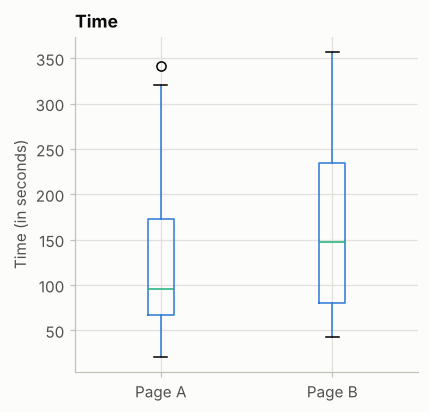

35.66666666666667


In [8]:
# BOOK CODE (Resampling): the session times on page A and page B
session_times = pd.read_csv(WEB_PAGE_DATA_CSV)
session_times.Time = 100 * session_times.Time

ax = session_times.boxplot(by='Page', column='Time',
                           figsize=(4, 4))
ax.set_xlabel('')
ax.set_ylabel('Time (in seconds)')
plt.suptitle('')

plt.tight_layout()
plt.show()

mean_a = session_times[session_times.Page == 'Page A'].Time.mean()
mean_b = session_times[session_times.Page == 'Page B'].Time.mean()
print(mean_b - mean_a)

The function `perm_fun` carries out one permutation: it draws $n_B$ of the $n$ positions at random as page B, takes the rest as page A and returns the difference of the means. The cell calls it once. (The script has no seed here; the cell adds one.)

In [9]:
# BOOK CODE (Resampling): one permutation of the session times
random.seed(2024)  # NOT IN THE BOOK: the book's single call has no seed

# The following code is different to the R version. idx_A and idx_B are reversed.

# Permutation test example with stickiness
def perm_fun(x, nA, nB):
    n = nA + nB
    idx_B = set(random.sample(range(n), nB))
    idx_A = set(range(n)) - idx_B
    return x.loc[list(idx_B)].mean() - x.loc[list(idx_A)].mean()

nA = session_times[session_times.Page == 'Page A'].shape[0]
nB = session_times[session_times.Page == 'Page B'].shape[0]
print(perm_fun(session_times.Time, nA, nB))

61.95238095238096


The script repeats the permutation 1,000 times (with the seed 1) and draws the histogram of the differences, with the observed one marked.

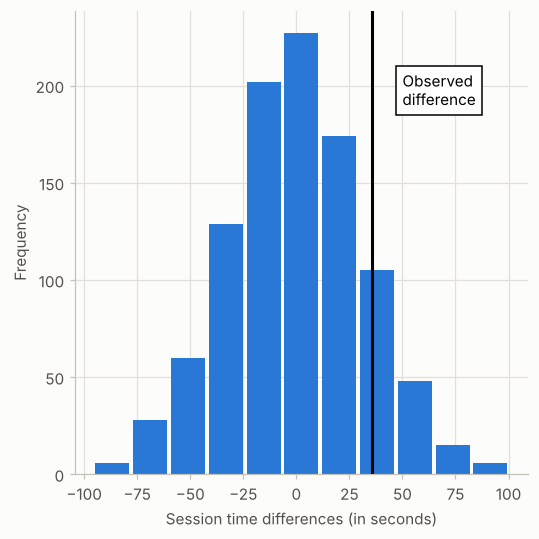

In [10]:
# BOOK CODE (Resampling): the permutation distribution of the difference of the means
random.seed(1)
perm_diffs = [perm_fun(session_times.Time, nA, nB) for _ in range(1000)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.hist(perm_diffs, bins=11, rwidth=0.9)
ax.axvline(x = mean_b - mean_a, color='black', lw=2)
ax.text(50, 190, 'Observed\ndifference', bbox={'facecolor':'white'})
ax.set_xlabel('Session time differences (in seconds)')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Finally the share of the permuted differences that exceed the observed one: the (one-sided) permutation p-value.

In [11]:
# BOOK CODE (Resampling): the p-value of the permutation test
# convert perm_diffs to numpy array to avoid problems with some Python installations
perm_diffs = np.array(perm_diffs)
print(np.mean(perm_diffs > mean_b - mean_a))

0.121


**Output analysis.**

* **The data.** Page A has a median session of 95 seconds and page B of 147; the mean difference printed by the script is 35.67 seconds (126.3 against 162.0, as extra 5(a) shows). Page B has the larger spread; page A has one session that the boxplot marks as an outlier (342 seconds).
* **One permutation.** A single random split of the 36 sessions gives a difference of 61.95 seconds, larger than the observed 35.67. Shuffled labels can therefore produce a difference of this size.
* **The permutation distribution.** The histogram of the 1,000 shuffled differences is centred near 0, roughly bell-shaped, and ranges from about -95 to about 100 seconds. The observed difference (the vertical line) lies in the right part of it, with about one eighth of the shuffled differences to its right.
* **The p-value.** 12.1% of the shuffled differences exceed the observed one. At the usual 5% threshold the difference is not significant: random assignment alone would give a difference this large or larger about one time in eight. With 1,000 permutations the p-value has a standard error of about 0.011 (extra 3(b)); a large number of permutations gives about 0.135 (extra 3(a)), so the 0.121 of the script is a little low, within 1.3 standard errors.
* Not significant does not mean that the pages are equal: the data are compatible with no difference and also with a sizable one (extra 5(d)).

### Extra experiments

**(a) An exact test, and how the Monte Carlo test converges to it.** The exact test is feasible for a subsample: 7 sessions of page A and 6 of page B (the first 7 and the first 6 sessions of the file) have $\binom{13}{6} = 1{,}716$ splits, which the cell enumerates. It compares the exact p-value with the Monte Carlo estimates $B/R$ and $(B+1)/(R+1)$ for $R$ = 100, 1,000 and 10,000 (each repeated 200 times), and shows how the estimate for the *full* data converges as $R$ grows (the exact value cannot be enumerated: $5.6 \times 10^9$ splits).

In [12]:
# EXTRA (a): the exact permutation test of a small subsample, and Monte Carlo p-values for it and for the full data
from itertools import combinations
from math import comb

small = pd.concat([session_times[session_times.Page == "Page A"].head(7), session_times[session_times.Page == "Page B"].head(6)])
values = small["Time"].to_numpy()
n_small, n_b_small = len(values), int((small["Page"] == "Page B").sum())
observed_small = values[(small["Page"] == "Page B").to_numpy()].mean() - values[(small["Page"] == "Page A").to_numpy()].mean()
all_splits = np.array([values[list(idx)].mean() - np.delete(values, list(idx)).mean() for idx in combinations(range(n_small), n_b_small)])
exact = np.mean(all_splits >= observed_small - 1e-9)
print(f"subsample: {n_small} sessions, observed difference {observed_small:.2f}; {len(all_splits):,} = C({n_small}, {n_b_small}) = {comb(n_small, n_b_small):,} splits; exact one-sided p-value {exact:.4f}")

rng = np.random.default_rng(121)
rows = []
for R in (100, 1000, 10_000):
    estimates, plus_one = [], []
    for _ in range(200):
        order = rng.random((R, n_small)).argsort(axis=1)
        diff = values[order[:, :n_b_small]].mean(axis=1) - values[order[:, n_b_small:]].mean(axis=1)
        estimates.append(np.mean(diff >= observed_small - 1e-9))
        plus_one.append((np.sum(diff >= observed_small - 1e-9) + 1) / (R + 1))
    rows.append({"R": R, "mean of B/R": np.mean(estimates), "sd of B/R": np.std(estimates, ddof=1), "sqrt(p(1-p)/R)": np.sqrt(exact * (1 - exact) / R), "mean of (B+1)/(R+1)": np.mean(plus_one)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

rows = []
for R in (1000, 10_000, 100_000, 400_000):
    order = rng.random((R, len(times))).argsort(axis=1)
    diff = times[order[:, :n_b]].mean(axis=1) - times[order[:, n_b:]].mean(axis=1)
    rows.append({"R": R, "p-value, full data": np.mean(diff >= observed), "standard error": np.sqrt(np.mean(diff >= observed) * (1 - np.mean(diff >= observed)) / R)})
print("\nthe full data (observed difference 35.67), one-sided")
print(pd.DataFrame(rows).round(4).to_string(index=False))

subsample: 13 sessions, observed difference 24.36; 1,716 = C(13, 6) = 1,716 splits; exact one-sided p-value 0.3316
    R  mean of B/R  sd of B/R  sqrt(p(1-p)/R)  mean of (B+1)/(R+1)
  100       0.3272     0.0448          0.0471               0.3339
 1000       0.3334     0.0149          0.0149               0.3341
10000       0.3312     0.0044          0.0047               0.3312

the full data (observed difference 35.67), one-sided
     R  p-value, full data  standard error
  1000              0.1480          0.0112
 10000              0.1336          0.0034
100000              0.1359          0.0011
400000              0.1351          0.0005


**Analysis of extra (a).**

* **The exact test.** The 13 sessions of the subsample (7 on page A, 6 on page B, observed difference 24.36) can be split in $\binom{13}{6} = 1{,}716$ ways; enumerating all of them gives the exact one-sided p-value 0.3316.
* **Monte Carlo against exact.** The mean of $B/R$ over the 200 repetitions is close to the exact value for every $R$ (0.3272, 0.3334, 0.3312), and its standard deviation follows $\sqrt{p(1-p)/R}$: 0.0448 against 0.0471 for $R = 100$, 0.0149 against 0.0149 for $R = 1{,}000$, 0.0044 against 0.0047 for $R = 10{,}000$. The "plus one" estimate $(B+1)/(R+1)$ has a mean of 0.3339 and 0.3341 for $R = 100$ and 1,000, a little above the exact value, and 0.3312 for $R = 10{,}000$; the difference is of the order of the Monte Carlo error of these averages and it is the conservative direction.
* **The full data.** The estimate for the full data (exact value not computable) moves from 0.1480 with $R = 1{,}000$ (standard error 0.0112) to 0.1336, 0.1359 and 0.1351 for $R$ = 10,000, 100,000 and 400,000, with standard errors 0.0034, 0.0011 and 0.0005. The p-value of the experiment is therefore about 0.135, and the 0.121 of the script is one realization of an estimate with a standard error of 0.011.

**(b) How many permutations?** The standard error of a Monte Carlo p-value is $\sqrt{p(1-p)/R}$. The cell takes $p \approx 0.134$ (the 200,000-permutation value of extra 2(a)), repeats the test with $R$ from 100 to 100,000 fifty times, and compares the spread of the estimates with the formula and with the number of permutations that would be needed for a standard error of 0.01 and of 0.001.

In [13]:
# EXTRA (b): the Monte Carlo error of a permutation p-value as a function of R
rng = np.random.default_rng(122)
p_true = p_b_longer                                                    # the 200,000 permutations of extra 2(a)
rows = []
for R in (100, 1000, 10_000, 100_000):
    estimates = []
    for _ in range(50):
        order = rng.random((R, len(times))).argsort(axis=1)
        estimates.append(np.mean(times[order[:, :n_b]].mean(axis=1) - times[order[:, n_b:]].mean(axis=1) >= observed))
    rows.append({"R": R, "mean of the estimates": np.mean(estimates), "sd of the estimates": np.std(estimates, ddof=1), "sqrt(p(1-p)/R)": np.sqrt(p_true * (1 - p_true) / R)})
print(f"reference value of the p-value (200,000 permutations of extra 2(a)): {p_true:.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))
for accuracy in (0.01, 0.001):
    print(f"permutations needed for a standard error of {accuracy}: {p_true * (1 - p_true) / accuracy ** 2:,.0f}")

reference value of the p-value (200,000 permutations of extra 2(a)): 0.1344
     R  mean of the estimates  sd of the estimates  sqrt(p(1-p)/R)
   100                 0.1252               0.0329          0.0341
  1000                 0.1347               0.0110          0.0108
 10000                 0.1354               0.0032          0.0034
100000                 0.1353               0.0012          0.0011
permutations needed for a standard error of 0.01: 1,163
permutations needed for a standard error of 0.001: 116,304


**Analysis of extra (b).**

* The spread of the estimates follows the formula: 0.0329 against 0.0341 for $R = 100$, 0.0110 against 0.0108 for 1,000, 0.0032 against 0.0034 for 10,000, 0.0012 against 0.0011 for 100,000. (Each spread is estimated from 50 values, so it is itself accurate only to about 10%.) The mean of the estimates settles at 0.135, the reference value being 0.1344. Each tenfold increase of $R$ divides the error by $\sqrt{10} \approx 3.2$.
* The p-value of the page data needs about 1,163 permutations for a standard error of 0.01 and about 116,000 for 0.001. The 1,000 permutations of the script are enough for a statement like "about 0.12", not for the second decimal. A p-value near the threshold of 0.05 deserves more permutations, because it can change side from one run to the next.

**(c) Permutation, bootstrap and classical tests on the same data.** The one-sided p-value for "page B is longer" is computed in five ways: the permutation test (200,000 permutations), the bootstrap permutation test (draws with replacement from the pooled data), Welch's $t$-test, Student's pooled $t$-test and the Mann-Whitney rank test.

In [14]:
# EXTRA (c): one-sided p-values of "B is longer" by five methods
rng = np.random.default_rng(123)
R = 200_000
n_total = len(times)
bootstrap_idx = rng.integers(0, n_total, size=(R, n_total))
boot_diff = times[bootstrap_idx[:, :n_b]].mean(axis=1) - times[bootstrap_idx[:, n_b:]].mean(axis=1)
a_times, b_times = times[~is_b], times[is_b]
rows = [
    {"method": "permutation test (shuffle the labels)", "p-value": p_b_longer},
    {"method": "bootstrap permutation test (draw with replacement from the pooled data)", "p-value": np.mean(boot_diff >= observed)},
    {"method": "Welch t-test", "p-value": stats.ttest_ind(b_times, a_times, equal_var=False, alternative="greater").pvalue},
    {"method": "Student pooled t-test", "p-value": stats.ttest_ind(b_times, a_times, equal_var=True, alternative="greater").pvalue},
    {"method": "Mann-Whitney rank test", "p-value": stats.mannwhitneyu(b_times, a_times, alternative="greater").pvalue},
]
print(f"{len(a_times)} sessions on page A (mean {a_times.mean():.1f}, sd {a_times.std(ddof=1):.1f}), {len(b_times)} on page B (mean {b_times.mean():.1f}, sd {b_times.std(ddof=1):.1f})")
print(pd.DataFrame(rows).round(4).to_string(index=False))

21 sessions on page A (mean 126.3, sd 88.5), 15 on page B (mean 162.0, sd 101.1)
                                                                 method  p-value
                                  permutation test (shuffle the labels)   0.1344
bootstrap permutation test (draw with replacement from the pooled data)   0.1297
                                                           Welch t-test   0.1408
                                                  Student pooled t-test   0.1345
                                                 Mann-Whitney rank test   0.1144


**Analysis of extra (c).**

* All five p-values lie between 0.114 and 0.141, and all lead to the same conclusion at the 5% level: permutation 0.1344, bootstrap permutation 0.1297, Welch 0.1408, Student's pooled test 0.1345, Mann-Whitney 0.1144. For these data the classical tests are good approximations of the permutation test, which is the point made by the book.
* The pooled $t$-test (0.1345) and the permutation test (0.1344) agree to three decimals; this is a coincidence of this data set, the two are different calculations. Welch's test is a little larger because it uses 27.7 degrees of freedom and does not pool the variances (extra 5(a)).
* The bootstrap permutation draws *with* replacement from the pooled data and gives 0.1297, 0.0047 below the permutation p-value; the Monte Carlo error with 200,000 draws is only 0.0008, so the difference is real. It is a different null model: sampling without replacement from the 36 observed values makes the difference of the means more variable than sampling with replacement, by the factor $36/35$ in the variance, and a narrower reference distribution gives a smaller p-value.
* The Mann-Whitney test compares ranks, not means, and answers a different question (does one group tend to have larger values?); its p-value need not equal the others.

**(d) A permutation test for any statistic.** 100,000 new permutations (with their own seed) give the p-value for other statistics of the difference between the pages: the difference of the medians, of the 10% trimmed means, the ratio of the means, and Welch's $t$-statistic. For the classical statistics there is a formula; for the others the permutation test is the only simple way.

In [15]:
# EXTRA (d): permutation p-values for several statistics, one-sided "B is larger"
from scipy.stats import trim_mean

rng = np.random.default_rng(124)
R = 100_000
order = rng.random((R, n_total)).argsort(axis=1)
b_perm, a_perm = times[order[:, :n_b]], times[order[:, n_b:]]
statistics = {
    "difference of the means": (lambda b, a: b.mean(axis=-1) - a.mean(axis=-1)),
    "difference of the medians": (lambda b, a: np.median(b, axis=-1) - np.median(a, axis=-1)),
    "difference of the 10% trimmed means": (lambda b, a: trim_mean(b, 0.1, axis=-1) - trim_mean(a, 0.1, axis=-1)),
    "ratio of the means": (lambda b, a: b.mean(axis=-1) / a.mean(axis=-1)),
    "Welch t statistic": (lambda b, a: (b.mean(axis=-1) - a.mean(axis=-1)) / np.sqrt(b.var(axis=-1, ddof=1) / b.shape[-1] + a.var(axis=-1, ddof=1) / a.shape[-1])),
}
rows = []
for name, fn in statistics.items():
    obs, perm_values = fn(b_times, a_times), fn(b_perm, a_perm)
    rows.append({"statistic": name, "observed": obs, "p-value (permutation)": np.mean(perm_values >= obs - 1e-12)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

                          statistic  observed  p-value (permutation)
            difference of the means   35.6667                 0.1343
          difference of the medians   52.0000                 0.1744
difference of the 10% trimmed means   42.3891                 0.1309
                 ratio of the means    1.2823                 0.1343
                  Welch t statistic    1.0983                 0.1322


**Analysis of extra (d).**

* The difference of the means and the **ratio** of the means have the same p-value (0.1343): given the fixed total of all 36 sessions, both are increasing functions of the sum of the page B sessions, so they order the permutations in the same way. Welch's $t$ statistic (0.1322) and the 10% trimmed mean (0.1309) give nearly the same answer. The **median** is the exception: the observed difference of the medians is 52 seconds, larger than the 35.67 of the means, yet its p-value is higher (0.1744), because the median of 15 or 21 values varies more by chance.
* None of the five reaches 0.05. In practice the statistic should be chosen *before* looking, as any search over statistics for the smallest p-value is a multiple testing problem (section 6). The advantage of the permutation test is that any of these statistics can be used with the same code and no new theory.

---
## 4. Statistical significance and p-values

*Book section: "Statistical Significance and P-Values" (p-value, alpha, type 1 and type 2 errors, data science and p-values). The code of the script tests whether two prices give different conversion rates.*

### Summary

* **Statistical significance** is the way in which statisticians decide whether an experimental result lies outside what chance could easily produce. A result is called statistically significant if it is more extreme than the results that a chance model (the null hypothesis) produces, up to a stated probability.
* The **p-value** is the probability, *computed under the chance model of the null hypothesis*, of obtaining a result at least as unusual as the one observed. **Alpha** ($\alpha$) is the threshold chosen in advance for that probability, often 0.05 or 0.01: a result with a p-value below alpha is declared significant.
* Two ways to be wrong: a **type 1 error** is to conclude that an effect is real when it is due to chance; a **type 2 error** is to conclude that an effect is due to chance when it is real. Statistical significance tests are mainly about protecting against type 1 errors.
* The example of the script: two prices are tried on two groups of visitors. Price A converts 200 of 23,739 visitors (0.8425%), price B 182 of 22,588 (0.8057%); the difference of 0.0368 percentage points is small, and a permutation test that draws the conversions at random between the two groups finds that a difference this large or larger arises by chance in about one third of the permutations. The result is not significant. A $\chi^2$ test gives a similar one-sided p-value.
* **Data science and p-values.** For the data scientist a p-value is a useful measure of whether a result is within the range of normal chance variation; it is not a measure of the importance of an effect, and a result is not made true or false by a threshold. The statement of the American Statistical Association (Wasserstein and Lazar, 2016) lists the principles: a p-value is not the probability that the hypothesis is true, a decision should not rest on whether a p-value passes a threshold, and a p-value does not measure the size or importance of an effect.

### Theory

**Definition.** For a test statistic $T$ whose distribution under $H_0$ is known (or simulated), the one-sided p-value of the observed value $t$ is $p = P(T \ge t \mid H_0)$. Under $H_0$ and for a continuous $T$ the p-value is *uniformly distributed* on $(0, 1)$, which is why the test "reject if $p \le \alpha$" has the false-rejection probability $\alpha$; when $H_0$ is false the p-values pile up near 0, more so the larger the effect and the sample (extra 4(c)).

**Error rates and power.** The **type I error** rate is $\alpha = P(\text{reject} \mid H_0)$; the **type II error** rate is $\beta = P(\text{do not reject} \mid H_1)$ and $1 - \beta$ is the **power**. For a given effect size the power rises with the sample size and with $\alpha$; the two errors trade off against each other (section 11).

**What a p-value is not.** It is $P(\text{data this extreme} \mid H_0)$, not $P(H_0 \mid \text{data})$. By Bayes' rule, if a share $\pi$ of the hypotheses that are tested are true effects, the probability that a "significant" result is a true effect is
$$\mathrm{PPV} = \frac{\pi\,(1-\beta)}{\pi\,(1-\beta) + (1-\pi)\,\alpha},$$
which for a small prior share $\pi$ or a low power can be small even though $\alpha = 0.05$ (Ioannidis, 2005; extra 4(d)).

**Exact p-values for two proportions.** If the $m$ conversions of $N$ visitors are assigned at random to the groups, the number of conversions in the first group (of size $n_1$) has the **hypergeometric** distribution; the one-sided p-value is its upper tail. This is exactly what the permutation test of the script estimates by simulation, and the same probability gives *Fisher's exact test* for a $2 \times 2$ table. The $\chi^2$ and $z$ tests approximate it with the normal distribution; `scipy.stats.chi2_contingency` applies by default a continuity correction (Yates, 1934) to $2 \times 2$ tables.

**Significance is not importance.** The statistic grows with the sample size: for a fixed true difference $\delta$ of two means with standard deviation $\sigma$, the standardized difference is about $\delta\sqrt{n/2}/\sigma$ with $n$ observations per group, so any non-zero difference becomes significant when $n$ is large enough (extra 4(e)). The size of the effect, with its confidence interval, is the quantity to report.

### Book code

The script compares the conversions of two prices. It sets the seed 1, defines the observed difference in percentage points and builds a vector with 382 conversions (1) among 46,327 visitors (the numbers add up: 23,739 + 22,588 = 46,327 and 200 + 182 = 382). It then permutes the vector 1,000 times with the function `perm_fun` of section 3 (multiplying the difference by 100 to get percentage points) and plots the histogram.

Observed difference: 0.0368%


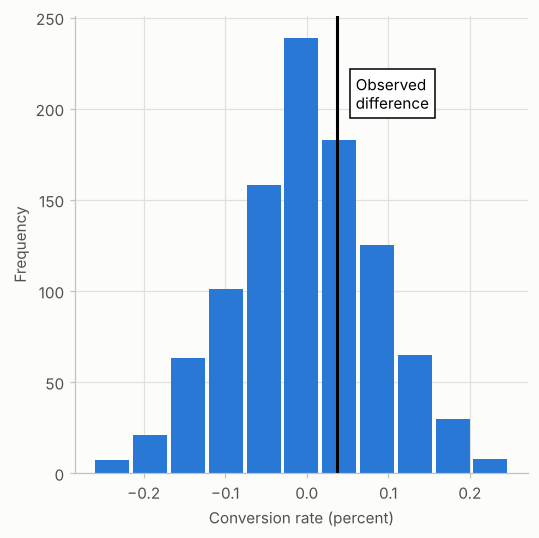

In [16]:
# BOOK CODE (Statistical Significance and P-Values): the permutation distribution of the difference of two conversion rates
random.seed(1)
obs_pct_diff = 100 * (200 / 23739 - 182 / 22588)
print(f'Observed difference: {obs_pct_diff:.4f}%')
conversion = [0] * 45945
conversion.extend([1] * 382)
conversion = pd.Series(conversion)

perm_diffs = [100 * perm_fun(conversion, 23739, 22588)
              for _ in range(1000)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.hist(perm_diffs, bins=11, rwidth=0.9)
ax.axvline(x=obs_pct_diff, color='black', lw=2)
ax.text(0.06, 200, 'Observed\ndifference', bbox={'facecolor':'white'})
ax.set_xlabel('Conversion rate (percent)')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The p-value of the permutation test is the share of the permuted differences that exceed the observed one.

In [17]:
# BOOK CODE (P-Value): the p-value of the permutation test
# If `np.mean` is applied to a list of booleans, it gives the percentage of how often True was found in the list (#True / #Total).

print(np.mean([diff > obs_pct_diff for diff in perm_diffs]))

0.332


For comparison the script applies the chi-square test to the $2 \times 2$ table of the conversions and halves the p-value to get a one-sided one.

In [18]:
# BOOK CODE (P-Value): the chi-square test of the same table
survivors = np.array([[200, 23739 - 200], [182, 22588 - 182]])
chi2, p_value, df, _ = stats.chi2_contingency(survivors)

print(f'p-value for single sided test: {p_value / 2:.4f}')

p-value for single sided test: 0.3498


**Output analysis.**

* **The observed difference** is 0.0368 percentage points: price A converts 0.8425% of its visitors and price B 0.8057% (A minus B).
* **The permutation distribution.** The histogram of the 1,000 shuffled differences is centred near 0 and ranges from about -0.25 to +0.25 percentage points, so the observed 0.0368 lies near the middle of it.
* **The p-value.** 33.2% of the shuffled differences exceed the observed one, and the chi-square test (with the default continuity correction, halved because the observed difference is in the direction of the alternative) gives 0.3498. The two differ by 0.018, 1.2 standard errors of the Monte Carlo estimate (0.015 for 1,000 permutations). Both say the same: a difference like this appears by chance about one time in three, so there is no evidence that the prices differ.
* The permutation test of the script is slow, because every call of `perm_fun` samples positions of a 46,327-element Series (about 20 milliseconds a call); extra 4(a) gets the same distribution from a single hypergeometric draw.

### Extra experiments

**(a) The exact p-value, and five other ways to the same number.** The conversions of the script form a $2 \times 2$ table. The cell computes the one-sided p-value for "price A converts better" by the exact hypergeometric distribution (which is also Fisher's exact test), by a Monte Carlo of one million permutations (cheaper than the book's permutations of 46,327 values: the number of conversions in the first group is a hypergeometric draw), by the pooled two-proportion $z$ test, and by the $\chi^2$ test with and without the continuity correction (halved, as in the script).

In [19]:
# EXTRA (a): one-sided p-value of 200/23,739 against 182/22,588 by several methods
from statsmodels.stats.proportion import proportions_ztest

n1, n2, c1, c2 = 23739, 22588, 200, 182
total, conversions = n1 + n2, c1 + c2
table = np.array([[c1, n1 - c1], [c2, n2 - c2]])
rng = np.random.default_rng(131)
draws = rng.hypergeometric(conversions, total - conversions, n1, size=1_000_000)            # conversions among the n1 visitors of group 1
z_stat, z_p = proportions_ztest([c1, c2], [n1, n2], alternative="larger")
rows = [
    {"method": "exact: hypergeometric upper tail", "p-value": stats.hypergeom.sf(c1 - 1, total, conversions, n1)},
    {"method": "Fisher's exact test, alternative 'greater'", "p-value": stats.fisher_exact(table, alternative="greater").pvalue},
    {"method": "Monte Carlo, one million permutations", "p-value": np.mean(draws >= c1)},
    {"method": "pooled two-proportion z test", "p-value": z_p},
    {"method": "chi-square test without continuity correction, halved", "p-value": stats.chi2_contingency(table, correction=False)[1] / 2},
    {"method": "chi-square test with continuity correction, halved (the book)", "p-value": stats.chi2_contingency(table)[1] / 2},
]
print(f"rates {c1 / n1:.4%} and {c2 / n2:.4%}, difference {100 * (c1 / n1 - c2 / n2):.4f} percentage points, z = {z_stat:.3f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nthe permutation distribution of the number of conversions in group 1: mean {draws.mean():.1f} (theory {conversions * n1 / total:.1f}), sd {draws.std():.2f}; the observed number is {c1}")

rates 0.8425% and 0.8057%, difference 0.0368 percentage points, z = 0.437
                                                       method  p-value
                             exact: hypergeometric upper tail   0.3499
                   Fisher's exact test, alternative 'greater'   0.3499
                        Monte Carlo, one million permutations   0.3501
                                 pooled two-proportion z test   0.3309
        chi-square test without continuity correction, halved   0.3309
chi-square test with continuity correction, halved (the book)   0.3498

the permutation distribution of the number of conversions in group 1: mean 195.7 (theory 195.7), sd 9.74; the observed number is 200


**Analysis of extra (a).**

* The exact p-value is 0.3499, and Fisher's exact test gives the identical number (it is the same hypergeometric tail). The Monte Carlo estimate from a million permutations, 0.3501, agrees (its standard error is 0.0005), and so does the chi-square test **with** continuity correction (0.3498), which is the version used by the book.
* The pooled $z$-test and the chi-square test **without** the correction give 0.3309 ($z = 0.437$), about 0.019 lower. For this table the corrected test is the accurate one; neither changes the conclusion. The script's own 1,000-permutation estimate (0.332) happens to be near the uncorrected value, within its standard error of 0.015.
* The number of conversions among the 23,739 visitors of price A is 195.7 on average under the null hypothesis (the theory says 195.7) with a standard deviation of 9.74; the observed 200 is 0.44 standard deviations above the mean, which is the $z$ of 0.437.

**(b) Type I and type II errors.** The cell simulates experiments with the sample sizes of the script (23,739 and 22,588 visitors) in which the conversion rate of the second group is 0.8246% (the pooled rate of the data) and the rate of the first is higher by a relative amount of 0% (no effect), 4.4% (about the observed difference: 0.0363 percentage points, against the observed 0.0368), 10%, 20% and 30%. For each, 100,000 experiments are drawn and tested with the one-sided pooled $z$ test at the 5% level. The share of rejections is the false-positive rate under no effect and the power otherwise; its complement is the type II error.

In [20]:
# EXTRA (b): type I error and power of the one-sided 5% test of two conversion rates
rng = np.random.default_rng(132)
base = conversions / total
rows = []
for relative in (0.0, 0.044, 0.10, 0.20, 0.30):
    p1, p2 = base * (1 + relative), base
    x1, x2 = rng.binomial(n1, p1, size=100_000), rng.binomial(n2, p2, size=100_000)
    pooled_rate = (x1 + x2) / (n1 + n2)
    z = (x1 / n1 - x2 / n2) / np.sqrt(pooled_rate * (1 - pooled_rate) * (1 / n1 + 1 / n2))
    reject = np.mean(z > stats.norm.ppf(0.95))
    theory = 1 - stats.norm.cdf(stats.norm.ppf(0.95) - (p1 - p2) / np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2))
    rows.append({"relative increase": relative, "rate 1": p1, "difference (percentage points)": 100 * (p1 - p2), "rejects (simulated)": reject, "power (normal theory)": theory,
                 "type II error": 1 - reject})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 relative increase  rate 1  difference (percentage points)  rejects (simulated)  power (normal theory)  type II error
             0.000  0.0082                          0.0000               0.0496                 0.0500         0.9504
             0.044  0.0086                          0.0363               0.1109                 0.1117         0.8891
             0.100  0.0091                          0.0825               0.2459                 0.2461         0.7541
             0.200  0.0099                          0.1649               0.5911                 0.5905         0.4089
             0.300  0.0107                          0.2474               0.8652                 0.8656         0.1348


**Analysis of extra (b).**

* With no true difference the one-sided 5% test rejects in 4.96% of the experiments: the type I error is controlled. The simulated rejection rates match the normal-theory power within 0.001 in every row (for instance 0.1109 against 0.1117).
* If the true relative increase were 4.4% (close to the observed difference, which is 4.5% of the pooled rate), the experiment would detect it only in 11.1% of the repetitions: the type II error is 88.9%. A relative increase of 10% is detected in 24.6%, 20% in 59.1% and 30% in 86.5% of the experiments.
* So a non-significant result from 23,739 and 22,588 visitors says little against an improvement of a few percent: the experiment was able to detect only a very large improvement (about 30% relative) with high probability. How many visitors are needed is the subject of section 11.

**(c) The distribution of p-values.** Two groups of 30 are drawn from normal populations whose means differ by $d = 0, 0.2, 0.5$ and $0.8$ standard deviations, 20,000 times each, and tested with the pooled $t$-test. The histograms of the p-values show how a test behaves when there is nothing to find and when there is something.

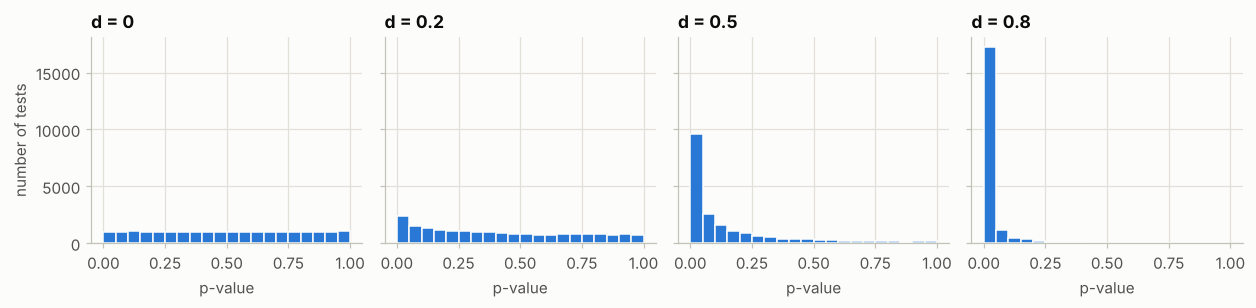

 effect d  share p < 0.05 (power)  share p < 0.01  share p > 0.5  median p-value
      0.0                  0.0506          0.0111         0.5023          0.5020
      0.2                  0.1200          0.0346         0.3862          0.3695
      0.5                  0.4808          0.2444         0.1003          0.0556
      0.8                  0.8622          0.6659         0.0073          0.0030


In [21]:
# EXTRA (c): the distribution of the p-value of a t-test for several true effect sizes
rng = np.random.default_rng(133)
n_per_group, repetitions = 30, 20_000
fig, axes = plt.subplots(1, 4, figsize=(11.5, 2.9), sharey=True)
rows = []
for ax, d in zip(axes, (0, 0.2, 0.5, 0.8)):
    p = stats.ttest_ind(rng.normal(d, 1, size=(repetitions, n_per_group)), rng.normal(0, 1, size=(repetitions, n_per_group)), axis=1).pvalue
    ax.hist(p, bins=20, range=(0, 1), color=PALETTE[0], edgecolor=SURFACE)
    ax.set_title(f"d = {d}"); ax.set_xlabel("p-value")
    rows.append({"effect d": d, "share p < 0.05 (power)": np.mean(p < 0.05), "share p < 0.01": np.mean(p < 0.01), "share p > 0.5": np.mean(p > 0.5), "median p-value": np.median(p)})
axes[0].set_ylabel("number of tests")
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))

**Analysis of extra (c).**

* With no effect ($d = 0$) the p-values are uniform: 5.06% are below 0.05, 1.11% below 0.01, 50.2% above 0.5, and the median is 0.502.
* As the effect grows the p-values move towards 0, but they do not disappear from the upper range: for $d = 0.2$ only 12.0% are below 0.05 (the median is 0.37); for $d = 0.5$, 48.1% (median 0.056); for $d = 0.8$, 86.2% (median 0.003, and 66.6% are below 0.01).
* A single p-value of 0.03 can therefore come from any of the four situations: a p-value of 0.03 or less happens in 3% of the experiments with no effect and in a larger share of those with a real effect. The p-value is a random variable that depends on the sample and on the true effect, and it says how surprising the data would be under the null hypothesis, not which of the situations is the true one.

**(d) What does a significant result mean?** If the share of true effects among the hypotheses tested is $\pi$, the probability that a significant result is a true effect is the PPV of the theory block. The cell tabulates it for $\pi$ = 0.5, 0.1, 0.01 and a power of 0.8, 0.5 and 0.2, and checks two cases by simulation: 400,000 experiments with two groups of 26 observations, in which a share $\pi$ of the experiments has a true effect of 0.8 standard deviations (power about 0.8) and the others none.

In [22]:
# EXTRA (d): the share of true effects among the significant results
alpha = 0.05
rows = []
for pi in (0.5, 0.1, 0.01):
    rows.append({"share of true effects": pi, **{f"PPV, power {pw}": pi * pw / (pi * pw + (1 - pi) * alpha) for pw in (0.8, 0.5, 0.2)}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

rng = np.random.default_rng(134)
n_per_group, experiments = 26, 400_000
power_d08 = stats.nct.sf(stats.t.ppf(0.975, 2 * n_per_group - 2), 2 * n_per_group - 2, 0.8 * np.sqrt(n_per_group / 2))
rows = []
for pi in (0.5, 0.1):
    real = rng.random(experiments) < pi
    shift = np.where(real, 0.8, 0.0)[:, None]
    p = stats.ttest_ind(rng.normal(size=(experiments, n_per_group)) + shift, rng.normal(size=(experiments, n_per_group)), axis=1).pvalue
    significant = p < alpha
    rows.append({"share of true effects": pi, "power (simulated)": np.mean(significant[real]), "false positive rate": np.mean(significant[~real]),
                 "share of true effects among the significant": np.mean(real[significant]), "PPV (formula, power from the theory)": pi * power_d08 / (pi * power_d08 + (1 - pi) * alpha)})
print(f"\npower of the 5% two-sided t-test with {n_per_group} per group and d = 0.8: {power_d08:.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

 share of true effects  PPV, power 0.8  PPV, power 0.5  PPV, power 0.2
                  0.50           0.941           0.909           0.800
                  0.10           0.640           0.526           0.308
                  0.01           0.139           0.092           0.039

power of the 5% two-sided t-test with 26 per group and d = 0.8: 0.807
 share of true effects  power (simulated)  false positive rate  share of true effects among the significant  PPV (formula, power from the theory)
                   0.5              0.808                0.050                                        0.942                                 0.942
                   0.1              0.807                0.049                                        0.648                                 0.642


**Analysis of extra (d).**

* The table: with a power of 0.8 and $\alpha = 0.05$, the share of true effects among the significant results is 94.1% when half of the hypotheses tested are true, 64.0% when one in ten is, and 13.9% when one in a hundred is. With a power of 0.2 these numbers fall to 80.0%, 30.8% and 3.9%.
* The simulation agrees with the formula. With 26 observations per group and $d = 0.8$ the power is 0.807 in theory and 0.808 and 0.807 in the simulation, and the false positive rate is 5% (0.050 and 0.049). The share of true effects among the significant results is 0.942 (formula 0.942) when half of the hypotheses are true and 0.648 (formula 0.642) when one in ten is.
* Thus, when a tenth of the tested ideas work, about 35% of the "significant" results (1 - 0.648) are false positives, even with a good power and a 5% level: the p-value threshold is the error rate of a single test on a true null, not the share of false findings among the discoveries (Ioannidis, 2005). The share depends on how plausible the hypotheses are before the experiment.

**(e) Significance is not importance.** Two true effects, $d = 0.01$ and $d = 0.1$ standard deviations, are compared for samples of $10^2$ to $10^7$ observations per group. The cell reports the two-sided p-value that results when the sample difference equals the true difference exactly (the "expected" p-value) and the power of the 5% test.

In [23]:
# EXTRA (e): the p-value of a fixed, tiny true effect as the sample grows (normal theory, known standard deviation 1)
rows = []
for n in (10 ** 2, 10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6, 10 ** 7):
    row = {"n per group": n}
    for d in (0.01, 0.1):
        z = d * np.sqrt(n / 2)
        row[f"d = {d}: p-value at the true difference"] = 2 * stats.norm.sf(z)
        row[f"d = {d}: power"] = stats.norm.sf(1.96 - z) + stats.norm.cdf(-1.96 - z)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

 n per group  d = 0.01: p-value at the true difference  d = 0.01: power  d = 0.1: p-value at the true difference  d = 0.1: power
         100                                     0.944           0.0506                                     0.48           0.109
        1000                                     0.823           0.0557                                   0.0253           0.609
       10000                                      0.48            0.109                                 1.54e-12               1
      100000                                    0.0253            0.609                                9.51e-111               1
     1000000                                  1.54e-12                1                                        0               1
    10000000                                 9.51e-111                1                                        0               1


**Analysis of extra (e).**

* For $d = 0.01$ (one hundredth of a standard deviation) the p-value at the true difference is 0.944 with 100 observations per group, 0.823 with 1,000, 0.48 with 10,000, 0.0253 with 100,000 and $1.5 \times 10^{-12}$ with a million; the power of the test grows from 5.1% to 61% (at 100,000) and 100% (at a million). For $d = 0.1$ the same pattern appears 100 times earlier: 0.48 with 100, 0.0253 with 1,000, $1.5 \times 10^{-12}$ with 10,000. (The entries 0 are numbers below the smallest positive floating-point number.)
* The statistic depends on $d\sqrt{n/2}$, so $d = 0.01$ with 100,000 observations and $d = 0.1$ with 1,000 have the same p-value (0.0253). With enough data any non-zero difference is "highly significant", however small and irrelevant. A p-value says whether a difference can be told from zero; it does not say whether the difference is large enough to matter. Report the estimated effect with its confidence interval.

---
## 5. $t$-Tests

*Book section: "t-Tests". The code of the script applies two versions of the $t$-test to the session times.*

### Summary

* The **$t$-test** is the classical test for the difference of two means. It was developed in the days before computers made resampling easy, and it compares the observed difference with a reference distribution, the **$t$-distribution**, instead of a permutation distribution. The test statistic is the difference of the means divided by its standard error.
* There are several forms: the **two-sample** test for two independent groups (as in the A/B test), the **paired** test for two measurements on the same units (before and after), and the one-sample test. The two-sample test exists in a version that assumes equal variances and in Welch's version, which does not.
* In practice the permutation distribution and the $t$-distribution give similar answers when the assumptions are not seriously violated, which is one reason why the classical tests have worked. A data scientist usually meets the $t$-test as a number in software output.
* The script tests the difference of the session times of the two pages with `scipy` (Welch's version, a two-sided p-value that is halved for the one-sided hypothesis) and with `statsmodels` (one-sided directly); both give 0.1408, close to the permutation p-value of section 3 (0.121 from the script's 1,000 permutations, about 0.135 from many more).

### Theory

**Welch's statistic.** For independent samples with means $\bar x_1, \bar x_2$, variances $s_1^2, s_2^2$ and sizes $n_1, n_2$,
$$t = \frac{\bar x_1 - \bar x_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}} ,$$
which is referred to a $t$-distribution with the (Welch-Satterthwaite) degrees of freedom
$$\nu = \frac{\bigl(s_1^2/n_1 + s_2^2/n_2\bigr)^2}{\dfrac{(s_1^2/n_1)^2}{n_1 - 1} + \dfrac{(s_2^2/n_2)^2}{n_2 - 1}}$$
(Satterthwaite, 1946; Welch, 1947). The pooled version of Student uses a common variance $s_p^2 = \bigl((n_1-1)s_1^2 + (n_2-1)s_2^2\bigr)/(n_1+n_2-2)$ and $n_1 + n_2 - 2$ degrees of freedom; it is exact for normal data with equal variances and can have a wrong level when the variances and the sizes both differ (extra 2(b)). For *paired* data the test is a one-sample test of the differences $d_i$, $t = \bar d/(s_d/\sqrt{n})$ with $n-1$ degrees of freedom.

**One-sided and two-sided.** The two-sided p-value is twice the one-sided p-value *in the direction of the observed difference*; the one-sided p-value for the opposite direction is $1 - p/2$. Halving the two-sided p-value, as the script does, is correct only if the observed difference has the direction of the alternative.

**Assumptions.** Independent observations, and a sampling distribution of the mean that is close to normal, which the central limit theorem delivers for moderate samples of data that are not too skewed (section 3 of Chapter 2). With heavy tails the test loses power; rank tests such as Mann-Whitney's are alternatives (extra 5(b)).

**Test and interval.** The two-sided test at level $\alpha$ rejects $H_0$: no difference exactly when the $(1-\alpha)$ confidence interval for the difference does not contain 0 (extra 5(d)).

### Book code

The first version uses `scipy.stats.ttest_ind` with `equal_var=False` (Welch's test); the p-value is two-sided and the script halves it. The second uses `statsmodels` and asks directly for the one-sided alternative "the mean of A is smaller".

In [24]:
# BOOK CODE (t-Tests): Welch's t-test with scipy, the one-sided p-value by halving
res = stats.ttest_ind(session_times[session_times.Page == 'Page A'].Time,
                      session_times[session_times.Page == 'Page B'].Time,
                      equal_var=False)
print(f'p-value for single sided test: {res.pvalue / 2:.4f}')

p-value for single sided test: 0.1408


In [25]:
# BOOK CODE (t-Tests): the same test with statsmodels and the one-sided alternative
tstat, pvalue, df = sm.stats.ttest_ind(
    session_times[session_times.Page == 'Page A'].Time,
    session_times[session_times.Page == 'Page B'].Time,
    usevar='unequal', alternative='smaller')
print(f'p-value: {pvalue:.4f}')

p-value: 0.1408


**Output analysis.**

* Both calls give 0.1408. The `scipy` test returns the two-sided p-value 0.2815 (extra 5(a)) and the script halves it. That is legitimate only because the mean of page A (126.3) is smaller than that of page B (162.0), the direction of the alternative "A is smaller"; `statsmodels` is asked for `alternative='smaller'` directly and returns the same number.
* The classical p-value 0.1408 lies close to the permutation p-value of section 3 (0.121 from 1,000 permutations, about 0.135 from many; the five methods of extra 3(c) range from 0.114 to 0.141). Like the permutation test, the $t$-test does not find a significant difference between the pages.

### Extra experiments

**(a) Welch's statistic by hand.** The cell computes the statistic, the degrees of freedom and the p-values of the session-time data from the formulas of the theory block and compares them with `scipy` and `statsmodels`, also for the pooled version.

In [26]:
# EXTRA (a): Welch's t-test by hand
x_a = session_times[session_times.Page == "Page A"].Time.to_numpy()
x_b = session_times[session_times.Page == "Page B"].Time.to_numpy()
n_a_, n_b_ = len(x_a), len(x_b)
va, vb = x_a.var(ddof=1) / n_a_, x_b.var(ddof=1) / n_b_
t_hand = (x_a.mean() - x_b.mean()) / np.sqrt(va + vb)
df_hand = (va + vb) ** 2 / (va ** 2 / (n_a_ - 1) + vb ** 2 / (n_b_ - 1))
p_two_hand = 2 * stats.t.sf(abs(t_hand), df_hand)
sp2 = ((n_a_ - 1) * x_a.var(ddof=1) + (n_b_ - 1) * x_b.var(ddof=1)) / (n_a_ + n_b_ - 2)
t_pooled = (x_a.mean() - x_b.mean()) / np.sqrt(sp2 * (1 / n_a_ + 1 / n_b_))
welch = stats.ttest_ind(x_a, x_b, equal_var=False)
sm_t, sm_p, sm_df = sm.stats.ttest_ind(x_a, x_b, usevar="unequal")
pooled = stats.ttest_ind(x_a, x_b, equal_var=True)
print(f"page A: n = {n_a_}, mean {x_a.mean():.2f}, sd {x_a.std(ddof=1):.2f}; page B: n = {n_b_}, mean {x_b.mean():.2f}, sd {x_b.std(ddof=1):.2f}")
print(pd.DataFrame({
    "t": [t_hand, welch.statistic, sm_t, t_pooled, pooled.statistic],
    "degrees of freedom": [df_hand, welch.df, sm_df, n_a_ + n_b_ - 2, n_a_ + n_b_ - 2],
    "two-sided p-value": [p_two_hand, welch.pvalue, sm_p, 2 * stats.t.sf(abs(t_pooled), n_a_ + n_b_ - 2), pooled.pvalue],
}, index=["by hand (Welch)", "scipy (Welch)", "statsmodels (Welch)", "by hand (pooled)", "scipy (pooled)"]).round(4).to_string())
print(f"\none-sided p-value in the direction of the data (A smaller than B): {p_two_hand / 2:.4f}; in the opposite direction: {1 - p_two_hand / 2:.4f}")

page A: n = 21, mean 126.33, sd 88.46; page B: n = 15, mean 162.00, sd 101.14
                          t  degrees of freedom  two-sided p-value
by hand (Welch)     -1.0983             27.6934             0.2815
scipy (Welch)       -1.0983             27.6934             0.2815
statsmodels (Welch) -1.0983             27.6934             0.2815
by hand (pooled)    -1.1237             34.0000             0.2690
scipy (pooled)      -1.1237             34.0000             0.2690

one-sided p-value in the direction of the data (A smaller than B): 0.1408; in the opposite direction: 0.8592


**Analysis of extra (a).**

* The formulas of the theory block, `scipy` and `statsmodels` agree: $t = -1.0983$ with 27.69 degrees of freedom and a two-sided p-value of 0.2815. The degrees of freedom are not an integer because Welch's approximation uses the two variances (88.5 and 101.1 seconds for the standard deviations); the pooled test uses 34 and gives $t = -1.1237$, $p = 0.2690$, similar because the two variances are not very different.
* The one-sided p-value in the direction of the data (A smaller than B) is 0.1408; in the opposite direction it is $1 - 0.1408 = 0.8592$. Halving the two-sided p-value gives the right answer only for the direction in which the data point.

**(b) The $t$-test and the rank test.** For samples of 15 per group, 20,000 pairs of samples are drawn from a normal distribution, a $t$ distribution with 3 degrees of freedom (heavy tails) and a lognormal distribution (skewed), with and without a shift of 0.8 added to the second group (to the logarithm for the lognormal distribution). The shift is 0.8 standard deviations for the normal and the logarithm of the lognormal, but only 0.46 for the $t$ distribution with 3 degrees of freedom, whose standard deviation is $\sqrt{3}$. The cell reports the false-positive rate (no shift) and the power (shift) of the two-sided 5% Welch $t$-test and Mann-Whitney test. For the lognormal data the shift is added to the logarithm, so that it is a multiplication of the values.

In [27]:
# EXTRA (b): Welch t-test and Mann-Whitney test under three distributions, 15 observations per group
rng = np.random.default_rng(141)
n_per_group, repetitions, shift = 15, 20_000, 0.8
draw = {"normal": lambda size: rng.normal(size=size),
        "t, 3 degrees of freedom (heavy tails)": lambda size: rng.standard_t(3, size=size),
        "lognormal (skewed)": lambda size: rng.normal(size=size)}
rows = []
for name, sampler in draw.items():
    row = {"distribution": name}
    for label, delta in (("no shift", 0.0), (f"shift {shift}", shift)):
        a, b = sampler((repetitions, n_per_group)), sampler((repetitions, n_per_group)) + delta
        if name.startswith("lognormal"):
            a, b = np.exp(a), np.exp(b)
        row[f"t-test, {label}"] = np.mean(stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue < 0.05)
        row[f"Mann-Whitney, {label}"] = np.mean(stats.mannwhitneyu(a, b, axis=1).pvalue < 0.05)
    rows.append(row)
print(f"the standard error of a rate near 0.05 is {np.sqrt(0.05 * 0.95 / repetitions):.4f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

the standard error of a rate near 0.05 is 0.0015
                         distribution  t-test, no shift  Mann-Whitney, no shift  t-test, shift 0.8  Mann-Whitney, shift 0.8
                               normal             0.050                   0.046              0.562                    0.526
t, 3 degrees of freedom (heavy tails)             0.042                   0.045              0.297                    0.363
                   lognormal (skewed)             0.032                   0.046              0.365                    0.525


**Analysis of extra (b).**

* **Normal data:** both tests keep their level (5.0% and 4.6%) and the $t$-test has the higher power (56.2% against 52.6%). Standard error of each rate: 0.0015.
* **Heavy tails** ($t$ with 3 degrees of freedom): the levels are 4.2% and 4.5%, but the Mann-Whitney test has the higher power (36.3% against 29.7%).
* **Skewed data** (lognormal): the Welch test has a level of 3.2% (conservative) and a power of 36.5%, the Mann-Whitney test 4.6% and 52.5%.
* The same shift of 0.8 is a different effect in each row: 0.8 standard deviations for the normal and for the logarithm of the lognormal (the values are multiplied by $e^{0.8} = 2.2$), but only 0.46 for the $t$ distribution with 3 degrees of freedom. The powers can be compared within a row, not between rows, and for the lognormal data the two tests do not address the same question (the $t$-test the difference of the means, the rank test whether one group tends to have larger values). With 15 observations per group the rank test had the higher power for both non-normal distributions (by 6.6 and 16 percentage points), and for normal data it lost 3.6 percentage points. This is the argument for keeping rank tests and permutation tests in the toolbox next to the $t$-test.

**(c) Paired against independent.** A before-and-after experiment on 20 subjects: each subject has a stable level (standard deviation 3 across subjects) and the measurement noise has a standard deviation of 1; the true change is 0.8. The cell tests the change with the paired $t$-test, and, wrongly, with a two-sample test that ignores the pairing, in 20,000 simulated experiments, with and without a true change.

In [28]:
# EXTRA (c): the power of a paired test and of a two-sample test on the same before/after data
rng = np.random.default_rng(142)
subjects, repetitions = 20, 20_000
level = 3 * rng.normal(size=(repetitions, subjects, 1))
rows = []
for change in (0.0, 0.8):
    before = level[:, :, 0] + rng.normal(size=(repetitions, subjects))
    after = level[:, :, 0] + change + rng.normal(size=(repetitions, subjects))
    rows.append({"true change": change, "paired t-test rejects": np.mean(stats.ttest_rel(after, before, axis=1).pvalue < 0.05),
                 "two-sample t-test rejects": np.mean(stats.ttest_ind(after, before, axis=1).pvalue < 0.05),
                 "correlation before/after": np.mean([np.corrcoef(b, a)[0, 1] for b, a in zip(before[:200], after[:200])])})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"correlation of the two measurements by theory: 3^2 / (3^2 + 1^2) = {9 / 10:.2f}")

 true change  paired t-test rejects  two-sample t-test rejects  correlation before/after
         0.0                  0.050                      0.000                     0.899
         0.8                  0.676                      0.004                     0.898
correlation of the two measurements by theory: 3^2 / (3^2 + 1^2) = 0.90


**Analysis of extra (c).**

* The paired $t$-test has the right level (5.0% with no change) and a power of 67.6% for a change of 0.8. The two-sample test that ignores the pairing rejects in 0.0% (rounded to three decimals) and 0.4% of the experiments: it has practically no power.
* The reason is the variance. The two measurements of a subject are highly correlated (0.899 in the simulation, 0.90 in theory), because the stable level of the subject (standard deviation 3) is in both. The pairing removes it: the standard error of the mean change is about $\sqrt{2 \times 1^2/20} = 0.32$. The two-sample test leaves the subject level in the standard error, which is then about 1.0 (from $\sqrt{(3^2 + 1^2) \times 2/20}$), so the same difference looks much less remarkable and the test is also much too conservative under the null hypothesis.
* Before-and-after data, matched pairs and several measurements per subject must be analysed with the pairing; the two-sample test is only for independent groups.

**(d) The test and the confidence interval.** The cell computes the 95% confidence interval for the difference of the mean session times (page B minus page A) from the Welch formula and by a bootstrap (10,000 resamples of each page), and shows that the interval and the two-sided test agree.

In [29]:
# EXTRA (d): confidence interval of the difference of the means, by the Welch formula and by the bootstrap
diff = x_b.mean() - x_a.mean()
se = np.sqrt(va + vb)
half = stats.t.ppf(0.975, df_hand) * se
rng = np.random.default_rng(143)
boot = rng.choice(x_b, size=(10_000, n_b_)).mean(axis=1) - rng.choice(x_a, size=(10_000, n_a_)).mean(axis=1)
print(f"difference B - A: {diff:.2f} seconds, standard error {se:.2f}")
print(f"95% interval, Welch formula: ({diff - half:.2f}, {diff + half:.2f})")
print(f"95% interval, bootstrap percentiles: ({np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}); bootstrap standard error {boot.std(ddof=1):.2f}")
print(f"two-sided Welch p-value {p_two_hand:.4f}: the interval contains 0 ({diff - half < 0 < diff + half}), as p > 0.05 requires")

difference B - A: 35.67 seconds, standard error 32.47
95% interval, Welch formula: (-30.89, 102.22)
95% interval, bootstrap percentiles: (-25.97, 97.72); bootstrap standard error 31.49
two-sided Welch p-value 0.2815: the interval contains 0 (True), as p > 0.05 requires


**Analysis of extra (d).**

* The difference B minus A is 35.67 seconds with a standard error of 32.47. The 95% interval from the Welch formula is (-30.89, 102.22), and the bootstrap percentile interval (-25.97, 97.72); the bootstrap standard error is 31.49, 3% below the formula's. The Welch interval is wider because it multiplies the standard error by 2.05 (the $t$ quantile for 27.7 degrees of freedom) rather than 1.96, and in Chapter 2 (extra 5(a) there) the percentile bootstrap intervals of small samples covered less than their nominal level.
* Both intervals contain 0. For the Welch interval this follows from the two-sided p-value of 0.2815 being above 5%; the bootstrap interval need not agree with it exactly. The more informative message is the range: the data are compatible with page B being 30 seconds shorter and with it being 100 seconds longer than page A. The interval is wide relative to the estimate; the experiment is too small to tell.

---
## 6. Multiple testing

*Book section: "Multiple Testing". The section has no code.*

### Summary

* The more questions are asked of a data set, the more likely it is that something will appear significant by chance. With 20 independent tests at the 5% level, the probability of at least one "significant" result when nothing is going on is about 64%. This is the problem of **multiple testing** (also called *alpha inflation*): a collection of tests has a **type 1 error** rate that is much larger than that of each test.
* The problem is not limited to a formal set of tests: it appears when many variables, subgroups, outcomes or models are tried, and the best one is reported. In data mining it is the same phenomenon as **overfitting**: a model that has been chosen as the best of very many candidates on the training data looks better than it is. The safeguard in prediction is a **holdout** set that took no part in the selection.
* Statisticians have procedures to **adjust p-values** for the number of tests, so that the chance of any false positive, or the share of false positives among the discoveries, is controlled. When thousands of hypotheses are tested (genes, features) the *false discovery rate* is the usual criterion.
* The practical rule: decide on the hypotheses before looking, count all the tests that were made (not only those that were reported), and adjust or validate on new data.

### Theory

**Error rates for a family of $m$ tests.** Let $V$ be the number of true null hypotheses that are rejected and $R$ the number of all rejections. The **family-wise error rate** is $\mathrm{FWER} = P(V \ge 1)$; the **false discovery rate** is $\mathrm{FDR} = E\bigl[V/\max(R, 1)\bigr]$. For $m$ independent true nulls tested at level $\alpha$, $\mathrm{FWER} = 1 - (1-\alpha)^m$, which is 40% for $m = 10$, 64% for 20 and 99.4% for 100.

**Procedures.** Let $p_{(1)} \le \dots \le p_{(m)}$ be the ordered p-values.

* **Bonferroni:** reject $H_{(i)}$ if $p_{(i)} \le \alpha/m$. It controls the FWER at $\alpha$ for any dependence, because $P(V \ge 1) \le \sum_i P(p_i \le \alpha/m) \le \alpha$; it is conservative and loses power as $m$ grows.
* **Holm (1979):** step down: reject $H_{(1)}, H_{(2)}, \dots$ as long as $p_{(i)} \le \alpha/(m - i + 1)$; it controls the FWER like Bonferroni and is never less powerful.
* **Benjamini-Hochberg (1995):** find the largest $k$ with $p_{(k)} \le (k/m)\,q$ and reject $H_{(1)}, \dots, H_{(k)}$; it controls the FDR at $q$ (more precisely at $q\,m_0/m$, with $m_0$ true nulls) for independent tests and some forms of dependence. It rejects more than Bonferroni, at the price of allowing a controlled share of false discoveries.

Which one to use depends on the cost of a false positive: for a confirmatory experiment with a few hypotheses the FWER, for an exploration of thousands of candidates the FDR.

### Extra experiments

This section has no code in the book.

**(a) The chance of a false positive among many tests.** The cell tabulates $1 - 0.95^m$ and checks it with 100,000 simulated families of $m$ true null hypotheses (the p-values of true nulls are uniform on $(0,1)$). For $m = 20$ it reports the average number of false positives and the family-wise error rate with no correction, Bonferroni, Holm and Benjamini-Hochberg.

In [30]:
# EXTRA (a): alpha inflation among m true null hypotheses, and four ways of dealing with it
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(151)
families = 100_000
rows = []
for m in (1, 5, 10, 20, 50, 100):
    p = rng.random((families, m))
    rows.append({"m": m, "1 - 0.95^m": 1 - 0.95 ** m, "simulated": np.mean((p < 0.05).any(axis=1)), "mean number of false positives": (p < 0.05).sum(axis=1).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

m = 20
p = rng.random((20_000, m))
methods = {"no correction": lambda row: row < 0.05, "Bonferroni": lambda row: multipletests(row, 0.05, "bonferroni")[0],
           "Holm": lambda row: multipletests(row, 0.05, "holm")[0], "Benjamini-Hochberg (q = 0.05)": lambda row: multipletests(row, 0.05, "fdr_bh")[0]}
rows = []
for name, fn in methods.items():
    rejections = np.array([fn(row) for row in p[:5000]])
    rows.append({"method (m = 20 true nulls)": name, "family-wise error rate": np.mean(rejections.any(axis=1))})
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

  m  1 - 0.95^m  simulated  mean number of false positives
  1      0.0500     0.0494                          0.0494
  5      0.2262     0.2269                          0.2504
 10      0.4013     0.4032                          0.5018
 20      0.6415     0.6448                          1.0053
 50      0.9231     0.9246                          2.5115
100      0.9941     0.9939                          4.9964

   method (m = 20 true nulls)  family-wise error rate
                no correction                  0.6322
                   Bonferroni                  0.0506
                         Holm                  0.0506
Benjamini-Hochberg (q = 0.05)                  0.0514


**Analysis of extra (a).**

* The simulated probability of at least one false positive follows $1 - 0.95^m$: 22.69% against 22.62% for $m = 5$, 40.32% against 40.13% for 10, 64.48% against 64.15% for 20, 92.46% against 92.31% for 50, 99.39% against 99.41% for 100. The average number of false positives is $0.05\,m$: 1.005 for $m = 20$ and 4.996 for $m = 100$. With 20 true nulls one false positive is the expectation, not a surprise.
* For $m = 20$ and the first 5,000 simulated families the family-wise error rate is 63.2% with no correction and 5.06% with Bonferroni or Holm; Benjamini-Hochberg gives 5.14% (the standard error of these rates is about 0.003 for the 5% and 0.007 for the 63%). When all hypotheses are true the false discovery rate equals the family-wise error rate, so Benjamini-Hochberg controls it at 5% as well. Holm and Bonferroni coincide here because the first step of Holm's procedure is Bonferroni's test: when all hypotheses are true, "at least one rejection" is the same event for both.

**(b) Corrections when some effects are real.** 1,000 hypotheses are tested, 900 true nulls and 100 real effects whose test statistic is shifted by 3 standard errors ($z \sim N(3, 1)$, a single-test power of about 85% at the 5% level, two-sided). The cell repeats the experiment 300 times and reports, for no correction, Bonferroni, Holm and Benjamini-Hochberg at $q = 0.05$: the average number of discoveries, of true discoveries (power) and of false discoveries, and the realized false discovery proportion.

In [31]:
# EXTRA (b): 1,000 hypotheses, 100 of them real: discoveries, power and false discovery proportion
rng = np.random.default_rng(152)
m, m_real, repetitions = 1000, 100, 300
truth = np.zeros(m, dtype=bool)
truth[:m_real] = True
results = {name: {"discoveries": [], "true": [], "false": []} for name in ("no correction", "Bonferroni", "Holm", "Benjamini-Hochberg")}
for _ in range(repetitions):
    z = rng.normal(size=m) + 3.0 * truth
    p = 2 * stats.norm.sf(np.abs(z))
    decisions = {"no correction": p < 0.05, "Bonferroni": multipletests(p, 0.05, "bonferroni")[0], "Holm": multipletests(p, 0.05, "holm")[0],
                 "Benjamini-Hochberg": multipletests(p, 0.05, "fdr_bh")[0]}
    for name, d in decisions.items():
        results[name]["discoveries"].append(d.sum())
        results[name]["true"].append((d & truth).sum())
        results[name]["false"].append((d & ~truth).sum())
rows = []
for name, r in results.items():
    discoveries, true, false = np.array(r["discoveries"]), np.array(r["true"]), np.array(r["false"])
    rows.append({"method": name, "discoveries": discoveries.mean(), "true discoveries": true.mean(), "power": true.mean() / m_real, "false discoveries": false.mean(),
                 "false discovery proportion": np.mean(false / np.maximum(discoveries, 1)), "any false discovery": np.mean(false > 0)})
print(f"single-test power at the 5% level for z ~ N(3, 1): {stats.norm.sf(1.96 - 3) + stats.norm.cdf(-1.96 - 3):.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

single-test power at the 5% level for z ~ N(3, 1): 0.851
            method  discoveries  true discoveries  power  false discoveries  false discovery proportion  any false discovery
     no correction      129.640            85.170  0.852             44.470                       0.342                1.000
        Bonferroni       14.790            14.737  0.147              0.053                       0.003                0.050
              Holm       14.873            14.817  0.148              0.057                       0.003                0.053
Benjamini-Hochberg       52.677            50.247  0.502              2.430                       0.045                0.910


**Analysis of extra (b).**

* **No correction:** 129.6 discoveries on average, 85.2 of them true (power 85.2%, as for a single test, 0.851) and 44.5 false, as expected from $900 \times 0.05 = 45$. A third of the discoveries (34.2%) are false and every repetition has at least one false discovery.
* **Bonferroni and Holm** keep the family-wise error rate: a false discovery occurs in 5.0% and 5.3% of the repetitions (the standard error with 300 repetitions is 0.013), with 0.05 false discoveries on average. The price is power: only 14.7% and 14.8% of the 100 real effects are found. Holm finds slightly more than Bonferroni.
* **Benjamini-Hochberg** finds 52.7 effects, 50.2 of them real (power 50.2%, more than three times Bonferroni's) and 2.43 false. The false discovery proportion is 4.5%, which is $q\,m_0/m = 0.05 \times 900/1000$. It accepts that a few discoveries are false (some false discovery occurs in 91% of the repetitions), which is the trade it was designed to make.
* Which one to use depends on what a false discovery costs: for one confirmatory conclusion the family-wise rate, for a screen of many candidates whose discoveries will be followed up the false discovery rate.

**(c) Many metrics in one A/B test.** An experiment with no effect on any of $k$ metrics is analysed by looking at all of them. The test statistics of the metrics are jointly normal with correlation $\rho$ (metrics that move together). The cell reports, for $k$ = 1, 5, 10, 20 and $\rho$ = 0, 0.5, 0.9, the probability that at least one metric is "significant" at the two-sided 5% level, uncorrected and with the Bonferroni boundary.

In [32]:
# EXTRA (c): the chance that some metric of an A/B test with no effect looks significant
rng = np.random.default_rng(153)
experiments = 100_000
rows = []
for k in (1, 5, 10, 20):
    row = {"metrics k": k}
    for rho in (0.0, 0.5, 0.9):
        common = rng.normal(size=(experiments, 1))
        z = np.sqrt(rho) * common + np.sqrt(1 - rho) * rng.normal(size=(experiments, k))      # correlation rho between any two metrics
        row[f"rho = {rho}: uncorrected"] = np.mean((np.abs(z) > 1.96).any(axis=1))
        row[f"rho = {rho}: Bonferroni"] = np.mean((np.abs(z) > stats.norm.isf(0.05 / (2 * k))).any(axis=1))
    rows.append(row)
print(pd.DataFrame(rows).round(3).to_string(index=False))

 metrics k  rho = 0.0: uncorrected  rho = 0.0: Bonferroni  rho = 0.5: uncorrected  rho = 0.5: Bonferroni  rho = 0.9: uncorrected  rho = 0.9: Bonferroni
         1                   0.050                  0.050                   0.049                  0.049                   0.051                  0.051
         5                   0.228                  0.049                   0.183                  0.042                   0.103                  0.024
        10                   0.399                  0.048                   0.288                  0.038                   0.129                  0.016
        20                   0.643                  0.049                   0.421                  0.035                   0.154                  0.011


**Analysis of extra (c).**

* With one metric every rate is 5% (4.9% to 5.1%). With five independent metrics ($\rho = 0$) the chance that some metric looks significant is 22.8%, with 20 it is 64.3%; Bonferroni brings it to 4.9%.
* Correlated metrics inflate the rate less: for 20 metrics it is 42.1% at $\rho = 0.5$ and 15.4% at $\rho = 0.9$ (still three times the nominal 5%). The metrics then carry much the same information, so there are fewer "independent chances". For the same reason Bonferroni becomes conservative: 3.5% at $\rho = 0.5$ and 1.1% at $\rho = 0.9$ for 20 metrics, which means that it divides the level by 20 although the effective number of tests is much smaller.
* The practical rules: name the primary metric before the experiment; treat the other metrics as exploratory, or correct for their number.

---
## 7. Degrees of freedom

*Book section: "Degrees of Freedom". The section has no code.*

### Summary

* **Degrees of freedom** (d.f.) are the number of values that are free to vary when a statistic is computed. If the mean of five numbers is known, four of the numbers can be chosen freely and the fifth is then determined: the data have four degrees of freedom for the variation around the mean. This is the reason why a sample variance is divided by $n - 1$ and not by $n$, and why the $t$, chi-square and $F$ distributions have degrees of freedom as parameters.
* In the work of a data scientist, where the samples are large, the degrees of freedom rarely matter in the formulas, because $n - 1$ and $n$ are nearly the same; this is one reason why the concept is less prominent in data science than in classical statistics.
* They do matter in one common situation: a regression with a **categorical (factor) variable** that has many levels. A factor with $k$ levels is coded as $k$ indicator (dummy, one-hot) variables, but only $k - 1$ of them can enter the regression together with an intercept, because the last one is determined by the others (they add up to the constant). Including all of them is **multicollinearity**, and the regression fails or gives meaningless coefficients; the regression software drops one level, the *reference* level.

### Theory

**Counting parameters.** A model with $q$ free parameters fitted to $n$ observations leaves $n - q$ **residual degrees of freedom**. In linear-algebra terms, the vector of residuals is orthogonal to the $q$-dimensional space spanned by the model's columns and so lies in a space of dimension $n - q$; this is the degrees of freedom of the chi-square distribution of the residual sum of squares, $\mathrm{RSS}/\sigma^2 \sim \chi^2_{n-q}$ for normal data. For the sample variance $q = 1$ (the mean) and $n - 1$ degrees of freedom remain.

**Where the numbers come from.** The deviations from the sample mean add up to zero, so they have $n - 1$ degrees of freedom; the $t$-test of one sample has $n - 1$, of two samples $n_1 + n_2 - 2$ (Welch's version a fractional number); a one-way ANOVA with $g$ groups and $N$ observations has $g - 1$ degrees of freedom between and $N - g$ within the groups (section 8); the chi-square test of independence for an $r \times c$ table has $(r-1)(c-1)$.

**Why $n-1$ and not $n$.** The deviations from the *sample* mean are smaller than those from the true mean, because the sample mean is the point that minimizes their sum of squares: $\sum (x_i - \bar{x})^2 = \sum (x_i - \mu)^2 - n(\bar x - \mu)^2$, whose expected value is $n\sigma^2 - \sigma^2 = (n-1)\sigma^2$. Dividing by $n - 1$ restores the unbiasedness (Chapter 1, extra 4(a), and extra 7(a) here).

### Extra experiments

This section has no code in the book.

**(a) Why $n - 1$.** The deviations of a sample from its mean lie in a space of dimension $n-1$: the centring matrix $I - \frac1n\mathbf{1}\mathbf{1}^\top$ has rank $n-1$. The cell verifies the rank, and shows by simulation that the sum of squares around the sample mean is smaller than the one around the true mean, by exactly one $\sigma^2$ on average.

In [33]:
# EXTRA (a): the rank of the centring matrix, and the expected sum of squares around the sample mean
rng = np.random.default_rng(161)
rows = []
for n in (2, 3, 5, 10, 30):
    centring = np.eye(n) - np.ones((n, n)) / n
    x = rng.normal(size=(200_000, n))                                      # true mean 0, variance 1
    around_sample_mean = ((x - x.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    around_true_mean = (x ** 2).sum(axis=1)
    rows.append({"n": n, "rank of the centring matrix": np.linalg.matrix_rank(centring), "mean sum of squares around the true mean": around_true_mean.mean(),
                 "around the sample mean": around_sample_mean.mean(), "difference": (around_true_mean - around_sample_mean).mean(), "variance with divisor n - 1": (around_sample_mean / (n - 1)).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 n  rank of the centring matrix  mean sum of squares around the true mean  around the sample mean  difference  variance with divisor n - 1
 2                            1                                     1.998                   1.001       0.998                        1.001
 3                            2                                     3.002                   2.002       1.000                        1.001
 5                            4                                     4.998                   3.999       0.999                        1.000
10                            9                                     9.994                   8.995       0.999                        0.999
30                           29                                    30.002                  29.008       0.994                        1.000


**Analysis of extra (a).**

* The centring matrix has rank $n - 1$ (1, 2, 4, 9, 29 for $n$ = 2, 3, 5, 10, 30): the deviations from the sample mean always satisfy one linear constraint.
* The sum of squares around the true mean averages $n$ (1.998, 3.002, 4.998, 9.994, 30.002), around the sample mean $n - 1$ (1.001, 2.002, 3.999, 8.995, 29.008). The difference is 1 in every row (0.994 to 1.000, within simulation error), the one $\sigma^2$ that is "used up" in estimating the mean. Dividing by $n - 1$ gives an average of 1.00 (0.999 to 1.001), the true variance.

**(b) The degrees of freedom of an ANOVA table and of a chi-square test.** For the four web pages of the script (five sessions each), the cell fits the model "time depends on the page" and lists where the degrees of freedom of the table come from: the number of observations, the rank of the design matrix and the sums of squares. It also states the degrees of freedom of the chi-square test of the $2 \times 3$ table of the click rates of section 9.

In [34]:
# EXTRA (b): degrees of freedom of the one-way ANOVA of four pages
four = pd.read_csv(DATA / "four_sessions.csv")
model = smf.ols("Time ~ C(Page)", data=four).fit()
design = model.model.exog
n_obs, rank = design.shape[0], np.linalg.matrix_rank(design)
grand = four.Time.mean()
ss_total = ((four.Time - grand) ** 2).sum()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for _, g in four.groupby("Page").Time)
ss_within = sum(((g - g.mean()) ** 2).sum() for _, g in four.groupby("Page").Time)
print(f"observations {n_obs}; columns of the design matrix {design.shape[1]} (intercept + 3 dummies), rank {rank}")
print(f"degrees of freedom: total {n_obs - 1}, model {rank - 1} (= groups - 1), residual {n_obs - rank} (= observations - groups); statsmodels: model {model.df_model:.0f}, residual {model.df_resid:.0f}")
print(f"sums of squares: total {ss_total:.1f} = between {ss_between:.1f} + within {ss_within:.1f} = {ss_between + ss_within:.1f}")
print("\nANOVA table of statsmodels")
print(sm.stats.anova_lm(model).round(4).to_string())
print(f"\nchi-square test of independence, a 2 x 3 table: (2 - 1) * (3 - 1) = {(2 - 1) * (3 - 1)} degrees of freedom")

observations 20; columns of the design matrix 4 (intercept + 3 dummies), rank 4
degrees of freedom: total 19, model 3 (= groups - 1), residual 16 (= observations - groups); statsmodels: model 3, residual 16
sums of squares: total 2449.8 = between 831.4 + within 1618.4 = 2449.8

ANOVA table of statsmodels
            df  sum_sq   mean_sq       F  PR(>F)
C(Page)    3.0   831.4  277.1333  2.7398  0.0776
Residual  16.0  1618.4  101.1500     NaN     NaN

chi-square test of independence, a 2 x 3 table: (2 - 1) * (3 - 1) = 2 degrees of freedom


**Analysis of extra (b).**

* The 20 sessions are described by a design matrix with 4 columns (the intercept and 3 dummy variables) and rank 4. The degrees of freedom follow: total $20 - 1 = 19$, model $4 - 1 = 3$ (the number of groups minus one), residual $20 - 4 = 16$ (observations minus groups), and $19 = 3 + 16$.
* The sums of squares add up in the same way: $2449.8 = 831.4 + 1618.4$. Dividing by the degrees of freedom gives the mean squares 277.13 and 101.15, and their ratio is $F = 2.7398$ with $p = 0.0776$, the table of `statsmodels`. The degrees of freedom of the chi-square test of a $2 \times 3$ table are $(2-1)(3-1) = 2$, the number of cells that remain free once the margins are fixed.

**(c) The dummy-variable trap.** The four pages are coded as dummy variables. The cell compares three design matrices: an intercept with all four dummies (the trap), an intercept with three dummies, and four dummies without an intercept. It reports their size, rank and condition number, and fits the first one by least squares to show what happens to the coefficients.

In [35]:
# EXTRA (c): an intercept and all the dummies of a factor are collinear
dummies = pd.get_dummies(four["Page"], dtype=float)
intercept = np.ones((len(four), 1))
designs = {"intercept + 4 dummies (trap)": np.hstack([intercept, dummies.to_numpy()]),
           "intercept + 3 dummies (reference level)": np.hstack([intercept, dummies.to_numpy()[:, 1:]]),
           "4 dummies, no intercept": dummies.to_numpy()}
rows = []
for name, X in designs.items():
    rows.append({"design": name, "columns": X.shape[1], "rank": np.linalg.matrix_rank(X), "condition number of X": np.linalg.cond(X)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

X = designs["intercept + 4 dummies (trap)"]
y = four["Time"].to_numpy(float)
beta_a = np.linalg.pinv(X) @ y                                              # minimum-norm solution of the singular problem
beta_b = beta_a + 100 * np.array([1, -1, -1, -1, -1])                       # adding a multiple of the null vector (1, -1, -1, -1, -1) changes nothing
print(f"\nnull vector of the trap: X @ (1, -1, -1, -1, -1) = {np.abs(X @ np.array([1, -1, -1, -1, -1])).max():.1f}")
print(f"two very different coefficient vectors give the same fit: largest difference of the fitted values {np.abs(X @ beta_a - X @ beta_b).max():.2e}")
print("coefficients (minimum norm):", np.round(beta_a, 2).tolist(), "\ncoefficients + 100 * null vector:", np.round(beta_b, 2).tolist())
print("\nstatsmodels with the formula 'Time ~ C(Page)' uses a reference level:", model.params.round(2).to_dict())

                                 design  columns  rank  condition number of X
           intercept + 4 dummies (trap)        5     4               2.42e+16
intercept + 3 dummies (reference level)        4     4                   4.79
                4 dummies, no intercept        4     4                      1

null vector of the trap: X @ (1, -1, -1, -1, -1) = 0.0
two very different coefficient vectors give the same fit: largest difference of the fitted values 0.00e+00
coefficients (minimum norm): [139.12, 33.68, 43.48, 36.48, 25.48] 
coefficients + 100 * null vector: [239.12, -66.32, -56.52, -63.52, -74.52]

statsmodels with the formula 'Time ~ C(Page)' uses a reference level: {'Intercept': 172.8, 'C(Page)[T.Page 2]': 9.8, 'C(Page)[T.Page 3]': 2.8, 'C(Page)[T.Page 4]': -8.2}


**Analysis of extra (c).**

* The design with an intercept and all four dummies has 5 columns but rank 4, and a condition number of $2.4 \times 10^{16}$, of the order of the reciprocal of the machine precision: numerically singular. Dropping one dummy (the reference level) gives a design of full rank 4 and a condition number of 4.79, and four dummies without an intercept have rank 4 and a condition number of exactly 1 (the columns are orthogonal and have the same length).
* The vector $(1, -1, -1, -1, -1)$ is a null vector of the singular design (the product is 0), so adding any multiple of it to a solution gives another solution with the same fitted values. The two coefficient vectors printed (the intercept 139.12 and 239.12, and dummies of 33.68, 43.48, ... against -66.32, -56.52, ...) have fitted values that do not differ at all: the individual coefficients are not determined by the data.
* With a reference level the coefficients mean something: the formula `Time ~ C(Page)` gives the intercept 172.8 (the mean of page 1, the reference level) and 9.8, 2.8 and -8.2 for the differences of pages 2, 3 and 4 from it ($182.6 - 172.8$, $175.6 - 172.8$, $164.6 - 172.8$).

---
## 8. ANOVA

*Book section: "ANOVA" (pairwise comparisons, the omnibus test, decomposition of variance, F-statistic, two-way ANOVA). The code of the script tests whether four web pages have different session times.*

### Summary

* A/B tests can be extended to **A/B/C/D tests**: several treatments compared at once. With more than two groups the question "is any of them different?" cannot be answered by one $t$-test. **ANOVA** (analysis of variance) is the statistical procedure that tests whether *several* group means differ more than chance explains.
* One could compare all pairs of groups, but the number of pairs grows quickly (six for four groups) and so does the chance of a false positive (section 6). The **omnibus test** asks the single question "are all the groups the same?" with one p-value. The null hypothesis is that all the groups come from the same population; the alternative is that at least one group differs.
* The **permutation version**: combine the data of all groups, shuffle, split them again into groups of the original sizes, and compute a measure of how different the group means are, here the **variance of the group means**. Repeating this shows what variance of means chance produces; the share of shuffled variances that exceed the observed one is the p-value.
* The classical version decomposes the total variation into the variation **between** the groups and the variation **within** them, and compares their ratio, the **$F$-statistic**, with the $F$-distribution. A large $F$ says that the group means vary more than the noise within groups would explain. The result is shown in the **ANOVA table** (degrees of freedom, sums of squares, mean squares, $F$, p-value).
* **Two-way ANOVA** analyses two factors at once (for example the page and the time of day), and can also test whether the effect of one factor depends on the level of the other (an **interaction**). The book only describes it; the script has the formula in a comment.
* The example of the script: four pages, five sessions each. The permutation p-value and the $F$ test both give about 0.08, so with 5% as the threshold the evidence for a difference among the pages is not conclusive.

### Theory

**The model.** With $g$ groups, $n_i$ observations in group $i$ and $N = \sum n_i$ in total, the one-way model is $y_{ij} = \mu_i + \varepsilon_{ij}$, with $\mu_i = \mu + \alpha_i$ and independent errors of mean 0 and variance $\sigma^2$ (normal for the exact $F$-test). The null hypothesis is $\mu_1 = \dots = \mu_g$.

**Decomposition of the sum of squares.** With the grand mean $\bar y$ and the group means $\bar y_i$,
$$\underbrace{\sum_{ij}(y_{ij}-\bar y)^2}_{SS_T} = \underbrace{\sum_i n_i(\bar y_i-\bar y)^2}_{SS_B} + \underbrace{\sum_{ij}(y_{ij}-\bar y_i)^2}_{SS_W},$$
with $N-1 = (g-1) + (N-g)$ degrees of freedom. The mean squares are $MS_B = SS_B/(g-1)$ and $MS_W = SS_W/(N-g)$; always $E[MS_W] = \sigma^2$, and $E[MS_B] = \sigma^2 + \sum_i n_i\alpha_i^2/(g-1)$, which exceeds $\sigma^2$ exactly when the means differ. The statistic
$$F = \frac{MS_B}{MS_W} \sim F_{g-1,\,N-g} \quad\text{under } H_0$$
and the test is *one-sided in $F$*: only a large $F$ is evidence against $H_0$ (the direction in which the means differ does not matter, and the squares make every difference positive).

**The permutation test and $F$.** Shuffling the observations does not change $SS_T$, so $F = \dfrac{SS_B/(g-1)}{(SS_T - SS_B)/(N-g)}$ is an *increasing function of $SS_B$* for every shuffle. Therefore a permutation test with $F$, with $SS_B$ and, for groups of equal size, with the variance of the group means (the statistic of the script) are the same test; they differ only in how the permutation distribution is described (extra 8(a)).

**After the omnibus test.** A significant $F$ says that the means are not all equal, not which ones differ. **Tukey's honest significant difference** compares all pairs and uses the distribution of the studentized range to keep the family-wise error rate at its nominal level (Tukey, 1949); Bonferroni and Holm adjustments of the pairwise $t$-tests (section 6) do the same, with other trade-offs (extra 8(b)).

**Assumptions.** Independent observations, a common variance in all groups, and approximately normal errors. The test is fairly robust to non-normality, but unequal variances together with unequal group sizes can ruin the level; Welch's ANOVA (Welch, 1951) does not assume equal variances (extra 8(d)).

**Two-way ANOVA.** For two factors with levels $i$ and $j$ the model is $y_{ijk} = \mu + \alpha_i + \beta_j + (\alpha\beta)_{ij} + \varepsilon_{ijk}$. The **interaction** $(\alpha\beta)_{ij}$ is the part of the cell means that is not the sum of the two main effects; if it is large, the "effect of the factor $\alpha$" is not one number but depends on $j$ (extra 8(c)). In a balanced design the sums of squares of the two main effects and the interaction add up to $SS_B$ and are independent; with unbalanced data they depend on the order in which the terms are entered (the "types" of sums of squares).

### Book code

The script reads the data of the four pages and draws a boxplot of the session times.

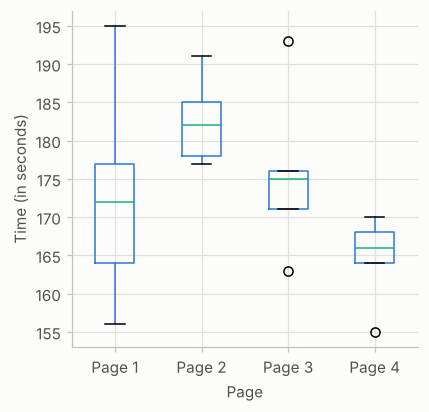

In [36]:
# BOOK CODE (ANOVA): the session times on four pages
four_sessions = pd.read_csv(FOUR_SESSIONS_CSV)

ax = four_sessions.boxplot(by='Page', column='Time',
                           figsize=(4, 4))
ax.set_xlabel('Page')
ax.set_ylabel('Time (in seconds)')
plt.suptitle('')
plt.title('')

plt.tight_layout()
plt.show()

In [37]:
# BOOK CODE (ANOVA): the first rows of the data
print(pd.read_csv(FOUR_SESSIONS_CSV).head())

     Page  Time
0  Page 1   164
1  Page 2   178
2  Page 3   175
3  Page 4   155
4  Page 1   172


The statistic of the permutation test is the variance of the four page means. The code of the script takes it with `.var()[0]`, which relied on a Series falling back to its position when the label `0` does not exist; recent versions of pandas have removed that fallback and the line raises a `KeyError`. The cell uses `.var().iloc[0]` (the same value, by position) and marks the change.

In [38]:
# BOOK CODE (ANOVA): the observed variance of the page means
observed_variance = four_sessions.groupby('Page').mean().var().iloc[0]  # CHANGED: the script has .var()[0]
print('Observed means:', four_sessions.groupby('Page').mean().values.ravel())
print('Variance:', observed_variance)

Observed means: [172.8 182.6 175.6 164.6]
Variance: 55.426666666666655


`perm_test` shuffles all 20 times, regroups them by the original page labels and returns the variance of the page means. It uses NumPy's random generator, so the `random.seed(1)` that the script sets before its loop has no influence on it; the cells below seed NumPy (marked `NOT IN THE BOOK`) so that every run gives the same output.

In [39]:
# BOOK CODE (ANOVA): one permutation of the times over the pages
np.random.seed(2024)  # NOT IN THE BOOK: the book's single call has no seed

# Permutation test example with stickiness
def perm_test(df):
    df = df.copy()
    df['Time'] = np.random.permutation(df['Time'].values)
    return df.groupby('Page').mean().var().iloc[0]  # CHANGED: the script has .var()[0]

print(perm_test(four_sessions))

3.6399999999999806


Pr(Prob) 0.07366666666666667


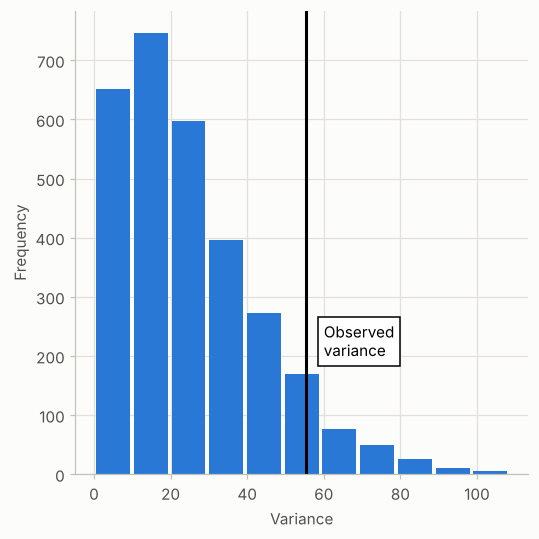

In [40]:
# BOOK CODE (ANOVA): 3,000 permutations and the p-value
random.seed(1)
np.random.seed(2025)  # NOT IN THE BOOK: perm_test draws from NumPy's generator, which random.seed does not set
perm_variance = [perm_test(four_sessions) for _ in range(3000)]
print('Pr(Prob)', np.mean([var > observed_variance for var in perm_variance]))

fig, ax = plt.subplots(figsize=(5, 5))
ax.hist(perm_variance, bins=11, rwidth=0.9)
ax.axvline(x = observed_variance, color='black', lw=2)
ax.text(60, 200, 'Observed\nvariance', bbox={'facecolor':'white'})
ax.set_xlabel('Variance')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The classical analysis: the ANOVA table of a linear model `Time ~ Page` with `statsmodels`, and the same $F$-test with `scipy.stats.f_oneway`. (The script prints the statistic and the p-value of `f_oneway` divided by 2; see the output analysis.)

In [41]:
# BOOK CODE (ANOVA): the ANOVA table (F-statistic)
# We can compute an ANOVA table using statsmodel.

model = smf.ols('Time ~ Page', data=four_sessions).fit()

aov_table = sm.stats.anova_lm(model)
print(aov_table)

res = stats.f_oneway(four_sessions[four_sessions.Page == 'Page 1'].Time,
                     four_sessions[four_sessions.Page == 'Page 2'].Time,
                     four_sessions[four_sessions.Page == 'Page 3'].Time,
                     four_sessions[four_sessions.Page == 'Page 4'].Time)
print(f'F-Statistic: {res.statistic / 2:.4f}')
print(f'p-value: {res.pvalue / 2:.4f}')

            df  sum_sq     mean_sq         F    PR(>F)
Page       3.0   831.4  277.133333  2.739825  0.077586
Residual  16.0  1618.4  101.150000       NaN       NaN
F-Statistic: 1.3699
p-value: 0.0388


**Output analysis.**

* **The data.** The boxplot shows page 2 with the longest sessions (mean 182.6) and page 4 with the shortest (mean 164.6), page 1 (172.8) and page 3 (175.6) in between. The spreads differ: the standard deviation is 14.8 on page 1 and 11.0 on page 3, but only 5.7 and 5.8 on pages 2 and 4 (extra 8(b)). The table of the head shows that the file is in long format, with the pages alternating.
* **The statistic.** The variance of the four page means is 55.43. A single permutation of the times over the pages gives 3.64, much smaller, as one would expect for shuffled data.
* **The permutation test.** 7.4% of the 3,000 permuted variances exceed the observed one (the histogram is skewed to the right and the observed value is in its tail). It is not significant at 5%; it is not far either.
* **The ANOVA table.** $F = 2.7398$ with 3 and 16 degrees of freedom and $p = 0.0776$; the sums of squares are 831.4 between and 1,618.4 within the pages (mean squares 277.13 and 101.15). The permutation p-value (0.074) and the $F$ p-value (0.078) agree, and both leave the question open: the evidence for a difference between the four pages is weak.
* **The two last lines are not the test.** `f_oneway` returns the same $F = 2.7398$ and $p = 0.0776$ as the table, but the script prints them divided by 2: 1.3699 and 0.0388. The $F$ test is already one-sided (only a large $F$ speaks against the null hypothesis) and the $F$ statistic is not a signed difference, so there is nothing to halve. Read as printed, the second number would suggest a significant result at 5%, which is not what the data show. The values of the table are the ones to use (see the book-vs-library notes).

### Extra experiments

**(a) The $F$ statistic by hand, and the permutation test on $F$.** The cell builds the ANOVA table from the definitions, shows how the statistic of the script (the variance of the four means) is related to the sum of squares between the pages, and runs 100,000 permutations with three statistics: the variance of the means, the sum of squares between pages, and $F$. It then compares their p-values with the one of the $F$-distribution and draws the permutation distribution of $F$ with the density of $F_{3,16}$.

                         df  sum of squares  mean square       F  p-value
between pages             3           831.4     277.1333  2.7398   0.0776
within pages (residual)  16          1618.4     101.1500     NaN      NaN
total                    19          2449.8          NaN     NaN      NaN

variance of the page means (the statistic of the script): 55.4267; x 5 x 3 = 831.4000 = the sum of squares between the pages
number of different ways to split the 20 sessions into 4 groups of 5: 11,732,745,024
             statistic  observed  permutation p-value
 variance of the means   55.4267               0.0808
sum of squares between  831.4000               0.0808
                     F    2.7398               0.0808
p-value of the F distribution with 3 and 16 degrees of freedom: 0.0776


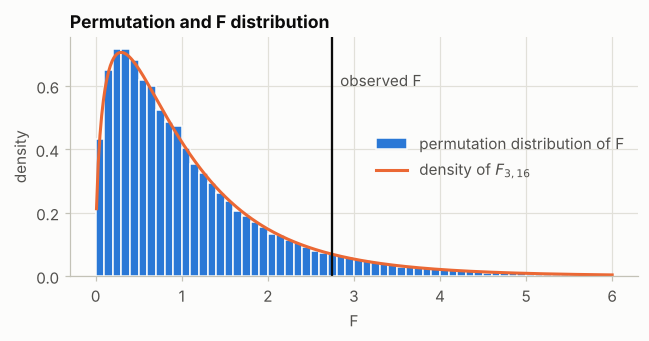

In [42]:
# EXTRA (a): the ANOVA table by hand, and permutation tests with three equivalent statistics
from math import factorial

labels = four_sessions['Page'].to_numpy()
y_all = four_sessions['Time'].to_numpy(float)
levels = np.unique(labels)
g, N = len(levels), len(y_all)
group_sizes = np.array([(labels == level).sum() for level in levels])
group_means = np.array([y_all[labels == level].mean() for level in levels])
grand = y_all.mean()
ss_total = ((y_all - grand) ** 2).sum()
ss_between = (group_sizes * (group_means - grand) ** 2).sum()
ss_within = ss_total - ss_between
ms_between, ms_within = ss_between / (g - 1), ss_within / (N - g)
f_hand = ms_between / ms_within
p_f = stats.f.sf(f_hand, g - 1, N - g)
print(pd.DataFrame({"df": [g - 1, N - g, N - 1], "sum of squares": [ss_between, ss_within, ss_total], "mean square": [ms_between, ms_within, np.nan],
                    "F": [f_hand, np.nan, np.nan], "p-value": [p_f, np.nan, np.nan]}, index=["between pages", "within pages (residual)", "total"]).round(4).to_string())
print(f"\nvariance of the page means (the statistic of the script): {observed_variance:.4f}; x {group_sizes[0]} x {g - 1} = {observed_variance * group_sizes[0] * (g - 1):.4f} = the sum of squares between the pages")
print(f"number of different ways to split the {N} sessions into 4 groups of 5: {factorial(N) // factorial(5) ** 4:,}")

rng = np.random.default_rng(171)
R = 100_000
y_perm = y_all[rng.random((R, N)).argsort(axis=1)]                          # R shuffled copies of the times
perm_means = np.stack([y_perm[:, labels == level].mean(axis=1) for level in levels], axis=1)
var_perm = perm_means.var(axis=1, ddof=1)
ssb_perm = (group_sizes * (perm_means - grand) ** 2).sum(axis=1)
f_perm = (ssb_perm / (g - 1)) / ((ss_total - ssb_perm) / (N - g))
tol = 1e-9
print(pd.DataFrame({"statistic": ["variance of the means", "sum of squares between", "F"],
                    "observed": [observed_variance, ss_between, f_hand],
                    "permutation p-value": [np.mean(var_perm >= observed_variance - tol), np.mean(ssb_perm >= ss_between - tol), np.mean(f_perm >= f_hand - tol)]}).round(4).to_string(index=False))
print(f"p-value of the F distribution with {g - 1} and {N - g} degrees of freedom: {p_f:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(f_perm, bins=60, range=(0, 6), density=True, color=PALETTE[0], edgecolor=SURFACE, label="permutation distribution of F")
grid_f = np.linspace(0.01, 6, 300)
ax.plot(grid_f, stats.f.pdf(grid_f, g - 1, N - g), color=PALETTE[1], label=r"density of $F_{3,16}$")
ax.axvline(f_hand, color=INK, lw=1.5)
ax.text(f_hand + 0.1, 0.6, "observed F", color=INK_SOFT)
ax.set_xlabel("F"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Permutation and F distribution")
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The table built by hand has the sums of squares 831.4 (3 degrees of freedom), 1,618.4 (16) and 2,449.8 (19), the mean squares 277.13 and 101.15, $F = 2.7398$ and $p = 0.0776$: the same as `statsmodels`. The variance of the page means that the script permutes (55.4267) times $5 \times 3$ is 831.4, the sum of squares between the pages, so the script's statistic is the numerator of $F$ up to a constant.
* There are 11,732,745,024 ways to split the 20 sessions in four groups of five. With 100,000 random permutations the three statistics (variance of the means, sum of squares between, $F$) give the same p-value, 0.0808, for the reason in the theory block: for every shuffle $SS_T$ is the same, so $F$ and $SS_B$ are increasing functions of each other.
* The $F$-distribution gives 0.0776, 0.003 below the permutation p-value (the Monte Carlo standard error is 0.0009). The permutation distribution of $F$ is close to the density of $F_{3,16}$ in the figure, although only 5 observations per page are available. The script's own estimate (0.0737 from 3,000 permutations) has a standard error of 0.005.

**(b) Which pages differ? Pairwise comparisons.** The six pairs of pages are compared with Welch $t$-tests (unadjusted, and adjusted with Bonferroni and Holm) and with Tukey's honest significant difference, which uses the pooled variance of all four pages. The omnibus $F$ p-value is repeated for reference.

In [43]:
# EXTRA (b): pairwise comparisons of the four pages
from itertools import combinations
from statsmodels.stats.multitest import multipletests

samples = {level: y_all[labels == level] for level in levels}
tukey = stats.tukey_hsd(*samples.values())
index = {level: i for i, level in enumerate(levels)}
pairs = list(combinations(levels, 2))
raw = np.array([stats.ttest_ind(samples[a], samples[b], equal_var=False).pvalue for a, b in pairs])
table = pd.DataFrame({
    "difference of the means": [samples[b].mean() - samples[a].mean() for a, b in pairs],
    "Welch p-value": raw,
    "Bonferroni": multipletests(raw, method="bonferroni")[1],
    "Holm": multipletests(raw, method="holm")[1],
    "Tukey HSD": [tukey.pvalue[index[a], index[b]] for a, b in pairs],
}, index=[f"{a} vs {b}" for a, b in pairs])
print(f"omnibus F-test p-value: {p_f:.4f}; standard deviations of the pages: {[round(float(s.std(ddof=1)), 1) for s in samples.values()]}")
print(table.round(4).to_string())

omnibus F-test p-value: 0.0776; standard deviations of the pages: [14.8, 5.7, 11.0, 5.8]
                  difference of the means  Welch p-value  Bonferroni    Holm  Tukey HSD
Page 1 vs Page 2                      9.8         0.2227      1.0000  0.8907     0.4379
Page 1 vs Page 3                      2.8         0.7431      1.0000  0.8907     0.9706
Page 1 vs Page 4                     -8.2         0.2978      1.0000  0.8907     0.5825
Page 2 vs Page 3                     -7.0         0.2528      1.0000  0.8907     0.6943
Page 2 vs Page 4                    -18.0         0.0011      0.0067  0.0067     0.0531
Page 3 vs Page 4                    -11.0         0.0947      0.5680  0.4733     0.3416


**Analysis of extra (b).**

* The omnibus test gave $p = 0.0776$. Among the six pairs, only pages 2 and 4 stand out: the mean of page 4 is 18.0 seconds below that of page 2 and the Welch $p$-value is 0.0011, which is 0.0067 after Bonferroni or Holm adjustment (it is the smallest of the six, so Holm multiplies it by 6 as well). The next pair, pages 3 and 4, has 0.0947 unadjusted and 0.568 and 0.473 adjusted; the other pairs are above 0.22 unadjusted.
* **Tukey's HSD**, which uses the pooled standard deviation of all four pages, gives 0.0531 for the pages 2 and 4: just above 5%. The two methods disagree on the same pair, because they disagree on the variance: pages 2 and 4 have a standard deviation of about 5.7 each, whereas the pooled standard deviation is $\sqrt{101.15} = 10.06$, driven by the pages 1 and 3 (14.8 and 11.0). Whether the variance is common to the four pages cannot be settled with five observations each.
* The omnibus test was not significant, and one pair out of six is highly significant with one method and borderline with the other. This is the situation that multiple-testing rules and the omnibus test are there for: the conclusion "page 2 is better than page 4" should be treated as a lead to verify in a new experiment, not as a result.

**(c) A simulated two-way ANOVA.** Time on a page is simulated for two designs (old, new) on three devices (desktop, mobile, tablet), with 30 users per combination and noise of standard deviation 10. In the first scenario the new design adds 6 seconds on every device (no interaction); in the second it adds 12 seconds on the desktop, nothing on mobile and removes 12 on the tablet. The cell fits `time ~ C(design) * C(device)`, prints the ANOVA tables and draws the mean times.

additive: the new design adds 6 on every device
                         sum_sq     df        F  PR(>F)
C(design)             2194.5930    1.0  23.4668  0.0000
C(device)             1886.3108    2.0  10.0852  0.0001
C(design):C(device)    350.1669    2.0   1.8722  0.1569
Residual             16272.3310  174.0      NaN     NaN 

interaction: the new design adds 12 / 0 / -12
                         sum_sq     df        F  PR(>F)
C(design)              104.1713    1.0   1.2182  0.2712
C(device)            13142.1946    2.0  76.8447  0.0000
C(design):C(device)   3068.6046    2.0  17.9427  0.0000
Residual             14878.9898  174.0      NaN     NaN 



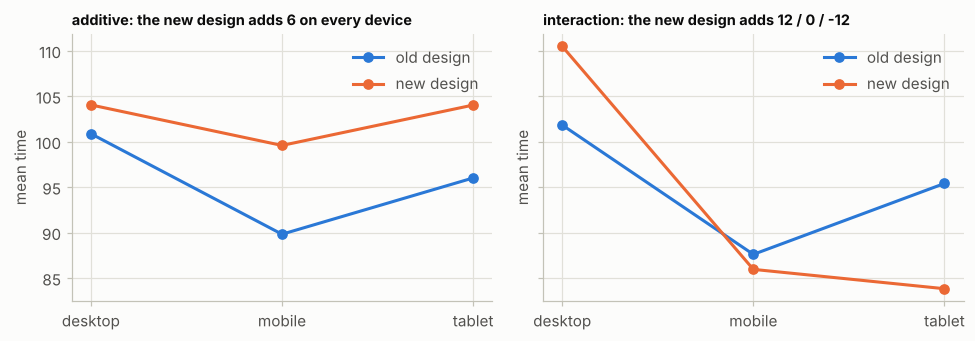

In [44]:
# EXTRA (c): a two-way ANOVA with and without an interaction
rng = np.random.default_rng(172)
n_cell = 30
device_effect = {"desktop": 0.0, "mobile": -10.0, "tablet": -4.0}
scenarios = {"additive: the new design adds 6 on every device": {"desktop": 6, "mobile": 6, "tablet": 6},
             "interaction: the new design adds 12 / 0 / -12": {"desktop": 12, "mobile": 0, "tablet": -12}}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (name, new_effect) in zip(axes, scenarios.items()):
    rows = []
    for design in ("old", "new"):
        for device, base in device_effect.items():
            mean = 100 + base + (new_effect[device] if design == "new" else 0)
            rows += [{"design": design, "device": device, "time": value} for value in rng.normal(mean, 10, size=n_cell)]
    data = pd.DataFrame(rows)
    fit = smf.ols("time ~ C(design) * C(device)", data=data).fit()
    print(name)
    print(sm.stats.anova_lm(fit, typ=2).round(4).to_string(), "\n")
    cell_means = data.groupby(["device", "design"]).time.mean().unstack()[["old", "new"]].loc[["desktop", "mobile", "tablet"]]
    for color, design in zip(PALETTE, ("old", "new")):
        ax.plot(cell_means.index, cell_means[design], marker="o", color=color, label=f"{design} design")
    ax.set_title(name, fontsize=9.5); ax.set_ylabel("mean time")
    ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* **Additive scenario** (the new design adds 6 seconds on every device): the design has $F = 23.47$ and the device $F = 10.09$ ($p = 0.0001$), both significant, and the interaction is not ($F = 1.87$, $p = 0.157$); the lines of the plot are nearly parallel. The degrees of freedom are 1, 2, 2 and 174 ($= 180 - 6$).
* **Interaction scenario** (the new design adds 12, 0 and -12 seconds on desktop, mobile and tablet): the test of the *design* main effect is not significant ($F = 1.22$, $p = 0.271$), because the effects average to zero over the devices, although the design has a large effect on two of the three devices. The interaction has $F = 17.94$ (a p-value that rounds to 0.0000), and the lines of the plot cross.
* When the interaction is large the main effect of one factor is not a useful summary, because "the effect of the new design" is not one number but depends on the device. Look at the interaction first; if it is there, describe the effects within the levels of the other factor.

**(d) The $F$-test when the variances and the group sizes differ.** Three groups with the *same* mean (0) are drawn 20,000 times for several combinations of sizes and standard deviations, and tested at the 5% level with the classical $F$-test and with Welch's ANOVA (which does not assume equal variances; the formula is written out in the cell and checked against `statsmodels` for one data set).

In [45]:
# EXTRA (d): false rejection rate of the classical F-test and of Welch's ANOVA, equal means
from statsmodels.stats.oneway import anova_oneway


def anova_p_values(samples):
    """p-values of the classical F-test and of Welch's ANOVA for every row; `samples` is a list of arrays with shape (repetitions, n_i)."""
    k = len(samples)
    n_i = np.array([s.shape[1] for s in samples])
    means = np.stack([s.mean(axis=1) for s in samples], axis=1)
    variances = np.stack([s.var(axis=1, ddof=1) for s in samples], axis=1)
    total = n_i.sum()
    grand_mean = (means * n_i).sum(axis=1) / total
    ms_b = (n_i * (means - grand_mean[:, None]) ** 2).sum(axis=1) / (k - 1)
    ms_w = ((n_i - 1) * variances).sum(axis=1) / (total - k)
    p_classic = stats.f.sf(ms_b / ms_w, k - 1, total - k)
    w = n_i / variances                                                    # weights n_i / s_i^2
    w_sum = w.sum(axis=1)
    weighted_mean = (w * means).sum(axis=1) / w_sum
    numerator = (w * (means - weighted_mean[:, None]) ** 2).sum(axis=1) / (k - 1)
    h = (((1 - w / w_sum[:, None]) ** 2) / (n_i - 1)).sum(axis=1)
    f_welch = numerator / (1 + 2 * (k - 2) / (k ** 2 - 1) * h)
    p_welch = stats.f.sf(f_welch, k - 1, (k ** 2 - 1) / (3 * h))
    return p_classic, p_welch


rng = np.random.default_rng(174)
check = [rng.normal(0, sd, size=(1, n)) for n, sd in ((5, 4), (10, 2), (40, 1))]
ours = anova_p_values(check)
library = anova_oneway([s[0] for s in check], use_var="unequal")
print(f"check against statsmodels on one data set: Welch p-value {ours[1][0]:.6f} (here) and {library.pvalue:.6f} (statsmodels)")

repetitions = 20_000
rows = []
for label, sizes, sds in (("equal sizes, equal sd (10, 10, 10 with sd 1)", (10, 10, 10), (1, 1, 1)),
                          ("equal sizes, sd 4, 2, 1 (15 each)", (15, 15, 15), (4, 2, 1)),
                          ("sizes 5, 10, 40 with sd 4, 2, 1 (small groups noisy)", (5, 10, 40), (4, 2, 1)),
                          ("sizes 5, 10, 40 with sd 1, 2, 4 (large group noisy)", (5, 10, 40), (1, 2, 4))):
    p_classic, p_welch = anova_p_values([rng.normal(0, sd, size=(repetitions, n)) for n, sd in zip(sizes, sds)])
    rows.append({"scenario": label, "classical F-test": np.mean(p_classic < 0.05), "Welch ANOVA": np.mean(p_welch < 0.05)})
print(f"standard error of a rate near 0.05 with {repetitions:,} repetitions: {np.sqrt(0.05 * 0.95 / repetitions):.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

check against statsmodels on one data set: Welch p-value 0.641011 (here) and 0.641011 (statsmodels)
standard error of a rate near 0.05 with 20,000 repetitions: 0.0015
                                            scenario  classical F-test  Welch ANOVA
        equal sizes, equal sd (10, 10, 10 with sd 1)            0.0496       0.0492
                   equal sizes, sd 4, 2, 1 (15 each)            0.0716       0.0495
sizes 5, 10, 40 with sd 4, 2, 1 (small groups noisy)            0.3790       0.0600
 sizes 5, 10, 40 with sd 1, 2, 4 (large group noisy)            0.0012       0.0473


**Analysis of extra (d).**

* The Welch ANOVA written in the cell reproduces `statsmodels` (0.641011 for one data set, equal to six decimals).
* With equal variances and equal sizes both tests keep their level (4.96% and 4.92%; the standard error of each rate is 0.0015). With equal sizes of 15 but standard deviations 4, 2 and 1 the classical $F$-test rejects 7.16% of the true nulls (the Welch test 4.95%).
* The combination of unequal sizes and unequal variances is the problem. If the smallest group (5) has the largest standard deviation (4) and the largest group (40) the smallest (1), the classical $F$-test rejects 37.9% of the experiments with equal means; in the opposite arrangement it rejects 0.12%. The Welch ANOVA stays between 4.7% and 6.0%; the 6.0% of the worst case is above the nominal level by more than 6 standard errors, probably the approximation at work with a group of 5 (this was not tested here).
* As with the permutation test of extra 2(b), the assumption that is violated is the equality of the variances, and the safe course is to use a version of the test that does not depend on it when the groups are of different sizes. In the four-page experiment the groups are of equal size, and the sample standard deviations (5.7 to 14.8) are within the range of the equal-size example above (4 to 1), where the rate was 7.2%; this suggests that the p-value of the pages is not badly distorted, although a standard deviation from five observations is itself very uncertain.

---
## 9. Chi-square test

*Book section: "Chi-Square Test" (chi-square test: a resampling approach, the chi-square distribution, Fisher's exact test, relevance for data science; the example of scientific fraud). The code of the script tests whether three headlines differ in their click rates and plots the digit frequencies of a case of suspected fraud.*

### Summary

* The **chi-square test** is used with **counts**: it tests whether the observed counts in a table are consistent with a null hypothesis, typically that two categorical variables are independent, or that counts follow a given distribution. It was introduced by Karl Pearson in 1900 (see Chapter 2).
* The example of the script: three headlines are each shown to 1,000 visitors and the clicks are recorded: 14, 8 and 12 (34 clicks in all). Do the headlines differ? The null hypothesis is that all the headlines have the same click rate. Then the **expected** number of clicks per headline is $34/3 \approx 11.3$ and of non-clicks about $988.7$.
* The **chi-square statistic** adds, over all cells of the table, the squared difference between observed and expected count divided by the expected count. (The quantity $(\text{observed} - \text{expected})/\sqrt{\text{expected}}$ is the **Pearson residual**, so the statistic is the sum of the squared Pearson residuals.) Large values mean that the table is far from what the null hypothesis predicts.
* **Resampling approach:** put 34 ones (clicks) and 2,966 zeros in a box, shuffle, deal out three groups of 1,000, compute the statistic, repeat 2,000 times and see how often the shuffled statistic exceeds the observed one. The script also does a variant in which every group of 1,000 is drawn from the full box on its own.
* **The chi-square distribution** is the reference distribution of the classical test. Its shape depends on the degrees of freedom (for the table of the example, $(2-1)(3-1) = 2$); the test needs no simulation, but the distribution is only an approximation, good when the expected counts are not small. `scipy.stats.chi2_contingency` gives the statistic, the p-value, the degrees of freedom and the expected counts.
* **Fisher's exact test** gives the exact p-value for a table with a small number of counts, by enumerating the tables with the same margins; the script only mentions it (see the book-vs-library notes).
* **Scientific fraud:** the book uses the chi-square test on the digit frequencies in a data set from a case of suspected scientific fraud, as an example of how counts that are too regular or too irregular compared with a chance model can raise a flag. The bar chart in the script only shows the frequencies; the notebook adds the test in extra 9(d) and treats it as a statistical exercise.
* The chi-square test also appears wherever a data scientist asks whether counts depend on a category (conversion by channel, defects by machine) and, in many cases, as a quick filter for features.

### Theory

**The statistic.** For a table with observed counts $O_{ij}$, row totals $R_i$, column totals $C_j$ and grand total $N$, the expected counts under independence are $E_{ij} = R_iC_j/N$ and
$$\chi^2 = \sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}} = \sum_{i,j} r_{ij}^2, \qquad r_{ij} = \frac{O_{ij}-E_{ij}}{\sqrt{E_{ij}}}.$$
For large expected counts $\chi^2 \approx \chi^2_{\nu}$ with $\nu = (r-1)(c-1)$ degrees of freedom under $H_0$ (Pearson, 1900; Fisher, 1922 corrected the degrees of freedom for estimated parameters). The degrees of freedom are the number of cells that can be filled freely once the margins are fixed (section 7). The mean of $\chi^2_\nu$ is $\nu$ and its variance is $2\nu$.

**A goodness-of-fit test** compares $k$ observed counts $O_i$ with expected counts $E_i = Np_i$ of a model: $\chi^2 = \sum (O_i - E_i)^2/E_i$ with $k - 1$ degrees of freedom (minus one for each parameter estimated from the data). **Cramér's $V$**, $\sqrt{\chi^2/(N\min(r-1,c-1))}$, measures the strength of the association on a scale from 0 to 1, because $\chi^2$ itself grows with $N$ (section 4). The **likelihood-ratio statistic** $G = 2\sum O\ln(O/E)$ has the same asymptotic distribution.

**Two null models for the resampling.** Shuffling the box of 34 clicks keeps the total number of clicks at 34 in every resample: the p-value is *conditional on the margins* and the exact distribution of the counts is the multivariate hypergeometric distribution. Drawing each group independently from the box lets the total vary: the counts of the groups are then independent hypergeometric variables. Both have the same expected counts; their distributions differ a little (extra 9(b)).

**When the approximation fails.** The chi-square distribution is a limit for large counts. With expected counts below about 5 the statistic has a discrete distribution with few values and the p-value of the $\chi^2$-distribution can be quite wrong; then an exact or Monte Carlo test is preferable (extra 9(c)). For $2\times 2$ tables, Fisher's exact test uses the hypergeometric distribution (section 4).

### Book code

The click data are in a long format (headline, click or no click, count); the script reshapes it into the table of the book (Table 3-4), with the clicks and no-clicks in the rows and the headlines in the columns.

In [46]:
# BOOK CODE (Chi-Square Test): Table 3-4, the clicks of three headlines
click_rate = pd.read_csv(CLICK_RATE_CSV)
clicks = click_rate.pivot(index='Click', columns='Headline', values='Rate')
print(clicks)

Headline  Headline A  Headline B  Headline C
Click                                       
Click             14           8          12
No-click         986         992         988


Table 3-5 of the book shows the counts that the null hypothesis expects: the same row average for every headline.

In [47]:
# BOOK CODE (Chi-Square Test): Table 3-5, the expected counts under the null hypothesis
row_average = clicks.mean(axis=1)
pd.DataFrame({
    'Headline A': row_average,
    'Headline B': row_average,
    'Headline C': row_average,
})

,Headline A,Headline B,Headline C
Click,,,
Click,11.333333,11.333333,11.333333
No-click,988.666667,988.666667,988.666667


The resampling approach. The function `chi2` of the script adds up the squared residuals over the two rows of a table, given the expected clicks and no-clicks of one headline; `perm_fun` shuffles the box of 34 clicks and 2,966 zeros, deals three groups of 1,000 and returns the statistic. (The script reuses the name `perm_fun` of section 3; from here on it denotes this function.) The script does not set a seed; the cell does.

In [48]:
# BOOK CODE (Chi-Square Test: A Resampling Approach): shuffle the box of clicks and compare the statistic with the observed one
random.seed(1)  # NOT IN THE BOOK: the script has no seed in this cell

# Resampling approach
box = [1] * 34
box.extend([0] * 2966)
random.shuffle(box)

def chi2(observed, expected):
    pearson_residuals = []
    for row, expect in zip(observed, expected):
        pearson_residuals.append([(observe - expect) ** 2 / expect
                                  for observe in row])
    # return sum of squares
    return np.sum(pearson_residuals)

expected_clicks = 34 / 3
expected_noclicks = 1000 - expected_clicks
expected = [expected_clicks, expected_noclicks]
chi2observed = chi2(clicks.values, expected)

def perm_fun(box):
    random.shuffle(box)
    sample_clicks = [sum(box[0:1000]),
                     sum(box[1000:2000]),
                     sum(box[2000:3000])]
    sample_noclicks = [1000 - n for n in sample_clicks]
    return chi2([sample_clicks, sample_noclicks], expected)

perm_chi2 = [perm_fun(box) for _ in range(2000)]

resampled_p_value = sum(perm_chi2 > chi2observed) / len(perm_chi2)
print(f'Observed chi2: {chi2observed:.4f}')
print(f'Resampled p-value: {resampled_p_value:.4f}')

Observed chi2: 1.6659
Resampled p-value: 0.4660


The classical test of the same table with `scipy.stats.chi2_contingency`.

In [49]:
# BOOK CODE (Chi-Square Test): the chi-square test of the table
chisq, pvalue, df, expected = stats.chi2_contingency(clicks)
print(f'Observed chi2: {chisq:.4f}')
print(f'p-value: {pvalue:.4f}')

Observed chi2: 1.6659
p-value: 0.4348


The alternative resampling of the script: each headline draws its own 1,000 visitors from the box (the variable `expected` is set again to the list of expected clicks and no-clicks, because the previous cell has overwritten it with an array). Despite the name of the function and the comment, `random.sample` draws *without* replacement within a headline; what is independent is the three draws, not the positions of the box.

In [50]:
# BOOK CODE (Chi-Square Test): an alternative approach using sampling from the box for each headline
random.seed(2)  # NOT IN THE BOOK: the script has no seed in this cell

# alternative approach using sampling with replacement
expected = [expected_clicks, expected_noclicks]
def sample_with_replacement(box):
    sample_clicks = [sum(random.sample(box, 1000)),
                     sum(random.sample(box, 1000)),
                     sum(random.sample(box, 1000))]
    sample_noclicks = [1000 - n for n in sample_clicks]
    return chi2([sample_clicks, sample_noclicks], expected)

perm_chi2 = [sample_with_replacement(box) for _ in range(2000)]

resampled_p_value = sum(perm_chi2 > chi2observed) / len(perm_chi2)
print(f'Observed chi2: {chi2observed:.4f}')
print(f'Resampled p-value: {resampled_p_value:.4f}')

Observed chi2: 1.6659
Resampled p-value: 0.4990


The script then draws the density of the chi-square distribution for 1, 2, 5, 10 and 20 degrees of freedom.

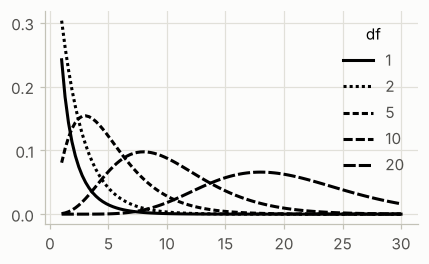

In [51]:
# BOOK CODE (Chi-Square Test): the chi-square distribution for several degrees of freedom
x = [1 + i * (30 - 1) / 99 for i in range(100)]

chi = pd.DataFrame({
    'x': x,
    'chi_1': stats.chi2.pdf(x, df=1),
    'chi_2': stats.chi2.pdf(x, df=2),
    'chi_5': stats.chi2.pdf(x, df=5),
    'chi_10': stats.chi2.pdf(x, df=10),
    'chi_20': stats.chi2.pdf(x, df=20),
})
fig, ax = plt.subplots(figsize=(4, 2.5))
ax.plot(chi.x, chi.chi_1, color='black', linestyle='-', label='1')
ax.plot(chi.x, chi.chi_2, color='black', linestyle=(0, (1, 1)), label='2')
ax.plot(chi.x, chi.chi_5, color='black', linestyle=(0, (2, 1)), label='5')
ax.plot(chi.x, chi.chi_10, color='black', linestyle=(0, (3, 1)), label='10')
ax.plot(chi.x, chi.chi_20, color='black', linestyle=(0, (4, 1)), label='20')
ax.legend(title='df')

plt.tight_layout()
plt.show()

The section of the book on Fisher's exact test has no running code in the script (only comments, described in the book-vs-library notes). The last piece of code of the section is the bar chart of the frequencies of the digits in the data of the case of suspected fraud.

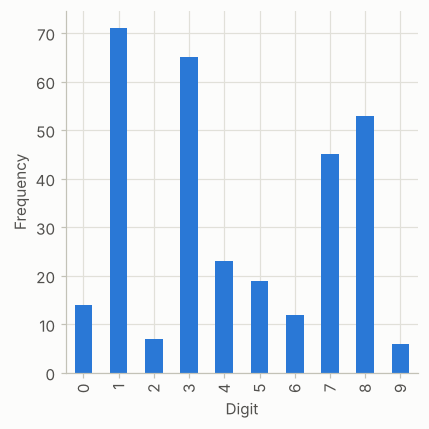

In [52]:
# BOOK CODE (Chi-Square Test, scientific fraud): the frequencies of the digits
imanishi = pd.read_csv(IMANISHI_CSV)
imanishi.columns = [c.strip() for c in imanishi.columns]
ax = imanishi.plot.bar(x='Digit', y=['Frequency'], legend=False,
                      figsize=(4, 4))
ax.set_xlabel('Digit')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Output analysis.**

* **Table 3-4** has 14, 8 and 12 clicks for headlines A, B and C out of 1,000 visitors each (986, 992 and 988 non-clicks). **Table 3-5** shows what the null hypothesis expects: the row averages, 11.33 clicks and 988.67 non-clicks for each headline.
* **Resampling (seed 1).** The statistic of the observed table is 1.6659, and 46.6% of the shuffled boxes give a larger value, so the p-value is 0.4660: the differences between the headlines are well within what chance gives.
* **The chi-square test** gives the same statistic (1.6659) and the p-value 0.4348 (2 degrees of freedom). The resampled value differs by 0.031, which is 2.8 standard errors of the resampling (0.011 with 2,000 shuffles); extra 9(b) shows that the exact p-value is 0.4824, 1.5 standard errors from the resampled value, while the chi-square approximation is a little optimistic for this table.
* **The alternative resampling** (each headline draws its own 1,000 from the box) gives 0.4990; its exact value is 0.4862 (extra 9(b)), 1.1 standard errors away.
* **The figure of the chi-square densities.** The curves start at $x = 1$, so the part to the left of 1 is cut off. With 1 or 2 degrees of freedom the density falls from its value at zero; for 5, 10 and 20 degrees of freedom the density has a peak (at about 3, 8 and 18, the mode being $\nu - 2$) and the curves become wider and flatter as the degrees of freedom grow.
* **The digits.** The frequencies run from 6 (digit 9) to 71 (digit 1); the digits 1, 3, 8 and 7 are the most frequent (71, 65, 53, 45) and 9, 2, 6 and 0 the least (6, 7, 12, 14). The bar chart does not look like a uniform distribution; how unlikely that is under a chance model is the subject of extra 9(d).

### Extra experiments

**(a) The statistic by hand, residuals and effect size.** The cell computes the expected counts from the margins, the Pearson residuals, the statistic and its p-value from the chi-square distribution, Cramér's $V$ and the likelihood-ratio statistic $G$, and compares them with `scipy`.

In [53]:
# EXTRA (a): the chi-square test of the click table from the definitions
O = clicks.to_numpy(float)                                               # rows: Click, No-click; columns: the three headlines
row_totals, col_totals, grand_total = O.sum(axis=1), O.sum(axis=0), O.sum()
E = np.outer(row_totals, col_totals) / grand_total
residuals = (O - E) / np.sqrt(E)
chi2_hand = (residuals ** 2).sum()
dof = (O.shape[0] - 1) * (O.shape[1] - 1)
cramer_v = np.sqrt(chi2_hand / (grand_total * (min(O.shape) - 1)))
g_stat, g_p, _, _ = stats.chi2_contingency(O, lambda_="log-likelihood")
print("expected counts (row total x column total / N):")
print(pd.DataFrame(E, index=clicks.index, columns=clicks.columns).round(3).to_string())
print("\nPearson residuals (observed - expected) / sqrt(expected):")
print(pd.DataFrame(residuals, index=clicks.index, columns=clicks.columns).round(3).to_string())
print(f"\nchi-square statistic {chi2_hand:.4f} with {dof} degrees of freedom, p-value {stats.chi2.sf(chi2_hand, dof):.4f} (scipy: {chisq:.4f}, {pvalue:.4f})")
print(f"the script's expected clicks, 34/3 = {34 / 3:.3f}, are the first row of the table above; the mean of the chi-square distribution is {dof} and its sd {np.sqrt(2 * dof):.2f}")
print(f"Cramer's V = {cramer_v:.4f}; likelihood-ratio statistic G = {g_stat:.4f}, p-value {g_p:.4f}")
print(f"smallest expected count: {E.min():.2f}")

expected counts (row total x column total / N):
Headline  Headline A  Headline B  Headline C
Click                                       
Click         11.333      11.333      11.333
No-click     988.667     988.667     988.667

Pearson residuals (observed - expected) / sqrt(expected):
Headline  Headline A  Headline B  Headline C
Click                                       
Click          0.792      -0.990       0.198
No-click      -0.085       0.106      -0.021

chi-square statistic 1.6659 with 2 degrees of freedom, p-value 0.4348 (scipy: 1.6659, 0.4348)
the script's expected clicks, 34/3 = 11.333, are the first row of the table above; the mean of the chi-square distribution is 2 and its sd 2.00
Cramer's V = 0.0236; likelihood-ratio statistic G = 1.7344, p-value 0.4201
smallest expected count: 11.33


**Analysis of extra (a).**

* The expected counts are 11.333 clicks and 988.667 non-clicks for every headline, the numbers of Table 3-5. The Pearson residuals of the click row are +0.792, -0.990 and +0.198, those of the non-click row -0.085, 0.106 and -0.021 (the same deviations, divided by the larger square root of the expected count). All of them are smaller than 1 in absolute value, and under the null hypothesis a residual is about as large as 1 in typical size.
* The statistic is $1.6659 = \sum r^2$ with 2 degrees of freedom, $p = 0.4348$, identical to `scipy`. Its mean under the null is 2, so the observed value is below the average. Headline B (8 clicks against 11.3 expected) contributes most (the residual -0.990).
* The effect size is tiny: Cramér's $V = 0.0236$. The likelihood-ratio statistic is $G = 1.7344$ ($p = 0.4201$), a similar answer. The smallest expected count is 11.33, above the usual guideline of 5, so the chi-square approximation should be reasonable (extra 9(c)).

**(b) Exact p-values.** For three groups of 1,000 and a total of 34 clicks the possible outcomes (clicks per headline) can be enumerated: the 630 triples that add up to 34 have the multivariate hypergeometric probabilities $\binom{1000}{c_1}\binom{1000}{c_2}\binom{1000}{c_3}/\binom{3000}{34}$. For the second resampling scheme of the script (every headline draws its 1,000 visitors on its own) the clicks per headline are independent hypergeometric variables, and the $35^3$ triples can be enumerated as well. The cell computes both exact p-values, checks them with a million Monte Carlo draws each, and compares them with the p-value of the chi-square distribution.

In [54]:
# EXTRA (b): exact p-values of the click experiment under the two resampling schemes
from math import comb

e_clk = 34 / 3
scale = 1 / e_clk + 1 / (1000 - e_clk)


def click_chi2(counts):
    """The chi-square statistic of the script for the clicks of the three headlines (last axis); the expected clicks are 34/3."""
    return ((np.asarray(counts) - e_clk) ** 2).sum(axis=-1) * scale


observed_counts = clicks.loc["Click"].to_numpy()
observed_stat = click_chi2(observed_counts)
print(f"observed clicks {observed_counts.tolist()}, statistic {observed_stat:.4f} (the book cell: {chi2observed:.4f})")

# scheme 1: the total number of clicks is fixed at 34 (shuffling the box)
compositions = [(a, b, 34 - a - b) for a in range(35) for b in range(35 - a)]
prob_fixed = np.array([comb(1000, a) * comb(1000, b) * comb(1000, c) / comb(3000, 34) for a, b, c in compositions])
stat_fixed = click_chi2(compositions)
p_exact_fixed = prob_fixed[stat_fixed >= observed_stat - 1e-9].sum()

# scheme 2: every headline draws its own 1,000 visitors from the box (independent hypergeometric counts)
pmf = stats.hypergeom.pmf(np.arange(35), 3000, 34, 1000)
grid = np.stack(np.meshgrid(np.arange(35), np.arange(35), np.arange(35), indexing="ij"), axis=-1)
prob_independent = pmf[grid[..., 0]] * pmf[grid[..., 1]] * pmf[grid[..., 2]]
stat_independent = click_chi2(grid)
p_exact_independent = prob_independent[stat_independent >= observed_stat - 1e-9].sum()

rng = np.random.default_rng(181)
R = 1_000_000
mc_fixed = rng.multivariate_hypergeometric([1000, 1000, 1000], 34, size=R)
mc_independent = rng.hypergeometric(34, 2966, 1000, size=(R, 3))
rows = [
    {"method": "scheme 1 (total fixed at 34): exact, 630 outcomes", "p-value": p_exact_fixed},
    {"method": "scheme 1: Monte Carlo, 1,000,000 draws", "p-value": np.mean(click_chi2(mc_fixed) >= observed_stat - 1e-9)},
    {"method": "scheme 2 (independent headlines): exact, 35^3 outcomes", "p-value": p_exact_independent},
    {"method": "scheme 2: Monte Carlo, 1,000,000 draws", "p-value": np.mean(click_chi2(mc_independent) >= observed_stat - 1e-9)},
    {"method": "chi-square distribution, 2 degrees of freedom", "p-value": stats.chi2.sf(observed_stat, 2)},
]
print(f"probabilities add up to {prob_fixed.sum():.6f} and {prob_independent.sum():.6f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nmean of the statistic: scheme 1 {np.sum(prob_fixed * stat_fixed):.4f}, scheme 2 {np.sum(prob_independent * stat_independent):.4f}; sd: {np.sqrt(np.sum(prob_fixed * stat_fixed ** 2) - np.sum(prob_fixed * stat_fixed) ** 2):.4f} and {np.sqrt(np.sum(prob_independent * stat_independent ** 2) - np.sum(prob_independent * stat_independent) ** 2):.4f} (chi-square, 2 d.f.: mean 2, sd 2)")

observed clicks [14, 8, 12], statistic 1.6659 (the book cell: 1.6659)
probabilities add up to 1.000000 and 1.000000
                                                method  p-value
     scheme 1 (total fixed at 34): exact, 630 outcomes   0.4824
                scheme 1: Monte Carlo, 1,000,000 draws   0.4825
scheme 2 (independent headlines): exact, 35^3 outcomes   0.4862
                scheme 2: Monte Carlo, 1,000,000 draws   0.4863
         chi-square distribution, 2 degrees of freedom   0.4348

mean of the statistic: scheme 1 2.0007, scheme 2 2.0007; sd: 1.9714 and 1.6156 (chi-square, 2 d.f.: mean 2, sd 2)


**Analysis of extra (b).**

* The exact p-value is 0.4824 if the total number of clicks is fixed at 34 (scheme 1, shuffling the box), and 0.4862 if every headline draws its visitors independently (scheme 2). Both are confirmed by one million Monte Carlo draws each (0.4825 and 0.4863). The two schemes lead to the same conclusion, and the script's resampled values (0.4660 and 0.4990) are 1.5 and 1.1 standard errors (0.011 each) from the exact ones.
* The chi-square distribution gives 0.4348, about 0.05 below the exact values. The statistic takes only 104 different values here (extra 9(c)), so the continuous approximation is not exact; it does not change the conclusion in this example.
* The mean of the statistic is 2.0007 in both schemes, but the spread differs: the standard deviation is 1.971 in scheme 1 and 1.616 in scheme 2, against 2 for the chi-square distribution. The chi-square test is the large-sample approximation of the situation of scheme 1, in which the margins are fixed, and in this example scheme 1 is the closer of the two.

**(c) When are the counts too small for the chi-square distribution?** With the same three groups of 1,000 visitors but a total of 3, 6, 12, 34 or 100 clicks (an expected number of clicks per headline of 1, 2, 4, 11.3 and 33.3), the cell enumerates the outcomes of scheme 1 exactly and computes the true probability of a false alarm of the test "reject if the statistic exceeds the 95th percentile of the chi-square distribution with 2 degrees of freedom", together with the number of different values that the statistic can take. (The exact test of scheme 1 is the one whose size is at most 5% by construction.)

In [55]:
# EXTRA (c): the true false-alarm rate of the chi-square test for small total numbers of clicks
critical = stats.chi2.ppf(0.95, 2)
rows = []
for total_clicks in (3, 6, 12, 34, 100):
    e = total_clicks / 3
    comps = np.array([(a, b, total_clicks - a - b) for a in range(total_clicks + 1) for b in range(total_clicks + 1 - a)])
    probs = np.array([comb(1000, a) * comb(1000, b) * comb(1000, c) / comb(3000, total_clicks) for a, b, c in comps])
    stat = ((comps - e) ** 2).sum(axis=1) * (1 / e + 1 / (1000 - e))
    rows.append({"total clicks": total_clicks, "expected clicks per headline": e, "different values of the statistic": len(np.unique(np.round(stat, 9))),
                 "true size of the nominal 5% test": probs[stat >= critical].sum(), "mean of the statistic": np.sum(probs * stat)})
print(f"critical value of the chi-square distribution with 2 degrees of freedom at 5%: {critical:.3f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

critical value of the chi-square distribution with 2 degrees of freedom at 5%: 5.991
 total clicks  expected clicks per headline  different values of the statistic  true size of the nominal 5% test  mean of the statistic
            3                        1.0000                                  3                            0.1109                 2.0007
            6                        2.0000                                  6                            0.0532                 2.0007
           12                        4.0000                                 15                            0.0697                 2.0007
           34                       11.3333                                104                            0.0485                 2.0007
          100                       33.3333                                734                            0.0503                 2.0007


**Analysis of extra (c).**

* With 34 clicks (11.3 expected per headline) the nominal 5% test is slightly conservative, 4.85% (the statistic takes 104 different values); with 100 clicks (33.3 expected) it is 5.03% (734 values). With few clicks the statistic has very few possible values (3, 6 and 15 for 3, 6 and 12 clicks), and the rate of false alarms is not close to 5%: 11.1% for 3 clicks (1 expected per headline), 5.3% for 6 clicks and 7.0% for 12 clicks (4 expected). The rate is not even monotonic in the number of clicks, because of the discreteness.
* The mean of the statistic is 2.0007 ($= 2 \times 3000/2999$) for every total, so the first moment is right even when the tail is not. The guideline "expected counts of at least 5" is a reminder that the chi-square distribution describes the tail well only for larger counts; for small tables use an exact test or the resampling of the book.

**(d) A goodness-of-fit test of the digit frequencies.** The data file lists how often each digit 0 to 9 occurs (315 digits in all). If the digits were uniformly distributed, each would have an expected count of 31.5. The cell applies the chi-square goodness-of-fit test, checks its p-value with 200,000 multinomial simulations, lists the residuals and draws the observed counts with the expected count.

315 digits, expected count per digit 31.5; chi-square 174.37 with 9 degrees of freedom, p-value 7.60e-33
simulation under the uniform model: largest of 200,000 statistics 42.3, 99.9th percentile 28.1, share at or above the observed 0.00000
effect size w = sqrt(chi-square / N) = 0.744
 digit  observed  expected  Pearson residual  share of the statistic
     0        14      31.5            -3.118                   0.056
     1        71      31.5             7.038                   0.284
     2         7      31.5            -4.365                   0.109
     3        65      31.5             5.969                   0.204
     4        23      31.5            -1.514                   0.013
     5        19      31.5            -2.227                   0.028
     6        12      31.5            -3.474                   0.069
     7        45      31.5             2.405                   0.033
     8        53      31.5             3.831                   0.084
     9         6      31.

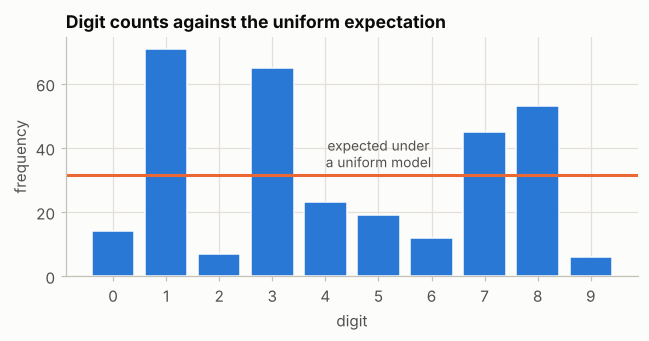

In [56]:
# EXTRA (d): chi-square goodness-of-fit test of the digit frequencies against a uniform distribution
freq = imanishi["Frequency"].to_numpy(float)
n_digits = freq.sum()
expected_digit = n_digits / 10
stat_digits, p_digits = stats.chisquare(freq)
rng = np.random.default_rng(182)
simulated = rng.multinomial(int(n_digits), [0.1] * 10, size=200_000)
sim_stat = ((simulated - expected_digit) ** 2 / expected_digit).sum(axis=1)
print(f"{int(n_digits)} digits, expected count per digit {expected_digit:.1f}; chi-square {stat_digits:.2f} with 9 degrees of freedom, p-value {p_digits:.2e}")
print(f"simulation under the uniform model: largest of 200,000 statistics {sim_stat.max():.1f}, 99.9th percentile {np.percentile(sim_stat, 99.9):.1f}, share at or above the observed {np.mean(sim_stat >= stat_digits):.5f}")
print(f"effect size w = sqrt(chi-square / N) = {np.sqrt(stat_digits / n_digits):.3f}")
print(pd.DataFrame({"digit": imanishi["Digit"], "observed": freq.astype(int), "expected": expected_digit, "Pearson residual": (freq - expected_digit) / np.sqrt(expected_digit),
                    "share of the statistic": (freq - expected_digit) ** 2 / expected_digit / stat_digits}).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(imanishi["Digit"].astype(str), freq, color=PALETTE[0], edgecolor=SURFACE)
ax.axhline(expected_digit, color=PALETTE[1], lw=2)
ax.text(5, expected_digit + 2.5, "expected under\na uniform model", color=INK_SOFT, ha="center", fontsize=9)
ax.set_xlabel("digit"); ax.set_ylabel("frequency")
ax.set_title("Digit counts against the uniform expectation")
plt.tight_layout()
plt.show()

**Analysis of extra (d).**

* The 315 digits have $\chi^2 = 174.37$ with 9 degrees of freedom and a p-value of $7.6 \times 10^{-33}$. In the 200,000 simulated sets of 315 uniform digits the largest statistic is 42.3, the 99.9th percentile 28.1, and none reaches 174.4. The effect size $w = \sqrt{\chi^2/N} = 0.744$ is large.
* The residuals show where the data differ from a uniform model: digit 1 (71 against 31.5 expected, residual +7.04, 28.4% of the statistic), digit 3 (+5.97, 20.4%), digit 9 (-4.54, 11.8%), digit 2 (-4.37, 10.9%) and digit 8 (+3.83, 8.4%). The digit 4 is closest to the expectation (-1.51).
* This rejects the model "every digit equally likely", very clearly. It does not say *why* the digits are unevenly distributed. A uniform distribution is the right null model for the last digit of a fine measurement, not for every digit of a number, so the test is only as good as the null model; the notebook uses the data as a statistical exercise and does not judge the case from which the book takes them.

---
## 10. Multi-arm bandit algorithm

*Book section: "Multi-Arm Bandit Algorithm" (epsilon-greedy algorithm, Thompson's sampling). The section has no code.*

### Summary

* A traditional A/B test collects data by a fixed design to answer one question (which of A and B is better?) and the experiment is over when the answer is in. That is a poor fit for many web situations: the test has to be run until its planned size is reached even if one version is already clearly worse (the visitors who see it are a cost), the answer is only used afterwards, and with many versions (several headlines, prices, layouts) a fixed design is wasteful.
* **Multi-arm bandit** algorithms change the experiment while it runs. The name comes from a gambler facing a row of slot machines ("one-armed bandits") with different, unknown payout rates: each pull of an arm yields information and a reward, and the gambler must decide again and again whether to try an arm that looks worse in order to learn more (**exploration**) or to use the arm that looks best (**exploitation**).
* In the **epsilon-greedy** algorithm a random number decides every visitor's treatment: with probability $\epsilon$ the visitor gets a randomly chosen version (a coin flip between A and B), with probability $1-\epsilon$ the version that has had the best response so far. With $\epsilon = 1$ this is a pure A/B test; with $\epsilon$ near 0 it is nearly pure exploitation; the rest of the traffic is shifted gradually to the better version.
* **Thompson's sampling** is a Bayesian variant. It keeps for every version a probability distribution of its response rate, updated with every new visitor; for each new visitor it draws one value from every distribution and shows the version with the highest draw. Versions that probably are better are chosen more often, and the uncertain ones still get traffic.
* The point of bandits is that they reach a decision faster, with fewer visitors on the worse versions, and extend naturally to many arms. The price is that the data come from an adaptive design, which makes the usual significance tests harder to apply (extra 10(c)).

### Theory

**The bandit problem.** There are $K$ arms with unknown success probabilities $\mu_1, \dots, \mu_K$, best value $\mu^* = \max_k \mu_k$. At each step $t = 1, \dots, T$ a policy picks an arm $a_t$ using the history and observes a reward. Its **(pseudo-)regret** is the expected reward lost compared with always playing the best arm,
$$\mathrm{Regret}(T) = \sum_{t=1}^{T}\bigl(\mu^* - \mu_{a_t}\bigr).$$
A fixed equal split (the A/B test) has regret growing linearly, $T\sum_k(\mu^*-\mu_k)/K$. Epsilon-greedy with a fixed $\epsilon$ also grows linearly, because a share $\epsilon$ of the visitors is always explored. With a schedule $\epsilon_t \propto 1/t$ (or with Thompson sampling or an upper-confidence-bound rule) the regret grows only like $\log T$, which is the best possible order (Lai and Robbins, 1985; Auer, Cesa-Bianchi and Fischer, 2002).

**Thompson sampling for conversions.** With a uniform prior, after $s_k$ successes and $f_k$ failures of arm $k$ the posterior of $\mu_k$ is the beta distribution $\mathrm{Beta}(1 + s_k, 1 + f_k)$. At each step draw $\tilde\mu_k \sim \mathrm{Beta}(1 + s_k, 1 + f_k)$ for every arm and play $a_t = \arg\max_k \tilde\mu_k$ (Thompson, 1933). The probability that arm $k$ is played equals the posterior probability that it is the best arm.

**Exploration and inference.** The observed rate of an arm that is played less when it looks bad is estimated from less data, and the stopping of data collection depends on the values seen: the sample mean of an adaptively sampled arm is *biased*, and the naive standard errors and tests of a fixed design are not valid as they stand. The experiment of 10(c) measures both.

### Extra experiments

This section has no code in the book. The experiments simulate three versions of a page with conversion rates of 3%, 4% and 6% and 10,000 visitors, repeated 400 times; the visitors arrive one at a time and the version of each visitor is chosen by a policy. The generator is seeded in each cell; the simulation function `run_bandit` is defined in the first cell and reused in the others.

**(a) Four ways to allocate the traffic.** The policies are: a **fixed equal split** (round robin), **explore, then greedy** (equal split for the first 1,000 visitors, then at every later visitor the version with the best observed rate so far, which keeps being updated), **epsilon-greedy** with $\epsilon = 0.1$ and **Thompson sampling** with uniform priors. The cell reports the expected number of conversions, the regret against always showing the 6% version, and the share of visitors that saw the best version, and draws the regret and the allocation over time. The regret is computed from the *true* rates of the versions that were shown (the expected loss), not from the conversions that happened to occur; for a policy that does not look at the data, such as the fixed split, it therefore has no spread at all.

true rates [0.03, 0.04, 0.06], 10,000 visitors, 400 repetitions; always showing the best version gives 600 conversions
                       policy  expected conversions  regret  sd of the regret  share of visitors on the best version  visitors on the 3% version  best observed rate is the true best  regret, runs ending on a wrong version  regret, other runs
            fixed equal split               433.320 166.680             0.000                                  0.333                    3334.000                                1.000                                     NaN             166.680
   explore 1,000, then greedy               573.766  26.234            36.691                                  0.886                     347.378                                0.960                                 196.544              19.138
epsilon-greedy, epsilon = 0.1               556.898  43.102            47.025                                  0.813                     574.558           

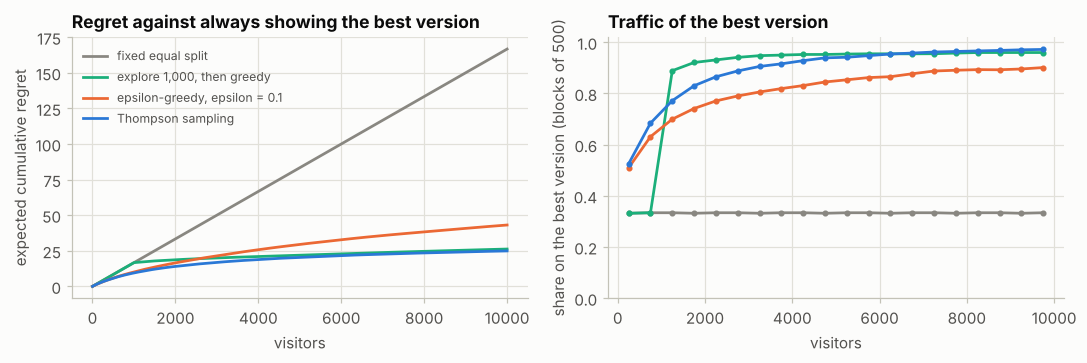

In [57]:
# EXTRA (a): a fixed split, explore-then-greedy, epsilon-greedy and Thompson sampling on three versions of a page
true_rates = np.array([0.03, 0.04, 0.06])
horizon, reps = 10_000, 400


def run_bandit(policy, seed, rates=true_rates, horizon=horizon, reps=reps, epsilon=0.1, explore_steps=1000):
    """Simulate `reps` independent experiments with `horizon` visitors each; return the chosen arm at every step and the final wins and pulls."""
    rng = np.random.default_rng(seed)
    k = len(rates)
    wins, pulls = np.zeros((reps, k)), np.zeros((reps, k))
    chosen = np.zeros((reps, horizon), dtype=np.int8)
    rows = np.arange(reps)
    for t in range(horizon):
        if policy == "fixed":
            arm = np.full(reps, t % k)
        else:
            observed = np.where(pulls > 0, wins / np.maximum(pulls, 1), 1.0) + 1e-9 * rng.random((reps, k))    # untried versions look perfect; random tie-breaking
            if policy == "greedy_after":
                arm = np.full(reps, t % k) if t < explore_steps else observed.argmax(axis=1)
            elif policy == "epsilon":
                eps = epsilon(t) if callable(epsilon) else epsilon
                arm = np.where(rng.random(reps) < eps, rng.integers(k, size=reps), observed.argmax(axis=1))
            elif policy == "thompson":
                arm = rng.beta(1 + wins, 1 + pulls - wins).argmax(axis=1)
        reward = rng.random(reps) < rates[arm]
        wins[rows, arm] += reward
        pulls[rows, arm] += 1
        chosen[:, t] = arm
    return chosen, wins, pulls


policies = {"fixed equal split": ("fixed", {}), "explore 1,000, then greedy": ("greedy_after", {}), "epsilon-greedy, epsilon = 0.1": ("epsilon", {"epsilon": 0.1}),
            "Thompson sampling": ("thompson", {})}
best = int(true_rates.argmax())
results = {}
for seed, (name, (policy, options)) in enumerate(policies.items(), start=191):
    chosen, wins, pulls = run_bandit(policy, seed, **options)
    results[name] = {"chosen": chosen, "wins": wins, "pulls": pulls}
rows = []
for name, r in results.items():
    chosen, wins, pulls = r["chosen"], r["wins"], r["pulls"]
    regret = (true_rates[best] - true_rates[chosen]).sum(axis=1)
    observed_rate = wins / np.maximum(pulls, 1)
    wrong = observed_rate.argmax(axis=1) != best
    rows.append({"policy": name, "expected conversions": (true_rates[chosen]).sum(axis=1).mean(), "regret": regret.mean(), "sd of the regret": regret.std(ddof=1),
                 "share of visitors on the best version": np.mean(chosen == best), "visitors on the 3% version": pulls[:, 0].mean(),
                 "best observed rate is the true best": np.mean(~wrong),
                 "regret, runs ending on a wrong version": regret[wrong].mean() if wrong.any() else np.nan, "regret, other runs": regret[~wrong].mean()})
print(f"true rates {true_rates.tolist()}, {horizon:,} visitors, {reps} repetitions; always showing the best version gives {true_rates[best] * horizon:.0f} conversions")
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
colors = [MUTED, PALETTE[2], PALETTE[1], PALETTE[0]]
for color, (name, r) in zip(colors, results.items()):
    axes[0].plot(np.arange(1, horizon + 1), (true_rates[best] - true_rates[r["chosen"]]).cumsum(axis=1).mean(axis=0), color=color, label=name, lw=1.8)
    axes[1].plot(np.arange(250, horizon + 1, 500), (r["chosen"] == best).reshape(reps, -1, 500).mean(axis=(0, 2)), color=color, label=name, lw=1.8, marker="o", ms=3)
axes[0].set_xlabel("visitors"); axes[0].set_ylabel("expected cumulative regret"); axes[0].set_title("Regret against always showing the best version")
axes[1].set_xlabel("visitors"); axes[1].set_ylabel("share on the best version (blocks of 500)"); axes[1].set_title("Traffic of the best version"); axes[1].set_ylim(0, 1.02)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The **fixed equal split** shows each version to a third of the visitors: 433.3 expected conversions of the 600 that the best version would give, a regret of 166.7, growing linearly in the figure.
* **Thompson sampling** has a regret of 24.9, 575.1 expected conversions, 89.3% of the visitors on the best version and only 350 on the worst (against 3,334); its regret has a standard deviation of 12.3 and the highest observed rate belonged to the best version in all repetitions. **Explore, then greedy** has a similar average (26.2) but a standard deviation of 36.7. The average is a mixture: in the 96% of the runs that end with the best version having the highest observed rate the regret is 19.1 (the exploration phase alone costs $1000 \times (0.06 - 0.0433) = 16.7$), and in the other 4% (16 of 400 runs), which end on a worse version, it is 196.5. **Epsilon-greedy** with $\epsilon = 0.1$ has a regret of 43.1 (standard deviation 47.0), 81.3% of the visitors on the best version and 575 on the worst, of which about 333 ($0.1 \times 10{,}000/3$) are the random 10% of the visitors; in 3.5% of the runs (14 of 400) the highest observed rate belongs to a worse version, and their regret is 209.4 against 37.1 for the others.
* Relative to the fixed split the regret is lower by 85% (Thompson), 84% (explore, then greedy) and 74% (epsilon-greedy). In the figure the regret of the fixed split keeps rising with a constant slope, whereas the regret of the others flattens (epsilon-greedy keeps a small slope, $0.1 \times 0.0167$ per visitor), and the share of the best version rises towards 90% and more.
* The price of this efficiency is that the comparison of the versions is no longer a randomized experiment with equal groups; extra 10(c) shows what happens to the inference.

**(b) The choice of $\epsilon$.** The same simulation for epsilon-greedy with $\epsilon$ = 0.01, 0.05, 0.1, 0.2 and 0.3, and with a decaying exploration rate $\epsilon_t = \min(1, 50/(t+1))$, reporting the regret after 1,000 and after 10,000 visitors.

In [58]:
# EXTRA (b): regret of epsilon-greedy as a function of epsilon, after 1,000 and after 10,000 visitors
rows = []
schedules = [(f"epsilon = {e}", e) for e in (0.01, 0.05, 0.1, 0.2, 0.3)] + [("epsilon_t = min(1, 50 / (t + 1))", lambda t: min(1.0, 50 / (t + 1)))]
for seed, (name, epsilon) in enumerate(schedules, start=201):
    chosen, wins, pulls = run_bandit("epsilon", seed, epsilon=epsilon)
    step_regret = (true_rates[best] - true_rates[chosen]).cumsum(axis=1)
    rows.append({"policy": name, "regret after 1,000": step_regret[:, 999].mean(), "regret after 10,000": step_regret[:, -1].mean(),
                 "share on the best version": np.mean(chosen == best), "best observed rate is the true best": np.mean((wins / np.maximum(pulls, 1)).argmax(axis=1) == best)})
rows.append({"policy": "Thompson sampling (extra 10(a))", "regret after 1,000": np.nan, "regret after 10,000": np.nan, "share on the best version": np.nan, "best observed rate is the true best": np.nan})
thompson = results["Thompson sampling"]
cumulative = (true_rates[best] - true_rates[thompson["chosen"]]).cumsum(axis=1)
rows[-1] = {"policy": "Thompson sampling (extra 10(a))", "regret after 1,000": cumulative[:, 999].mean(), "regret after 10,000": cumulative[:, -1].mean(),
            "share on the best version": np.mean(thompson["chosen"] == best), "best observed rate is the true best": np.mean((thompson["wins"] / np.maximum(thompson["pulls"], 1)).argmax(axis=1) == best)}
print(pd.DataFrame(rows).round(3).to_string(index=False))

                          policy  regret after 1,000  regret after 10,000  share on the best version  best observed rate is the true best
                  epsilon = 0.01              11.582               83.799                      0.635                                0.722
                  epsilon = 0.05              11.761               52.369                      0.768                                0.900
                   epsilon = 0.1               9.947               38.899                      0.833                                0.980
                   epsilon = 0.2               9.869               46.801                      0.804                                0.992
                   epsilon = 0.3               9.898               57.438                      0.767                                0.998
epsilon_t = min(1, 50 / (t + 1))               8.749               39.146                      0.822                                0.878
 Thompson sampling (extra 10(a))  

**Analysis of extra (b).**

* After 1,000 visitors the epsilon-greedy variants with a fixed $\epsilon$ have a regret of 9.9 to 11.8 (a fixed split would have $1000 \times 0.0167 = 16.7$), the decaying schedule 8.7 and Thompson sampling 9.4. After 10,000 the differences are large: 83.8 for $\epsilon = 0.01$, 52.4 for 0.05, 38.9 for 0.1, 46.8 for 0.2, 57.4 for 0.3, 39.1 for the decaying rate and 24.9 for Thompson sampling.
* Too little exploration costs through the wrong choice of version: with $\epsilon = 0.01$ the highest observed rate belongs to the best version in only 72% of the repetitions and the share of the best version is 63.5%. Too much costs steadily: for $\epsilon = 0.3$ the regret grows by $(57.4 - 9.9)/9000 = 0.0053$ per visitor between visitors 1,000 and 10,000, close to $\epsilon \times 0.0167 = 0.0050$. A fixed $\epsilon$ always has this linear cost. A decaying rate (8.7 and 39.1) is the best at 1,000 visitors but ends no better than $\epsilon = 0.1$; this fits with the fact that with so few early random draws the algorithm settles on a wrong version in some repetitions (the best observed rate is the right one in 87.8% of them).
* The value $\epsilon = 0.1$ also appears in 10(a), with a regret of 43.1 there and 38.9 here: the seeds differ, and the standard error of a mean over 400 runs is about 2.4 (47.0/20), so differences of this size are Monte Carlo noise.
* No value of $\epsilon$ is best at both horizons, and none matches Thompson sampling at 10,000 visitors in this setting (24.9). The parameter has to be tuned to the horizon and to the differences between the versions, which are unknown in advance.

**(c) What adaptive allocation does to estimation and testing.** 4,000 visitors, 2,000 experiments. First, two *identical* versions (both 5%): the usual pooled two-proportion $z$-test is applied to the final counts, and its false positive rate is measured for the fixed split and for Thompson sampling. Second, two different versions (4% and 6%): the average observed conversion rate of each version at the end and the share of experiments in which the worse version was shown to fewer than 100 visitors.

In [59]:
# EXTRA (c): the naive z-test and the observed rates under a fixed split and under Thompson sampling
rows = []
for name, policy in (("fixed equal split", "fixed"), ("Thompson sampling", "thompson")):
    chosen, wins, pulls = run_bandit(policy, 211, rates=np.array([0.05, 0.05]), horizon=4000, reps=2000)
    p_pool = wins.sum(axis=1) / pulls.sum(axis=1)
    z = (wins[:, 0] / pulls[:, 0] - wins[:, 1] / pulls[:, 1]) / np.sqrt(p_pool * (1 - p_pool) * (1 / pulls[:, 0] + 1 / pulls[:, 1]))
    chosen2, wins2, pulls2 = run_bandit(policy, 212, rates=np.array([0.04, 0.06]), horizon=4000, reps=2000)
    observed2 = wins2 / pulls2
    rows.append({"policy": name, "identical versions: z-test rejects at 5%": np.mean(np.abs(z) > 1.96), "4% version: mean observed rate": observed2[:, 0].mean(),
                 "6% version: mean observed rate": observed2[:, 1].mean(), "visitors on the 4% version": pulls2[:, 0].mean(), "share of experiments with fewer than 100 on the 4% version": np.mean(pulls2[:, 0] < 100)})
print(f"standard error of a rate near 0.05 with 2,000 experiments: {np.sqrt(0.05 * 0.95 / 2000):.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

standard error of a rate near 0.05 with 2,000 experiments: 0.0049
           policy  identical versions: z-test rejects at 5%  4% version: mean observed rate  6% version: mean observed rate  visitors on the 4% version  share of experiments with fewer than 100 on the 4% version
fixed equal split                                    0.0555                          0.0399                          0.0601                   2000.0000                                                       0.000
Thompson sampling                                    0.0940                          0.0347                          0.0596                    559.0705                                                       0.025


**Analysis of extra (c).**

* **Identical versions (5% each).** The usual pooled $z$-test applied to the final counts rejects in 5.55% of the experiments with the fixed split (the standard error is 0.49 percentage points, so this is the nominal rate) but in 9.40% with Thompson sampling: nearly twice the nominal rate, although there is no difference.
* **Versions with 4% and 6%.** With the fixed split the observed rates are unbiased (3.99% and 6.01%). With Thompson sampling the observed rate of the worse version averages 3.47%, 0.53 points or 13% below its true value, whereas the better version is hardly affected (5.96%). The worse version gets 559 of the 4,000 visitors on average, and fewer than 100 in 2.5% of the experiments. A plausible reading: a version with a bad start is shown less often, so the bad start is not averaged out by later data.
* The consequence is that a bandit is a tool for *making* a decision cheaply, not for *proving* a difference. If an estimate or a test is needed from bandit data, the analysis has to account for the adaptive design; otherwise the standard errors and tests of a fixed design cannot be trusted. One option is to use the bandit to allocate traffic and a separately randomized comparison to quantify the winner.

---
## 11. Power and sample size

*Book section: "Power and Sample Size" (sample size, effect size, power, significance level). The code of the script computes the sample sizes for two conversion rates.*

### Summary

* If you run a test and find no significant difference, it matters whether the test could have found one. The **power** of a test is the probability that it detects an effect of a given size, if the effect exists. A test with low power is a waste of effort: a real effect will probably go unnoticed, and a "significant" result from it is less reliable than it seems (extra 11(c)).
* Power depends on four connected quantities: the **effect size** (how big a difference one wants to detect), the **sample size**, the **significance level** $\alpha$, and the power itself. If three are fixed, the fourth follows. The usual question runs the other way round: *how large must the sample be to detect an effect of this size, with this power and this $\alpha$?* A smaller effect needs a larger sample; so does a higher power or a smaller $\alpha$.
* The book explains the idea with a simulation-like thought experiment (a "power calculation" by trial) and then with software. For a web test the effect size is often given as an improvement of the conversion rate, and the answer is the number of visitors per group.
* The example of the script: the current conversion rate is 1.1%. To detect an increase to 1.21% (a relative improvement of 10%) with power 0.8 and a one-sided test at the 5% level, the script computes a sample size of 116,602.391 per group; for an increase to 1.65% (a relative improvement of 50%), 5,488.408 per group. The effect is five times larger in the second case (a 50% against a 10% improvement) and the sample size 21 times smaller, which shows how fast the requirement grows as the effect shrinks.
* The calculation needs a guess for the effect size; if the guess is too optimistic the test will be underpowered. Software (`statsmodels` in the script) does the arithmetic.

### Theory

**Power of the $z$-test.** For two groups of $n$ observations with standard deviation $\sigma$ and a true difference of means $\delta$, the one-sided $z$-test at level $\alpha$ rejects when $z > z_{1-\alpha}$, where $z \sim N\bigl(\delta/(\sigma\sqrt{2/n}),\, 1\bigr)$ under the alternative. Hence
$$\text{power} = \Phi\!\left(\frac{\delta}{\sigma\sqrt{2/n}} - z_{1-\alpha}\right), \qquad n = \frac{2\sigma^2\,(z_{1-\alpha} + z_{1-\beta})^2}{\delta^2}$$
per group for power $1-\beta$. For a two-sided test replace $z_{1-\alpha}$ by $z_{1-\alpha/2}$. The sample size grows as $1/\delta^2$: half the effect needs four times the data. A common rule of thumb for 80% power at a two-sided 5% level is $n \approx 16\,\sigma^2/\delta^2$ per group (Lehr, 1992).

**Proportions and Cohen's $h$.** For two proportions $p_1, p_2$ the variance depends on the proportions. The direct formula uses $\sigma^2 = p(1-p)$ at both values. The transformation $\varphi = 2\arcsin\sqrt{p}$ stabilizes the variance ($\operatorname{Var}\hat\varphi \approx 1/n$), and the standardized difference $h = \varphi_1 - \varphi_2$, **Cohen's $h$** (Cohen, 1988), plays the role of $\delta/\sigma$: $n = 2(z_{1-\alpha} + z_{1-\beta})^2/h^2$. `sm.stats.proportion_effectsize(p1, p2)` returns $h$. The script then uses `TTestIndPower`, the power of the *two-sample $t$-test* for an effect size $h$; with samples of thousands the $t$ and the normal distribution are identical for practical purposes.

**Effect size, not significance.** Power is a property of the *design and the true effect*, not of the data after the fact. Computing the "observed power" from the p-value of a finished experiment adds no information.

**Winner's curse.** If an experiment has low power, the effects that do reach significance are those whose estimate was, by chance, much larger than the truth: the significant estimates **exaggerate** the effect (Gelman and Carlin's *type M error*), and a few have the wrong sign (*type S error*). This is the link between power and the reliability of "significant" findings (extra 11(c); Gelman and Carlin, 2014).

### Book code

The script first computes Cohen's $h$ for an increase of the conversion rate from 1.1% to 1.21%, then asks for the sample size per group at which a one-sided test at the 5% level has a power of 0.8.

In [60]:
# BOOK CODE (Power and Sample Size): the sample size to detect an increase of the conversion rate from 1.1% to 1.21%
# statsmodels has a number of methods for power calculation
#
# see e.g.: https://machinelearningmastery.com/statistical-power-and-power-analysis-in-python/

effect_size = sm.stats.proportion_effectsize(0.0121, 0.011)
analysis = sm.stats.TTestIndPower()
result = analysis.solve_power(effect_size=effect_size,
                              alpha=0.05, power=0.8, alternative='larger')
print('Sample Size: %.3f' % result)

Sample Size: 116602.391


In [61]:
# BOOK CODE (Power and Sample Size): the sample size to detect an increase of the conversion rate from 1.1% to 1.65%
effect_size = sm.stats.proportion_effectsize(0.0165, 0.011)
analysis = sm.stats.TTestIndPower()
result = analysis.solve_power(effect_size=effect_size,
                              alpha=0.05, power=0.8, alternative='larger')
print('Sample Size: %.3f' % result)

Sample Size: 5488.408


**Output analysis.**

* To detect a rise of the conversion rate from 1.1% to 1.21% (Cohen's $h = 0.0103$) with power 0.8 and a one-sided 5% test the script returns 116,602.391 visitors per group, so at least 116,603 in each of the two groups (about 233,000 in all). For 1.1% to 1.65% ($h = 0.0475$) it returns 5,488.408, so 5,489 per group.
* The requirement for an effect that is five times larger (the relative improvement of 50% against 10%) is 21 times smaller: $(0.04747/0.0103)^2 = 21.2 = 116{,}602/5{,}488$. The sample size is proportional to $1/h^2$ (extra 11(b)), and for the arcsine effect size the ratio of the effects is 4.6 rather than 5. The fractional values come from the numerical root-finder; one rounds up.
* The calculation answers "how many visitors does a test need to find an improvement of *this* size?", and it needs a guess for the size. For the book's experiment of section 4 (about 23,000 visitors per price), a 10% improvement could not have been detected reliably (extras 4(b) and 11(b)).

### Extra experiments

**(a) The sample size by several methods, and a check by simulation.** The cell computes the sample size per group for the two scenarios of the script by: the `TTestIndPower` of the script, `NormalIndPower` (the $z$-test), the direct formula for two proportions, the arcsine formula with Cohen's $h$, and the rule of thumb of the theory block (two-sided). It then checks the number of the script by simulation: 20,000 experiments with exactly that many visitors per group, tested with the one-sided pooled two-proportion $z$-test at the 5% level, with the true rates (power) and with equal rates (false positive rate).

In [62]:
# EXTRA (a): the sample size per group for 80% power by five methods, and its check by simulation
from statsmodels.stats.power import NormalIndPower

za, zb = stats.norm.ppf(0.95), stats.norm.ppf(0.8)
rows, planned, effect_sizes = [], {}, {}
for label, (p_new, p_old) in {"1.1% to 1.21%": (0.0121, 0.011), "1.1% to 1.65%": (0.0165, 0.011)}.items():
    h = sm.stats.proportion_effectsize(p_new, p_old)
    p_bar = (p_new + p_old) / 2
    n_direct = (za * np.sqrt(2 * p_bar * (1 - p_bar)) + zb * np.sqrt(p_new * (1 - p_new) + p_old * (1 - p_old))) ** 2 / (p_new - p_old) ** 2
    planned[label] = (p_new, p_old, sm.stats.TTestIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8, alternative="larger"))
    effect_sizes[label] = h
    rows.append({"scenario": label,
                 "TTestIndPower (the script)": planned[label][2],
                 "NormalIndPower": NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8, alternative="larger"),
                 "direct formula": n_direct,
                 "arcsine formula 2 (za + zb)^2 / h^2": 2 * (za + zb) ** 2 / h ** 2,
                 "TTestIndPower, two-sided": sm.stats.TTestIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8, alternative="two-sided"),
                 "rule of thumb 16 p(1-p) / delta^2 (two-sided)": 16 * p_old * (1 - p_old) / (p_new - p_old) ** 2})
print("Cohen's h:", {label: round(float(h), 5) for label, h in effect_sizes.items()})
print(pd.DataFrame(rows).set_index("scenario").round(1).T.to_string())

rng = np.random.default_rng(221)
reps_power = 20_000
rows = []
for label, (p_new, p_old, n_plan) in planned.items():
    n_group = int(np.ceil(n_plan))
    for setting, (q1, q2) in {"true rates": (p_new, p_old), "equal rates (1.1%)": (p_old, p_old)}.items():
        x1, x2 = rng.binomial(n_group, q1, size=reps_power), rng.binomial(n_group, q2, size=reps_power)
        pooled_rate = (x1 + x2) / (2 * n_group)
        z = (x1 - x2) / n_group / np.sqrt(pooled_rate * (1 - pooled_rate) * 2 / n_group)
        rate = np.mean(z > za)
        rows.append({"scenario": label, "visitors per group": n_group, "setting": setting, "share of significant tests": rate, "standard error": np.sqrt(rate * (1 - rate) / reps_power)})
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

Cohen's h: {'1.1% to 1.21%': 0.0103, '1.1% to 1.65%': 0.04747}
scenario                                       1.1% to 1.21%  1.1% to 1.65%
TTestIndPower (the script)                          116602.4         5488.4
NormalIndPower                                      116601.7         5487.7
direct formula                                      116666.3         5542.2
arcsine formula 2 (za + zb)^2 / h^2                 116601.7         5487.7
TTestIndPower, two-sided                            148028.8         6967.7
rule of thumb 16 p(1-p) / delta^2 (two-sided)       143854.5         5754.2

     scenario  visitors per group            setting  share of significant tests  standard error
1.1% to 1.21%              116603         true rates                      0.8002          0.0028
1.1% to 1.21%              116603 equal rates (1.1%)                      0.0515          0.0016
1.1% to 1.65%                5489         true rates                      0.7964          0.0028
1.1% to 1.65%   

**Analysis of extra (a).**

* The four one-sided methods agree to within the accuracy of the approximations. `TTestIndPower` (the script) needs 116,602.4 and 5,488.4 visitors per group; `NormalIndPower` 116,601.7 and 5,487.7 (the $t$ and the normal distribution are practically identical at these sizes), and the arcsine formula gives the same as `NormalIndPower` since it is the same formula. The direct formula with the two proportions' own variances gives 116,666.3 and 5,542.2, 0.05% and 1.0% more.
* The other two columns answer a different question. A two-sided test needs 148,029 and 6,968 per group, 27% more in both scenarios. The rule of thumb $16\,p(1-p)/\delta^2$ (two-sided) gives 143,855 (2.8% below the exact value) and 5,754 (17% below): it uses the variance at the baseline rate only, which is too small when the improved rate is 50% higher.
* **Check by simulation.** With 116,603 visitors per group 80.02% of the 20,000 experiments with the true rates are significant (standard error 0.28 percentage points) and 5.15% of those with equal rates (0.9 standard errors from 5%). With 5,489 per group the power is 79.64%, 1.3 standard errors below 80%, which agrees with the slightly larger sample size of the direct formula (5,542); the false positive rate is 4.94%.

**(b) Power curves and what drives the sample size.** For a baseline conversion rate of 1.1% the cell draws the power of the one-sided 5% test as a function of the sample size for relative improvements of 10%, 20% and 50% (the $z$-test power from `NormalIndPower`), and the sample size for 80% power as a function of the relative improvement on log scales. The table gives the sample size for several improvements, for a power of 0.9, for a two-sided test and for other baseline rates.

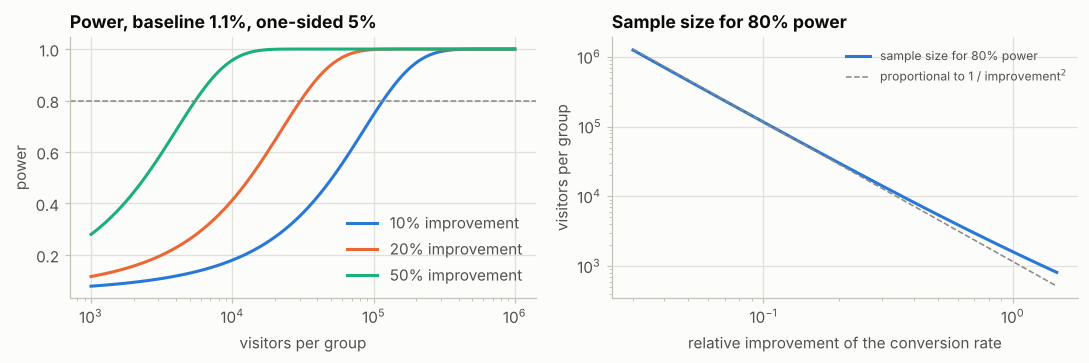

 relative improvement  n for 80% power (baseline 1.1%)  n x improvement^2  n for 90% power  n, two-sided
                0.050                      455,617.826          1,139.045      631,104.795   578,414.502
                0.100                      116,601.715          1,166.017      161,512.340   148,027.840
                0.200                       30,476.020          1,219.041       42,214.244    38,689.820
                0.300                       14,121.745          1,270.957       19,560.914    17,927.793
                0.500                        5,487.731          1,371.933        7,601.400     6,966.767
                1.000                        1,611.412          1,611.412        2,232.068     2,045.715

 baseline rate n for a 10% improvement n x baseline rate
         0.002                 647,438             1,295
         0.011                 116,602             1,283
         0.050                  24,590             1,230
         0.200                   5,1

In [63]:
# EXTRA (b): power curves and the sample size as a function of the effect, the power, the sides and the baseline rate
normal_power = NormalIndPower()


def n_per_group(p_base, relative_lift, power=0.8, alpha=0.05, alternative="larger"):
    h = sm.stats.proportion_effectsize(p_base * (1 + relative_lift), p_base)
    return normal_power.solve_power(effect_size=h, alpha=alpha, power=power, alternative=alternative)


fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
grid_n = np.logspace(3, 6, 120)
for color, lift in zip(PALETTE, (0.1, 0.2, 0.5)):
    h = sm.stats.proportion_effectsize(0.011 * (1 + lift), 0.011)
    axes[0].plot(grid_n, normal_power.power(effect_size=h, nobs1=grid_n, alpha=0.05, alternative="larger"), color=color, label=f"{lift:.0%} improvement")
axes[0].axhline(0.8, color=MUTED, lw=1, ls="--")
axes[0].set_xscale("log"); axes[0].set_xlabel("visitors per group"); axes[0].set_ylabel("power"); axes[0].set_title("Power, baseline 1.1%, one-sided 5%"); axes[0].legend()
lifts = np.logspace(np.log10(0.03), np.log10(1.5), 60)
axes[1].loglog(lifts, [n_per_group(0.011, l) for l in lifts], color=PALETTE[0], label="sample size for 80% power")
axes[1].loglog(lifts, n_per_group(0.011, 0.1) * (0.1 / lifts) ** 2, color=MUTED, lw=1, ls="--", label=r"proportional to 1 / improvement$^2$")
axes[1].set_xlabel("relative improvement of the conversion rate"); axes[1].set_ylabel("visitors per group"); axes[1].set_title("Sample size for 80% power"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for lift in (0.05, 0.1, 0.2, 0.3, 0.5, 1.0):
    n80 = n_per_group(0.011, lift)
    rows.append({"relative improvement": lift, "n for 80% power (baseline 1.1%)": n80, "n x improvement^2": n80 * lift ** 2, "n for 90% power": n_per_group(0.011, lift, power=0.9),
                 "n, two-sided": n_per_group(0.011, lift, alternative="two-sided")})
print(pd.DataFrame(rows).round(3).to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
print()
baseline_table = pd.DataFrame([{"baseline rate": b, "n for a 10% improvement": n_per_group(b, 0.1), "n x baseline rate": n_per_group(b, 0.1) * b} for b in (0.002, 0.011, 0.05, 0.2)])
baseline_table["n for a 10% improvement"] = baseline_table["n for a 10% improvement"].map("{:,.0f}".format)
baseline_table["n x baseline rate"] = baseline_table["n x baseline rate"].map("{:,.0f}".format)
print(baseline_table.to_string(index=False))

**Analysis of extra (b).**

* **The curves.** The power rises from near the 5% level to 1; it crosses 0.8 near 5,000 visitors per group for a 50% improvement, near 30,000 for 20% and near 117,000 for 10%. On the log-log scale the sample size for 80% power is a straight line of slope about -2: sample size is proportional to $1/\text{effect}^2$.
* **The table.** The relative improvements of 5%, 10%, 20%, 30%, 50% and 100% need 455,618, 116,602, 30,476, 14,122, 5,488 and 1,611 visitors per group. Halving the improvement from 10% to 5% multiplies the requirement by 3.9, from 20% to 10% by 3.8: close to the factor 4. The product $n \times \text{improvement}^2$ is about 1,140 to 1,220 up to 20% and then rises (1,611 for 100%), because the arcsine scale is not exactly proportional for large improvements.
* **Power and sides.** A power of 0.9 needs 1.385 times as many visitors as a power of 0.8, and a two-sided test needs 1.27 times as many as a one-sided test, whatever the effect.
* **The baseline.** For a 10% improvement the requirement is about 647,000 per group at a baseline of 0.2%, 117,000 at 1.1%, 24,600 at 5% and 5,100 at 20%. The product with the baseline rate is about constant for small rates (1,295, 1,283, 1,230, 1,025): rare events need many more visitors.

**(c) The exaggeration of significant effects.** A true effect of $d = 0.2$ standard deviations (and, for comparison, of $d = 0.5$) is studied with two groups of $n$ = 20, 50, 100, 200, 400 and 800 observations. For every $n$ the cell simulates 200,000 experiments, tests each with the two-sided pooled $t$-test at the 5% level, and reports the power, the average estimated effect among the *significant* experiments divided by the true effect (the exaggeration ratio), and the share of significant experiments whose estimate has the wrong sign. A histogram shows the estimates for $n$ = 50 and $d = 0.2$.

 true d  n per group  power  mean estimate, all  mean |estimate|, significant only (ratio to true d)  wrong sign among significant
    0.2           20 0.0933              0.9975                                               3.7687                        0.0511
    0.2           50 0.1681              1.0037                                               2.4856                        0.0091
    0.2          100 0.2900              0.9998                                               1.8310                        0.0016
    0.2          200 0.5137              0.9995                                               1.3873                        0.0001
    0.2          400 0.8059              1.0001                                               1.1208                        0.0000
    0.2          800 0.9783              0.9986                                               1.0119                        0.0000
    0.5           20 0.3381              1.0007                                    

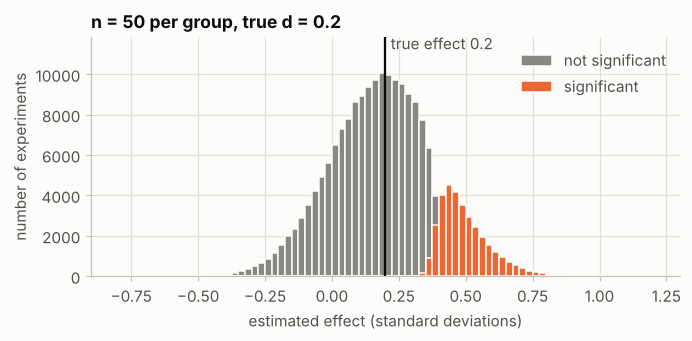

In [64]:
# EXTRA (c): power, exaggeration (type M) and wrong sign (type S) of the significant estimates
rng = np.random.default_rng(222)
experiments = 200_000
rows = []
store = {}
for d in (0.2, 0.5):
    for n in (20, 50, 100, 200, 400, 800):
        dof = 2 * n - 2
        estimate = rng.normal(d, np.sqrt(2 / n), size=experiments)                       # observed difference of the means (true sd 1)
        s = np.sqrt(rng.chisquare(dof, size=experiments) / dof)                           # pooled sample sd
        t = estimate / (s * np.sqrt(2 / n))
        significant = np.abs(t) > stats.t.ppf(0.975, dof)
        store[(d, n)] = (estimate, significant)
        rows.append({"true d": d, "n per group": n, "power": significant.mean(),
                     "mean estimate, all": estimate.mean() / d, "mean |estimate|, significant only (ratio to true d)": np.abs(estimate[significant]).mean() / d,
                     "wrong sign among significant": np.mean(estimate[significant] < 0)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

estimate, significant = store[(0.2, 50)]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
bins = np.linspace(-0.8, 1.2, 81)
ax.hist(estimate[~significant], bins=bins, color=MUTED, edgecolor=SURFACE, label="not significant")
ax.hist(estimate[significant], bins=bins, color=PALETTE[1], edgecolor=SURFACE, label="significant")
ax.axvline(0.2, color=INK, lw=1.5)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.text(0.22, ax.get_ylim()[1] * 0.95, "true effect 0.2", color=INK_SOFT)
ax.set_xlabel("estimated effect (standard deviations)"); ax.set_ylabel("number of experiments"); ax.set_title("n = 50 per group, true d = 0.2"); ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* The estimator is unbiased (the average of all estimates is 0.998 to 1.004 times the true effect in every row), but the estimates that are *significant* are not. For $d = 0.2$ and 20 per group the power is 9.3% and the significant estimates have an average absolute value of 3.77 times the true effect; 5.1% of them have the wrong sign. With 50 per group (power 16.8%) the exaggeration is 2.49 and 0.9% have the wrong sign; with 100 (29.0%), 1.83 and 0.16%; with 200 (51.4%), 1.39; with 400 (80.6%), 1.12; with 800 (97.8%), 1.01.
* For $d = 0.5$ the pattern is the same, shifted: power 33.8%, 69.9%, 94.1% for 20, 50 and 100 per group, exaggeration 1.67, 1.20 and 1.04, and the wrong sign only in 0.07% of the significant results at $n = 20$.
* In the histogram ($n = 50$, $d = 0.2$) the significant experiments (orange) are those whose estimate exceeds about 0.4, twice the true effect: selecting the experiments that pass the threshold keeps the largest estimates. This is why a "significant" finding from a small study should not be taken at its face value, and why the exaggeration is the price of low power, not only the chance of missing an effect (Gelman and Carlin, 2014). Planning the sample size for the effect one cares about (extra 11(a)) is the remedy.

---
## Which test, which question? A decision guide

| Question or data | Tool | Python | Notes from this chapter |
|---|---|---|---|
| Two groups, assigned at random, any statistic | permutation test | shuffle the labels (vectorised in 3(a)) | the Monte Carlo error is $\sqrt{p(1-p)/R}$, 0.011 for 1,000 permutations (3(b)); exact only for the sharp null (2(b)) |
| Two means, independent groups | Welch's $t$-test | `scipy.stats.ttest_ind(equal_var=False)` | by hand = `scipy` = `statsmodels` (5(a)); the pooled test fails with unequal sizes and variances (2(b)) |
| Two groups, heavy tails or skew, small samples | rank test | `scipy.stats.mannwhitneyu` | more power than the $t$-test in the simulation of 5(b) ($t_3$ and lognormal data, 15 per group); for lognormal data the two tests address different questions |
| Before and after on the same subjects | paired $t$-test | `scipy.stats.ttest_rel` | ignoring the pairing: power 0.4% against 67.6% (5(c)) |
| Two proportions | Fisher's exact test, $\chi^2$ or $z$ | `fisher_exact`, `chi2_contingency`, `proportions_ztest` | exact 0.3499, corrected $\chi^2$ 0.3498, $z$ 0.3309 (4(a)) |
| Several means | ANOVA ($F$-test), or Welch's ANOVA | `f_oneway`, `anova_lm`, `anova_oneway` | $F = 2.74$, $p = 0.078$; the classical test rejects 37.9% of true nulls with unequal sizes and variances (8(d)) |
| Which groups differ | Tukey's HSD, or Holm | `scipy.stats.tukey_hsd`, `multipletests` | the verdict on one pair changed with the method, 0.0067 against 0.0531 (8(b)) |
| Two factors | two-way ANOVA with interaction | `smf.ols('y ~ C(a) * C(b)')`, `anova_lm(typ=2)` | a large interaction can hide a main effect (8(c)) |
| Counts in categories | chi-square test; exact or resampling for small counts | `chi2_contingency`, `chisquare` | expected counts of at least 5; the nominal 5% test rejects 11.1% with 1 click expected (9(c)) |
| Many hypotheses | Bonferroni or Holm (FWER), Benjamini-Hochberg (FDR) | `multipletests` | 20 true nulls: 64% chance of a false positive; BH finds 50% of 100 real effects, Bonferroni 15% (6(a), 6(b)) |
| Looking at the results while the test runs | fix the sample size, or a sequential design | - | 20 looks: 24.6% false positives (1(c)) |
| Several versions, cost of the test matters | multi-arm bandit | Thompson sampling (10(a)) | regret 24.9 against 166.7, but the observed rates are biased and a naive test rejects 9.4% (10(c)) |
| How much data? | power analysis | `TTestIndPower`, `NormalIndPower`, `proportion_effectsize` | $n \propto 1/\text{effect}^2$ (11(b)); low power exaggerates significant effects (11(c)) |

---
## Chapter summary

An experiment answers a question by comparing groups that were formed by chance, and the whole chapter is about how to tell a real difference from one that chance can produce. The **A/B test** gives the design: random assignment, one predefined metric, a concurrent control. The **hypothesis test** turns the question into a chance model (the null hypothesis) and asks how unusual the observed result is under it; **resampling** answers by shuffling the data, and the classical tests (the **$t$-test**, **ANOVA**, the **chi-square test**) answer with a reference distribution. The **p-value** is the probability, under the null model, of a result at least as extreme as the one seen; the two errors of a test, false alarms and missed effects, trade off against each other, and **power** and **sample size** are the way to plan an experiment so that it can find the effect that one cares about. Three practical problems recur: many tests (**multiple testing**), the assumptions behind a method (equal variances, expected counts, **degrees of freedom**), and the cost of experimenting, which the **multi-arm bandit** reduces at the price of a harder inference.

### Key takeaways

1. **Randomization removes selection bias.** In the observational comparison the estimate averaged 3.12 for a true effect of 1, in the randomized one 1.00 (1(a)).
2. **A test must be used as designed.** A/A tests reject at the nominal rates (1.0%, 5.1%, 10.0%, 1(b)); peeking 20 times gives 24.6% false positives instead of 5% (1(c)); choosing the direction after the data gives 10.1% (2(a)).
3. **The permutation test needs no distribution, but a Monte Carlo p-value has an error** of $\sqrt{p(1-p)/R}$: 0.011 for the 1,000 permutations of the script, whose 0.121 compares with about 0.135 from many (3(a), 3(b)). It is exact for the sharp null, not for equal means with unequal variances and sizes, where it rejected 26% in one arrangement and 0.15% in the opposite one (2(b)).
4. **The p-value is not the probability that the null hypothesis is true.** It is uniform when the null is true (4(c)); an experiment of 23,739 and 22,588 visitors detects the observed difference in only 11% of repetitions (4(b)); with one true hypothesis in ten and power 0.8, 35% of the significant results are false (4(d)).
5. **Significance is not importance.** A difference of 0.01 standard deviations has $p = 1.5 \times 10^{-12}$ with a million observations per group (4(e)); report the effect with an interval (5(d)).
6. **The classical tests are approximations that must match the data.** Welch by hand equals the libraries (5(a)); in the simulation with 15 per group the rank test had more power for heavy-tailed and lognormal data and 3.6 points less for normal data (5(b)); a paired design analysed as two groups lost nearly all its power, 0.4% against 67.6% with a correlation of 0.9 between the measurements (5(c)).
7. **Many tests inflate false positives:** 64% for 20 true nulls. Bonferroni and Holm hold the family-wise rate at 5% and find 15% of 100 real effects; Benjamini-Hochberg keeps the false discovery proportion at 4.5% and finds 50% (6(a), 6(b), 6(c)).
8. **Degrees of freedom count the free values:** $n - 1$ because the mean was estimated (7(a)), $19 = 3 + 16$ in the ANOVA table (7(b)), and a factor with all its dummies plus an intercept is singular (7(c)).
9. **ANOVA compares the variation between the groups with the variation within them.** For the four pages $F = 2.74$, $p = 0.078$ (the script prints half of both), and the permutation tests on the three equivalent statistics give 0.081 (8(a)); the pairwise verdict depends on the method (8(b)); an interaction can hide a main effect (8(c)); unequal sizes and variances break the $F$-test (8(d)).
10. **The chi-square distribution is a large-count approximation.** The statistic is 1.67 with $p = 0.435$ against the exact 0.482 (9(b)), and the nominal 5% test rejects 11.1% of true nulls with 3 clicks (9(c)).
11. **Bandits save visitors and cost inference.** Thompson sampling has a regret of 24.9 against 166.7 for a fixed split, but the worse version's rate is underestimated by 13% and a naive test rejects 9.4% of true nulls (10(a), 10(c)).
12. **Plan the sample size.** 116,603 visitors per group for a 10% improvement of a 1.1% rate and 5,489 for 50%; the requirement scales as $1/\text{effect}^2$, and with low power the significant estimates exaggerate the effect (3.8 times at 9% power) (11(a), 11(b), 11(c)).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell, with the changes and additions below. Everything else, in particular what the plots look like, may differ in other versions of the libraries.

* **Paths.** The official script reads its data from a folder next to the code. Here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing. The file `imanishi_data.csv` has trailing spaces in the header of its second column (`Frequency  `), which is why the script strips the column names.
* **Seeds.** The official script seeds only some of its cells (`random.seed(1)` before the permutation distributions of sections 3, 4 and 8, the last one without effect, see the next point). The cells that draw random numbers without a seed (the single call of `perm_fun`, the shuffles and the sampling of section 9, the permutations of section 8) start here with `random.seed(...)  # NOT IN THE BOOK` or `np.random.seed(...)  # NOT IN THE BOOK`.
* **`random.seed` does not seed NumPy.** `perm_test` of the ANOVA section shuffles with `np.random.permutation`; the `random.seed(1)` that the script sets before its loop has no effect on it, so the cell adds `np.random.seed(...)`.
* **A change that is needed (`# CHANGED`).** The script takes `four_sessions.groupby('Page').mean().var()[0]`. In recent versions of pandas a Series with a non-integer index no longer falls back to the position for `[0]`, and the line raises a `KeyError`; the cells use `.var().iloc[0]` (the same value, by position), in the observed statistic and in `perm_test`.
* **The last lines of the ANOVA cell print half of the test.** `res.statistic / 2` and `res.pvalue / 2` print $F/2 = 1.3699$ and $p/2 = 0.0388$, whereas `f_oneway` (and the ANOVA table above it) give $F = 2.7398$ and $p = 0.0776$. The $F$ test is already one-sided and $F$ is not a signed statistic, so the halving has no justification. The notebook reproduces the code and says so in the output analysis, and it does not correct the script.
* **The sign of the conversion test.** The observed difference of section 4 is the rate of price A minus that of price B, with 23,739 and 22,588 visitors; `perm_fun(conversion, 23739, 22588)` returns the mean of the *second* group minus that of the first (the comment of the script says that the groups are reversed with respect to the R version). The permutation distribution of this statistic is almost symmetric around 0, so the p-value is hardly affected; extra 4(a) gives the exact value (0.3499) for the question "does price A convert better?".
* **The name `perm_fun` is used twice.** In section 3 (and for the conversions of section 4) `perm_fun(x, nA, nB)` permutes a Series; in section 9 the script defines a different `perm_fun(box)` for the clicks. The second definition replaces the first from there on.
* **Variables are overwritten.** The cell of the chi-square test assigns the array of expected counts to `expected`; the next cell sets it to the list of the script again before it uses it.
* **Fisher's exact test.** The script's comment says that SciPy has Fisher's exact test only for $2\times 2$ tables, points to a separate Python port of the R code that needs a Fortran compiler, and has the call for the click table commented out. In the SciPy version used here (1.16.3) `fisher_exact` also accepts the $2 \times 3$ table; in repeated calls it returned slightly different p-values (about 0.45 to 0.46), so the notebook does not use it for that table and extra 9(b) enumerates the outcomes by hand. Extra 4(a) uses it for the $2\times 2$ table of the conversions.
* **Two-way ANOVA.** The script only has the formula in a comment (`len ~ C(supp) + C(dose) + C(supp):C(dose)` with `anova_lm(typ=2)`); extra 8(c) runs the same kind of model on simulated data.
* **Plot style.** The setup cell sets the `Matplotlib` style globally, so the figures of the book code also have this notebook's style, not the default one. The figure of the chi-square densities starts at $x = 1$, as in the script.
* **Library calls.** `scipy.stats.ttest_ind`, `statsmodels.stats.weightstats.ttest_ind` (as `sm.stats.ttest_ind`), `smf.ols` with `anova_lm`, `stats.f_oneway`, `stats.chi2_contingency`, `sm.stats.proportion_effectsize` and `TTestIndPower` work as in the script; the extras use `stats.tukey_hsd`, `multipletests`, `anova_oneway`, `NormalIndPower`, `proportions_ztest` and `Generator.multivariate_hypergeometric`, which the script does not.
* **License.** The code and the data of the official repository are under the GNU General Public License v3. This repository does not redistribute the data: the notebook downloads it at run time, and the `data` folder is ignored by git.

---
## References

**The book and its code**

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).

**Cited in the text**

* Armitage, P., McPherson, C. K. and Rowe, B. C. (1969). Repeated significance tests on accumulating data. *Journal of the Royal Statistical Society, Series A*, 132(2), 235-244.
* Auer, P., Cesa-Bianchi, N. and Fischer, P. (2002). Finite-time analysis of the multiarmed bandit problem. *Machine Learning*, 47(2-3), 235-256.
* Benjamini, Y. and Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society, Series B*, 57(1), 289-300.
* Chung, E. and Romano, J. P. (2013). Exact and asymptotically robust permutation tests. *The Annals of Statistics*, 41(2), 484-507.
* Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences*, 2nd edition. Lawrence Erlbaum Associates.
* Fisher, R. A. (1922). On the interpretation of $\chi^2$ from contingency tables, and the calculation of P. *Journal of the Royal Statistical Society*, 85(1), 87-94.
* Fisher, R. A. (1935). *The Design of Experiments*. Oliver and Boyd, Edinburgh.
* Gelman, A. and Carlin, J. (2014). Beyond power calculations: assessing Type S (sign) and Type M (magnitude) errors. *Perspectives on Psychological Science*, 9(6), 641-651.
* Hoeffding, W. (1952). The large-sample power of tests based on permutations of observations. *The Annals of Mathematical Statistics*, 23(2), 169-192.
* Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65-70.
* Ioannidis, J. P. A. (2005). Why most published research findings are false. *PLoS Medicine*, 2(8), e124.
* Lai, T. L. and Robbins, H. (1985). Asymptotically efficient adaptive allocation rules. *Advances in Applied Mathematics*, 6(1), 4-22.
* Lehr, R. (1992). Sixteen S-squared over D-squared: a relation for crude sample size estimates. *Statistics in Medicine*, 11(8), 1099-1102.
* Neyman, J. (1923). On the application of probability theory to agricultural experiments. Essay on principles. Section 9. Translated and edited by D. M. Dabrowska and T. P. Speed, *Statistical Science*, 5(4), 465-472 (1990). The Polish original appeared in *Roczniki Nauk Rolniczych*, 10, 1-51 (1923).
* Neyman, J. and Pearson, E. S. (1933). On the problem of the most efficient tests of statistical hypotheses. *Philosophical Transactions of the Royal Society of London, Series A*, 231, 289-337.
* Pearson, K. (1900). On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science* (series 5), 50(302), 157-175.
* Phipson, B. and Smyth, G. K. (2010). Permutation p-values should never be zero: calculating exact p-values when permutations are randomly drawn. *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39.
* Rubin, D. B. (1974). Estimating causal effects of treatments in randomized and nonrandomized studies. *Journal of Educational Psychology*, 66(5), 688-701.
* Satterthwaite, F. E. (1946). An approximate distribution of estimates of variance components. *Biometrics Bulletin*, 2(6), 110-114.
* Thompson, W. R. (1933). On the likelihood that one unknown probability exceeds another in view of the evidence of two samples. *Biometrika*, 25(3-4), 285-294.
* Tukey, J. W. (1949). Comparing individual means in the analysis of variance. *Biometrics*, 5(2), 99-114.
* Wasserstein, R. L. and Lazar, N. A. (2016). The ASA statement on p-values: context, process, and purpose. *The American Statistician*, 70(2), 129-133.
* Welch, B. L. (1947). The generalization of "Student's" problem when several different population variances are involved. *Biometrika*, 34(1-2), 28-35.
* Welch, B. L. (1951). On the comparison of several mean values: an alternative approach. *Biometrika*, 38(3-4), 330-336.
* Yates, F. (1934). Contingency tables involving small numbers and the $\chi^2$ test. *Supplement to the Journal of the Royal Statistical Society*, 1(2), 217-235.

**Libraries**

* The versions of `NumPy`, `pandas`, `SciPy`, `statsmodels` and `Matplotlib` are printed by the setup cell.